# SJ Preprocessing 

**List of Contents:** \
1- Baseline preprocessing for psychometric characterization \
2- Prior stimulus preprocessing\
3- Prior response preprocessing

In [2]:
###############################################################
# Load required libraries
###############################################################

library(tidyverse)
library(readr)
library(broom)
library(DEoptim)
library(openxlsx)
library(readxl)
library(writexl)

###############################################################\
###############################################################
# 1 Baseline preprocessing for psychometric characterization

**List of Contents:** \
1-1 Load raw datasets from the two SJ experimental sessions and merge them into a single dataset \
1-2 Remove trials that should not be included in the analysis \
1-3 Participant level preprocessing with psychometric fits

###############################################################
## 1-1 Load raw datasets from the two TOJ experimental sessions and merge them into a single dataset

In [3]:
# Set the directory where your Excel files are located
setwd("data/SJ_1/")

# List all Excel files in the directory
files <- list.files(pattern = "*.csv")
# Create an empty data frame to store the merged data
data1 <- data.frame()

# Loop through each file and read the desired columns into merged_data
for (file in files) {
  print(file)
  # Read the Excel file
  data <-  read.csv(file)
  
  # Select the desired columns (replace "column1" and "column2" with your actual column names)
  selected_columns <- data[c("participant","TrialType", "button_resp_3.keys","button_resp_3.rt")]
  
  # Append selected_columns to merged_data
  data1 <- rbind(data1, selected_columns)
}

data1$resp <- ifelse(data1$button_resp_3.keys == 0, "synchrony", NA)
data1$resp[data1$button_resp_3.keys == 2] <- "asynchrony"

setwd("..")
setwd("..")

[1] " P01_SJ1.csv"
[1] " P02_SJ1.csv"
[1] " P03_SJ1.csv"
[1] " P04_SJ1.csv"
[1] " P05_SJ1.csv"
[1] " P06_SJ1.csv"
[1] " P07_SJ1.csv"
[1] " P08_SJ1.csv"
[1] " P09_SJ1.csv"
[1] " P10_SJ1.csv"
[1] " P11_SJ1.csv"


In [4]:
# Set the directory where your Excel files are located
setwd("data/SJ_2/")

# List all Excel files in the directory
files <- list.files(pattern = "*.csv")
# Create an empty data frame to store the merged data
data2 <- data.frame()

# Loop through each file and read the desired columns into merged_data
for (file in files) {
  print(file)
  # Read the Excel file
  data <-  read.csv(file)
  
  # Select the desired columns (replace "column1" and "column2" with your actual column names)
  selected_columns <- data[c("participant","TrialType", "button_resp_3.keys","button_resp_3.rt")]
  
  # Append selected_columns to merged_data
  data2 <- rbind(data2, selected_columns)
}

data2$resp <- ifelse(data2$button_resp_3.keys == 2, "synchrony", NA)
data2$resp[data2$button_resp_3.keys == 0] <- "asynchrony"

setwd("..")
setwd("..")

[1] " P12_SJ2.csv"
[1] " P13_SJ2.csv"
[1] " P14_SJ2.csv"
[1] " P15_SJ2.csv"
[1] " P16_SJ2.csv"
[1] " P17_SJ2.csv"
[1] " P18_SJ2.csv"
[1] " P19_SJ2.csv"
[1] " P20_SJ2.csv"
[1] " P21_SJ2.csv"
[1] " P22_SJ2.csv"


In [5]:
# Merge datasets
data <- bind_rows(data1, data2)

# exclude training session
data <- data %>% group_by(participant) %>% filter(1:n() >max(which(TrialType=='')[which(TrialType=='')<200])) %>% ungroup()

# exclude unneeded rows
data <- data[data$TrialType!='',]

data <- data %>%
  select(participant, TrialType, resp, button_resp_3.rt)
colnames(data)[4] <- "rt"

head(data)

participant,TrialType,resp,rt
<int>,<chr>,<chr>,<dbl>
1,auditroy_only,asynchrony,1.220187
1,audiovisual_SOA_40,synchrony,1.069805
1,auditroy_only,asynchrony,1.186716
1,audiovisual_SOA_80,synchrony,1.353749
1,audiovisual_SOA_100,synchrony,1.270390
1,audiovisual_SOA_80,synchrony,1.220155


In [6]:
unique(data$TrialType)

[1] "auditroy_only"        "audiovisual_SOA_40"   "audiovisual_SOA_80"  
 [4] "audiovisual_SOA_100"  "audiovisual_NSOA_40"  "audiovisual_NSOA_60" 
 [7] "audiovisual_NSOA_300" "audiovisual_SOA_120"  "audiovisual_NSOA_120"
[10] "audiovisual_NSOA_250" "audiovisual_NSOA_100" "audiovisual_SOA_20"  
[13] "audiovisual_SOA_0"    "audiovisual_SOA_400"  "audiovisual_NSOA_80" 
[16] "audiovisual_SOA_60"   "catch"                "audiovisual_SOA_150" 
[19] "audiovisual_NSOA_200" "audiovisual_NSOA_400" "audiovisual_SOA_250" 
[22] "audiovisual_NSOA_20"  "audiovisual_NSOA_150" "visual_only"         
[25] "audiovisual_SOA_200"  "audiovisual_SOA_300"

In [7]:
unique(data$resp)

[1] "asynchrony" "synchrony"  NA

In [8]:
n_participants <- length(unique(data$participant))
n_participants

[1] 22

In [9]:
n_type <- length(unique(data$TrialType))
n_type

[1] 26

In [10]:
nrow(data)

[1] 17160

In [11]:
n_type * n_participants * 30

[1] 17160

In [13]:
write.xlsx(data, "files/SJ_data.xlsx", rowNames = FALSE)

###############################################################
## 1-2 Remove trials that should not be included in the analysis

- remove catch trials
- remove missing responses
- remove anticipatory responses (RT < 100 ms)
- remove RT outliers
- remove unimodal trials

In [14]:
nrow(data)

[1] 17160

In [15]:
# remove catch trials
n_current <- nrow(data)
data <- data %>% filter(TrialType != "catch")
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  660      number of remaining datapoints:  16500"


In [16]:
(n_type-1) * n_participants * 30

[1] 16500

In [17]:
# filter nonresponses
n_current <- nrow(data)
data <- data %>% filter(!is.na(resp))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  0      number of remaining datapoints:  16500"


In [18]:
#  remove anticipatory responses (RT < 100 ms)
n_current <- nrow(data)
data <- data %>%
  filter(rt >= 0.1)
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  5      number of remaining datapoints:  16495"


In [19]:
#  Remove Trials outside ±2 SD from the mean RT are removed
n_current <- nrow(data)
data <- data %>%

  group_by(participant, TrialType) %>%
    filter(
    rt > mean(rt) - 2.5*sd(rt),
    rt < mean(rt) + 2.5*sd(rt)
  ) %>%
    ungroup()
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  546      number of remaining datapoints:  15949"


In [20]:
###############################################################
# Compute proportion of "synchronous" responses
# and mean RT for each participant × SOA condition
###############################################################

df <- data %>%
  group_by(participant, TrialType) %>%
  summarise(
    response = mean(resp == "synchrony"),
    mean_rt  = mean(rt),
    n_trials = n(),
    .groups = "drop"
  )

head(df)

participant,TrialType,response,mean_rt,n_trials
<int>,<chr>,<dbl>,<dbl>,<int>
1,audiovisual_NSOA_100,1.0000000,0.8125296,30
1,audiovisual_NSOA_120,0.9333333,0.8520889,30
1,audiovisual_NSOA_150,1.0000000,0.9182547,28
1,audiovisual_NSOA_20,1.0000000,0.7864696,30
1,audiovisual_NSOA_200,0.8666667,0.9238799,30
1,audiovisual_NSOA_250,0.5000000,1.1372202,28


In [21]:
nrow(df)

[1] 550

In [22]:
(n_type-1)*n_participants

[1] 550

In [23]:
min(df$n_trials)

[1] 27

In [24]:
df %>%
  filter(TrialType %in% c("auditroy_only", "visual_only")) 

participant,TrialType,response,mean_rt,n_trials
<int>,<chr>,<dbl>,<dbl>,<int>
1,auditroy_only,0.00000000,1.1193131,29
1,visual_only,0.03448276,1.0197063,29
2,auditroy_only,0.00000000,1.0128183,29
2,visual_only,0.00000000,0.8981672,29
3,auditroy_only,0.00000000,0.9668070,29
3,visual_only,0.00000000,0.9753936,29
4,auditroy_only,0.00000000,0.9684097,29
4,visual_only,0.03571429,0.9850602,28
5,auditroy_only,0.03448276,0.9043937,29


In [25]:
df %>%
  filter(TrialType=='audiovisual_SOA_0')  %>% arrange(response)

participant,TrialType,response,mean_rt,n_trials
<int>,<chr>,<dbl>,<dbl>,<int>
2,audiovisual_SOA_0,0.1724138,1.2029697,29
6,audiovisual_SOA_0,0.5714286,1.2649786,28
4,audiovisual_SOA_0,0.6071429,1.1271130,28
12,audiovisual_SOA_0,0.6333333,1.5259651,30
3,audiovisual_SOA_0,0.6896552,1.7704098,29
16,audiovisual_SOA_0,0.7142857,1.3013970,28
8,audiovisual_SOA_0,0.7586207,0.8885907,29
15,audiovisual_SOA_0,0.8571429,0.9349640,28
22,audiovisual_SOA_0,0.8928571,0.7232451,28


In [26]:
#  Remove unimodal trials 
n_current <- nrow(data)
data <- data %>%
  filter(!TrialType %in% c("auditroy_only", "visual_only"))

n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1278      number of remaining datapoints:  14671"


In [27]:
df <- df %>%
  filter(!TrialType %in% c("auditroy_only", "visual_only"))

In [28]:
nrow(df)

[1] 506

In [29]:
(n_type-3)*n_participants

[1] 506

In [30]:
# 4) Remove unimodal trials 

data <- data %>%
  filter(!TrialType %in% c("auditroy_only", "visual_only"))

In [31]:
nrow(data)

[1] 14671

###############################################################
## 1-3 Participant level preprocessing with psychometric fits

In [32]:
###############################################################
# Map each TrialType to its corresponding SOA value
###############################################################

trial_labels <- c(
'audiovisual_NSOA_100','audiovisual_NSOA_120','audiovisual_NSOA_150','audiovisual_NSOA_20',
'audiovisual_NSOA_200','audiovisual_NSOA_250','audiovisual_NSOA_300','audiovisual_NSOA_40',
'audiovisual_NSOA_400','audiovisual_NSOA_60','audiovisual_NSOA_80',
'audiovisual_SOA_0',
'audiovisual_SOA_100','audiovisual_SOA_120','audiovisual_SOA_150','audiovisual_SOA_20',
'audiovisual_SOA_200','audiovisual_SOA_250','audiovisual_SOA_300','audiovisual_SOA_40',
'audiovisual_SOA_400','audiovisual_SOA_60','audiovisual_SOA_80'
)

soa_values <- c(
-100,-120,-150,-20,-200,-250,-300,-40,-400,-60,-80,
0,
100,120,150,20,200,250,300,40,400,60,80
)

soa_map <- data.frame(
  TrialType = trial_labels,
  SOA = soa_values
)

data <- left_join(data, soa_map)
df <- left_join(df, soa_map)

head(df)

Joining with `by = join_by(TrialType)`
Joining with `by = join_by(TrialType)`


participant,TrialType,response,mean_rt,n_trials,SOA
<int>,<chr>,<dbl>,<dbl>,<int>,<dbl>
1,audiovisual_NSOA_100,1.0000000,0.8125296,30,-100
1,audiovisual_NSOA_120,0.9333333,0.8520889,30,-120
1,audiovisual_NSOA_150,1.0000000,0.9182547,28,-150
1,audiovisual_NSOA_20,1.0000000,0.7864696,30,-20
1,audiovisual_NSOA_200,0.8666667,0.9238799,30,-200
1,audiovisual_NSOA_250,0.5000000,1.1372202,28,-250


In [33]:
quadratic_results <- data.frame()
for (par in unique(df$participant)) {
    df_subset <- df %>% filter(participant == par)
    fit <- lm(response ~ SOA + I(SOA^2), data = df_subset)
    quadratic_results <- rbind(quadratic_results, data.frame(
            participant = par,
            p = summary(fit)$coefficients[3,4]))
}

In [34]:
quadratic_results %>% arrange(p)

participant,p
<int>,<dbl>
10,2.051894e-17
21,1.005877e-14
11,9.258282e-14
19,2.384639e-11
17,4.270118e-11
5,6.633391e-11
18,1.777446e-10
9,3.545485e-10
15,1.021762e-09


In [35]:
###############################################################
# Fit Gaussian function to synchorony responses
#
# Model:
# p(SOA) = amp * exp(-(SOA - pss)^2 / (2 * sd^2))
#
# Parameters:
# amp = amplitude
# pss = point of subjective simultaneity
# sd  = temporal binding window width
###############################################################

Gauss <- function(data){
  loss_function <- function(params){
    amp <- params[1]
    pss <- params[2]
    sd  <- params[3]
    predicted <- amp * exp(-(data$SOA - pss)^2 / (2 * sd^2))
    sum((predicted - data$response)^2)
  }

  DEoptim(
    loss_function,
    lower = c(0, -400, 1),
    upper = c(2, 400, 500)
  )
}

results <- data.frame()

for(subj in unique(df$participant)){
  subdata <- df %>% filter(participant == subj)
  fit <- Gauss(subdata)$optim$bestmem
  results <- rbind(
    results,
    data.frame(
      participant = subj,
      amp = fit[1],
      pss = fit[2],
      sd  = fit[3]
    )
  )
}

rownames(results) <- NULL

Iteration: 1 bestvalit: 1.457869 bestmemit:    0.751729  -53.907816  201.181019
Iteration: 2 bestvalit: 0.863603 bestmemit:    1.149246    4.091832  214.819495
Iteration: 3 bestvalit: 0.863603 bestmemit:    1.149246    4.091832  214.819495
Iteration: 4 bestvalit: 0.863603 bestmemit:    1.149246    4.091832  214.819495
Iteration: 5 bestvalit: 0.863603 bestmemit:    1.149246    4.091832  214.819495
Iteration: 6 bestvalit: 0.863603 bestmemit:    1.149246    4.091832  214.819495
Iteration: 7 bestvalit: 0.331236 bestmemit:    1.026970   -4.716362  173.687109
Iteration: 8 bestvalit: 0.277472 bestmemit:    1.026970  -30.290125  173.687109
Iteration: 9 bestvalit: 0.277472 bestmemit:    1.026970  -30.290125  173.687109
Iteration: 10 bestvalit: 0.277472 bestmemit:    1.026970  -30.290125  173.687109
Iteration: 11 bestvalit: 0.277472 bestmemit:    1.026970  -30.290125  173.687109
Iteration: 12 bestvalit: 0.261765 bestmemit:    1.043834  -30.290125  173.687109
Iteration: 13 bestvalit: 0.261765 bes

In [36]:
head(results)

,participant,amp,pss,sd
,<int>,<dbl>,<dbl>,<dbl>
1,1,1.0686617,-25.568097,174.7035
2,2,0.3182506,-32.745603,303.8340
3,3,0.6775382,-67.691520,144.3776
4,4,0.6808030,-81.155624,204.9848
5,5,1.0058954,-11.596204,191.7681
6,6,0.4924490,7.926039,167.1511


In [37]:
nrow(results)

[1] 22

In [38]:
n_participants

[1] 22

In [39]:
# CHeck if the considered bounds for parameters are adequate
print(paste(min(results$amp), '    ', max(results$amp)))
print(paste(min(results$pss), '    ', max(results$pss)))
print(paste(min(results$sd), '    ', max(results$sd)))

[1] "0.318250578759717      1.08962276980068"
[1] "-97.3297197427537      71.4768879915106"
[1] "127.22453637567      335.936381582775"


In [40]:
sort(results$amp)

[1] 0.3182506 0.4924490 0.6775382 0.6808030 0.8167753 0.8221961 0.8588712
 [8] 0.9418602 0.9630528 0.9640922 0.9939750 1.0058954 1.0138939 1.0280023
[15] 1.0291739 1.0307491 1.0678519 1.0682520 1.0686617 1.0748875 1.0833259
[22] 1.0896228

In [41]:
results %>% filter(amp< .8) %>% arrange(amp)

participant,amp,pss,sd
<int>,<dbl>,<dbl>,<dbl>
2,0.3182506,-32.745603,303.8340
6,0.4924490,7.926039,167.1511
3,0.6775382,-67.691520,144.3776
4,0.6808030,-81.155624,204.9848


In [42]:
sort(results$pss)

[1] -97.329720 -81.155624 -71.999148 -67.691520 -56.443713 -52.425218
 [7] -51.699018 -46.178906 -45.708411 -37.964775 -37.286065 -32.745603
[13] -32.152335 -32.046242 -25.568097 -11.719427 -11.596204  -4.581397
[19]  -2.528493   7.926039  23.696557  71.476888

In [43]:
results %>% filter(pss> 10) %>% arrange(pss)

participant,amp,pss,sd
<int>,<dbl>,<dbl>,<dbl>
20,1.0896228,23.69656,167.0762
16,0.8221961,71.47689,335.9364


In [44]:
sort(results$sd)

[1] 127.2245 144.3776 153.8651 165.2190 167.0762 167.1511 169.8340 173.7532
 [9] 174.7035 182.1088 191.7681 200.2131 202.5384 204.3086 204.9848 205.3142
[17] 208.0434 230.0213 247.4426 303.8340 335.1489 335.9364

In [45]:
results %>% filter(sd> 300) %>% arrange(sd)

participant,amp,pss,sd
<int>,<dbl>,<dbl>,<dbl>
2,0.3182506,-32.74560,303.8340
18,0.9640922,-37.28607,335.1489
16,0.8221961,71.47689,335.9364


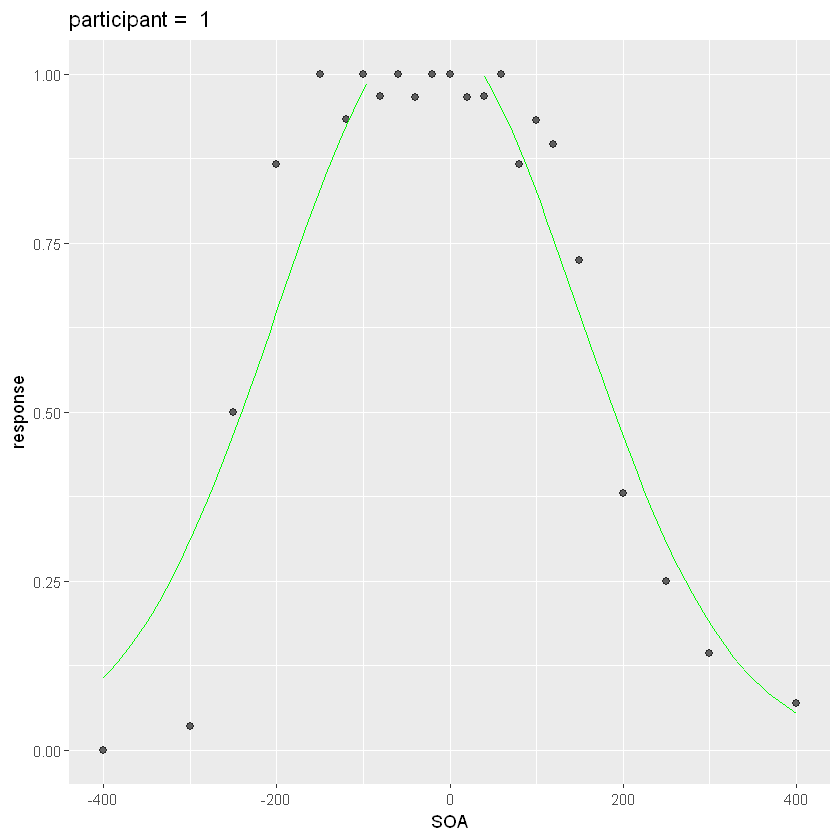

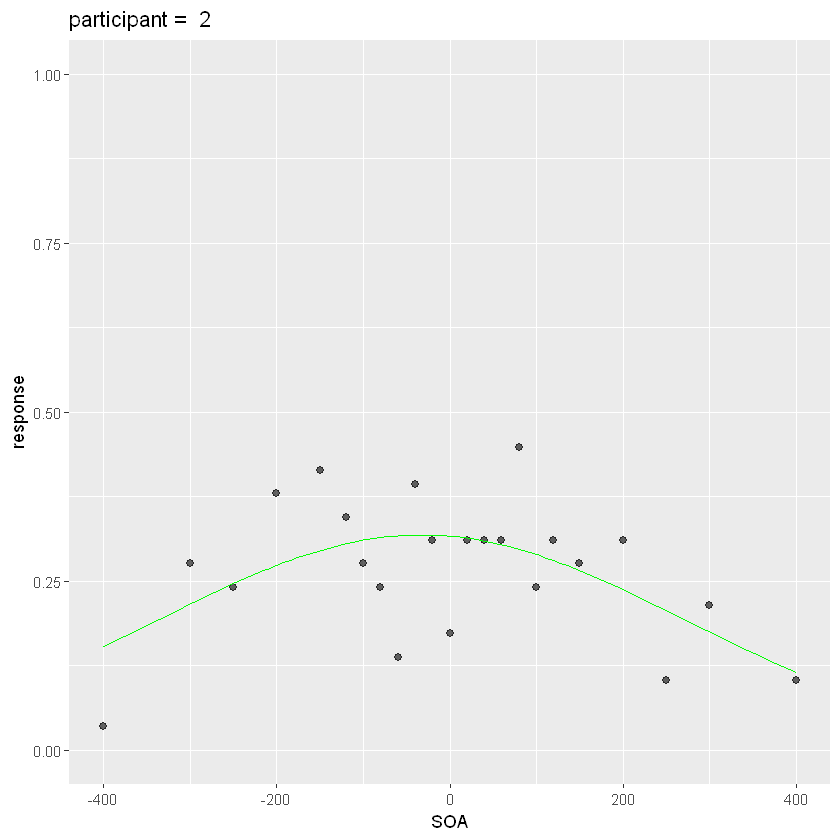

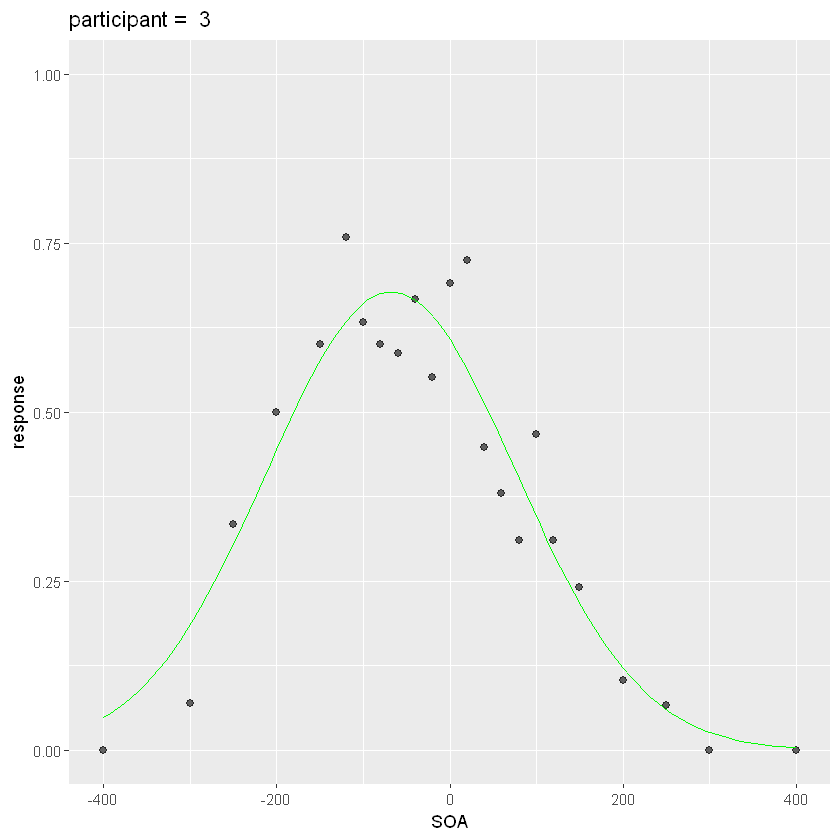

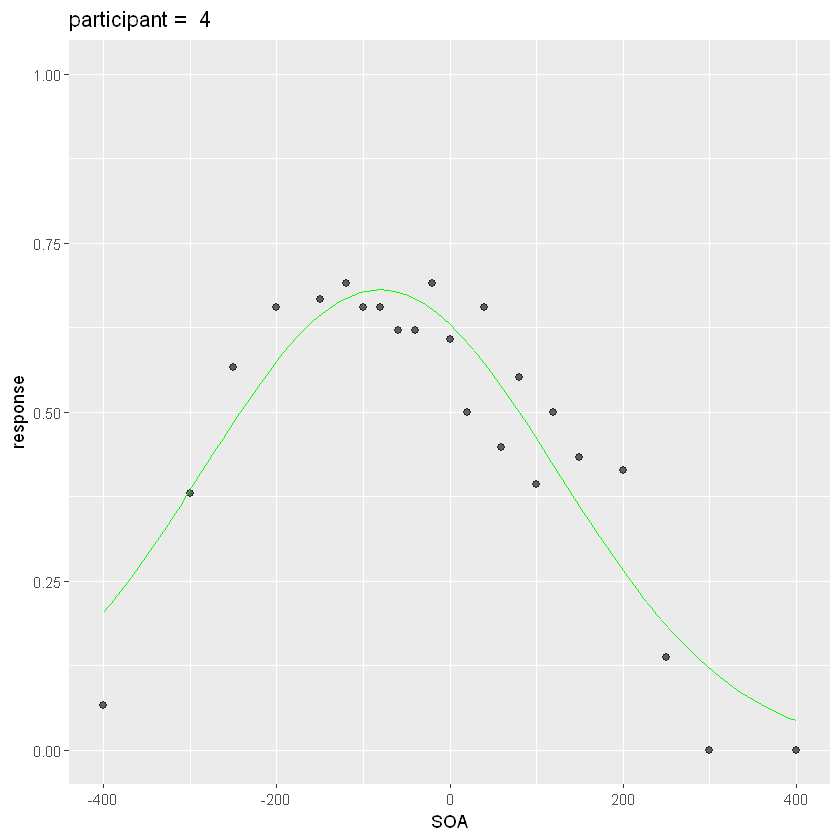

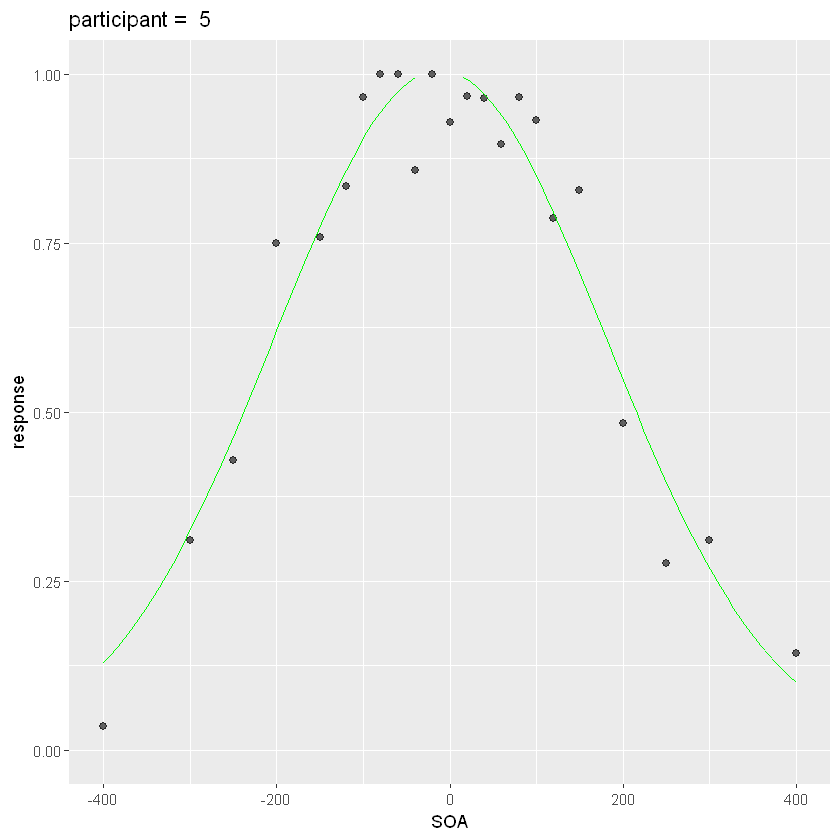

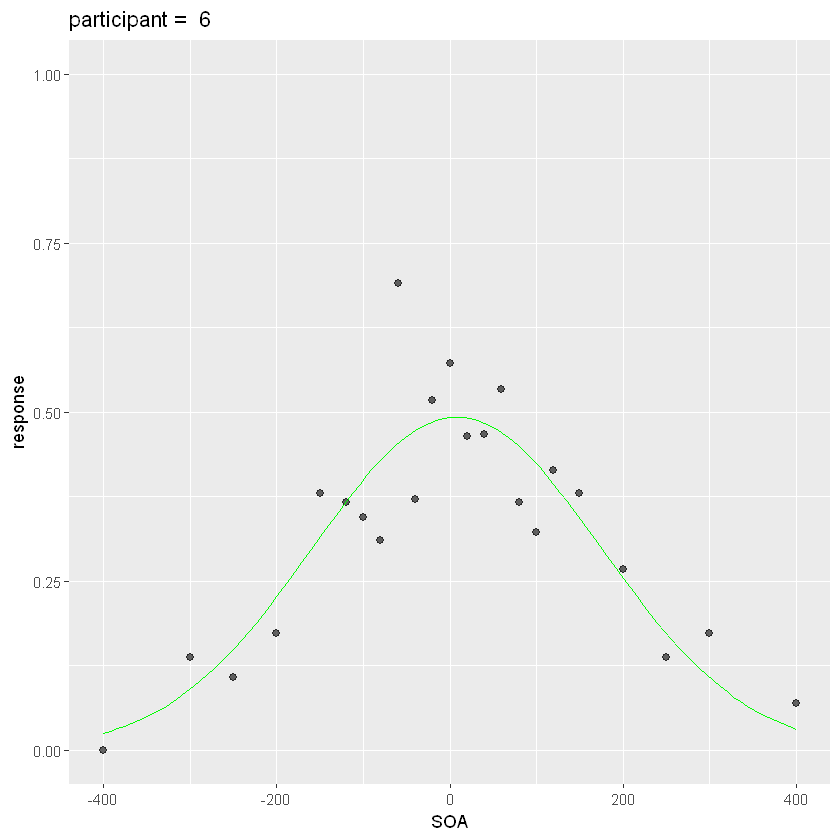

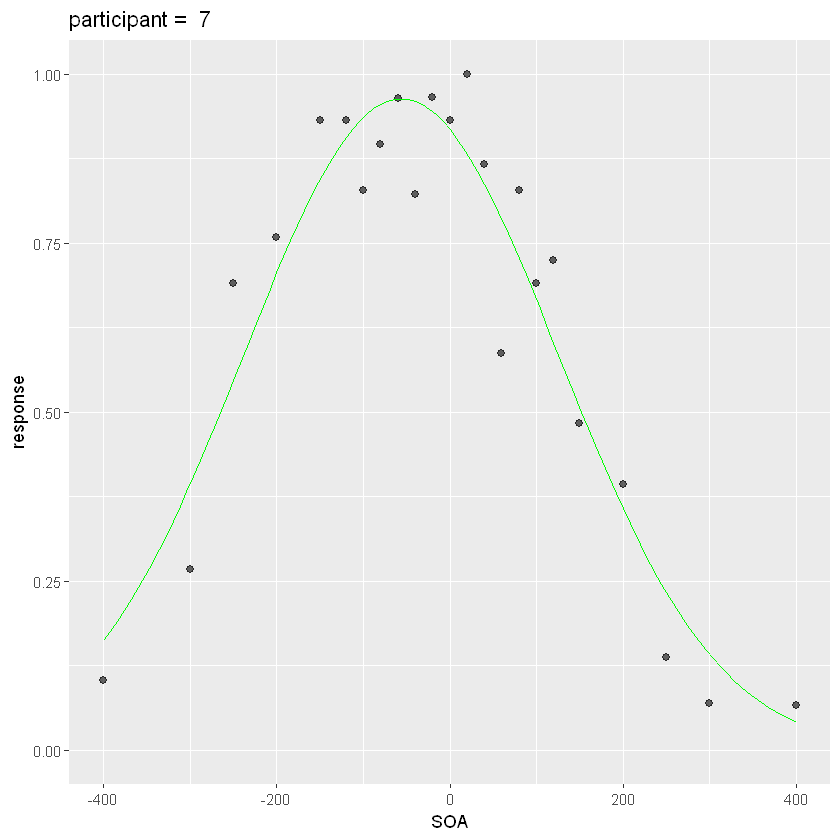

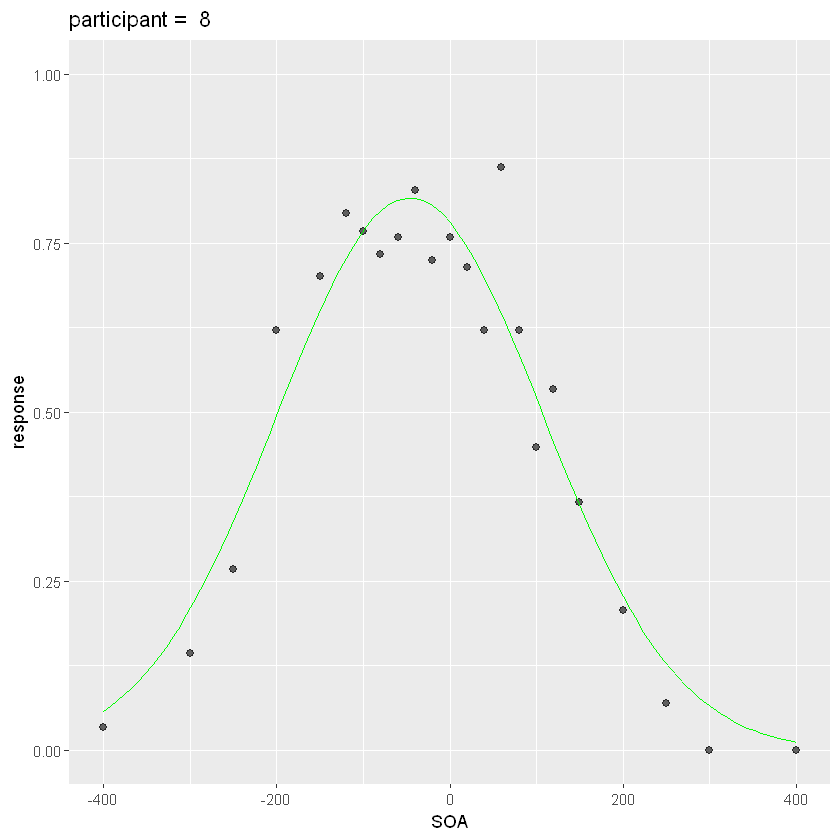

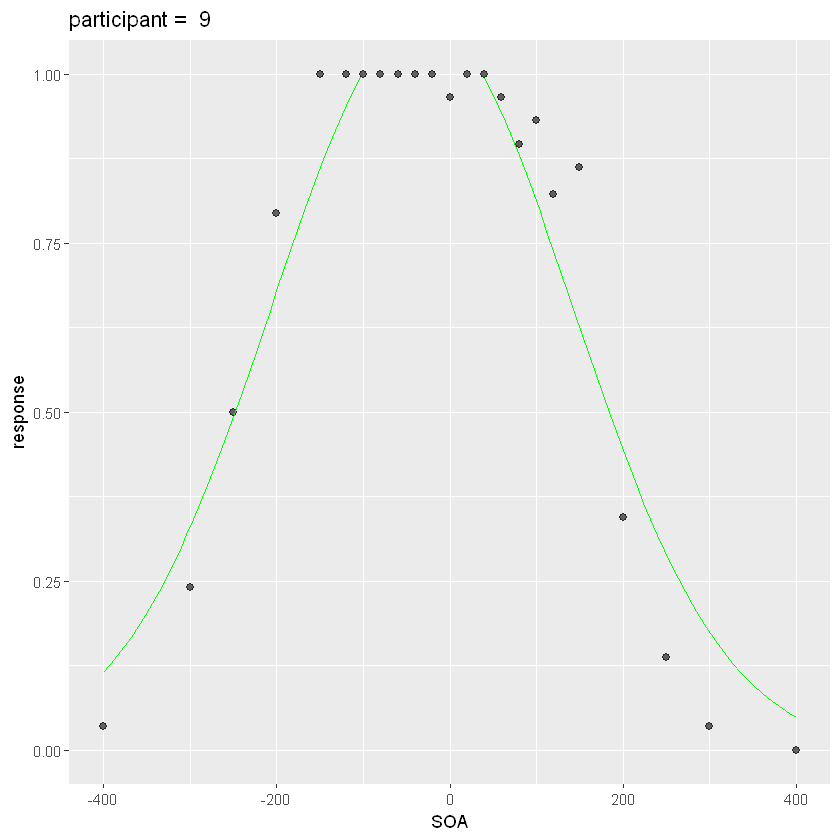

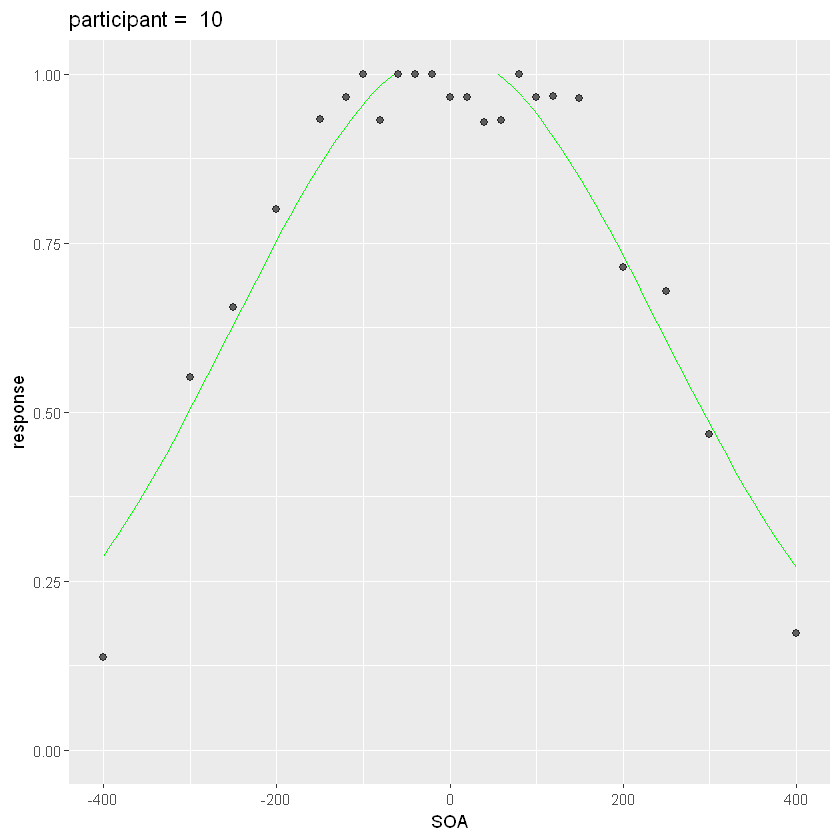

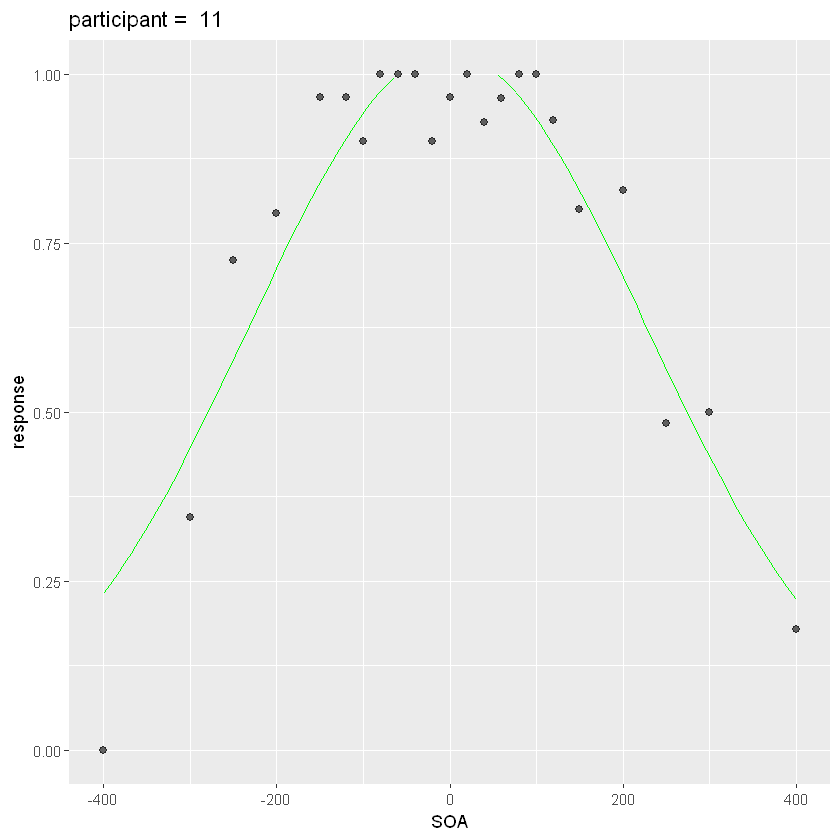

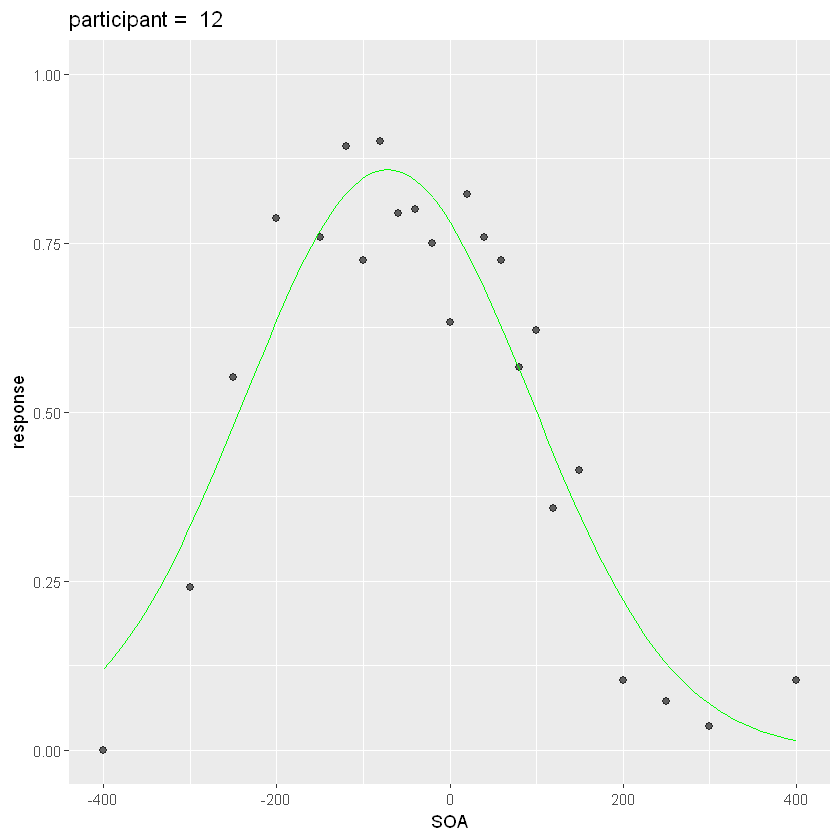

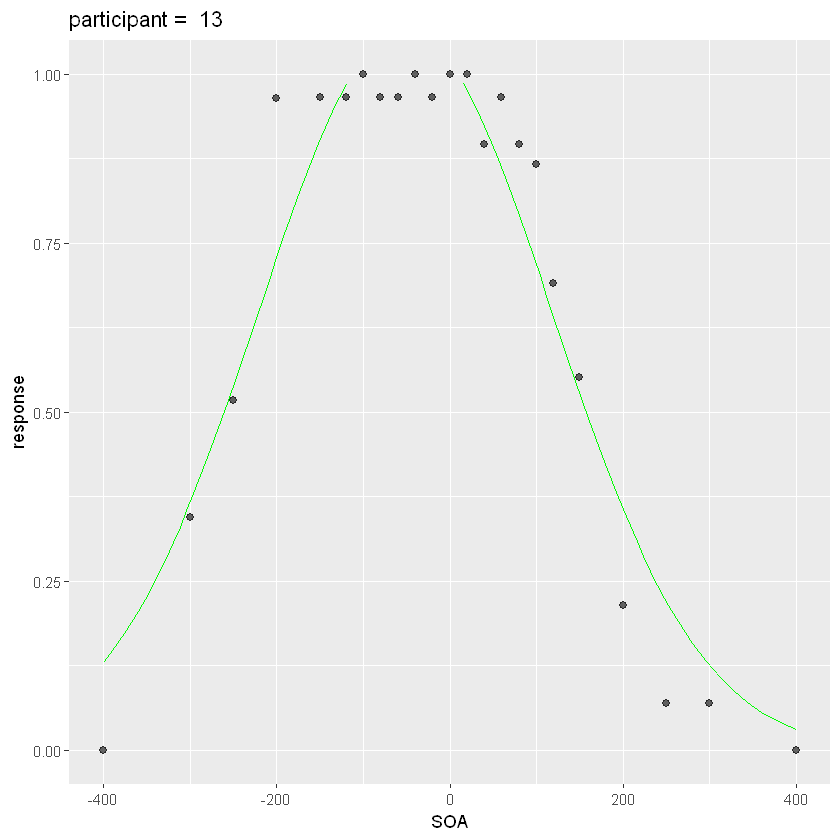

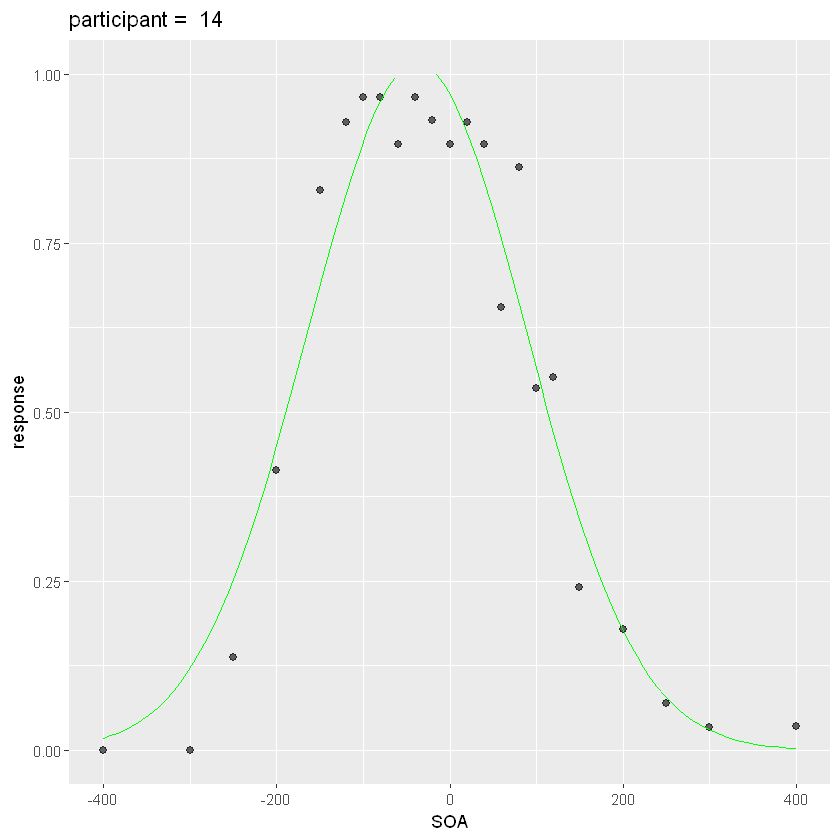

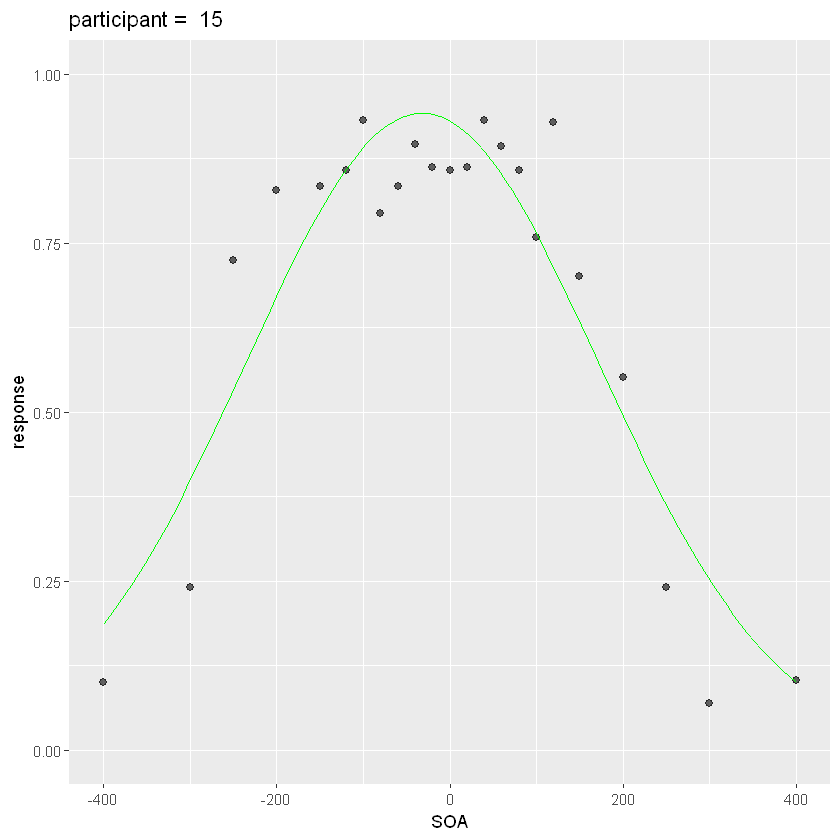

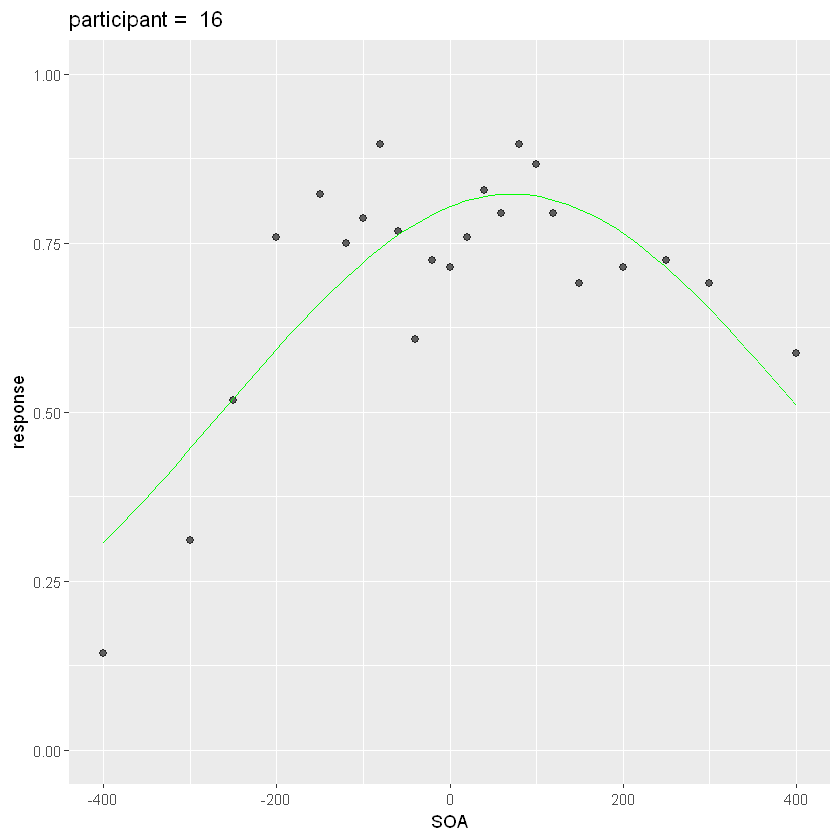

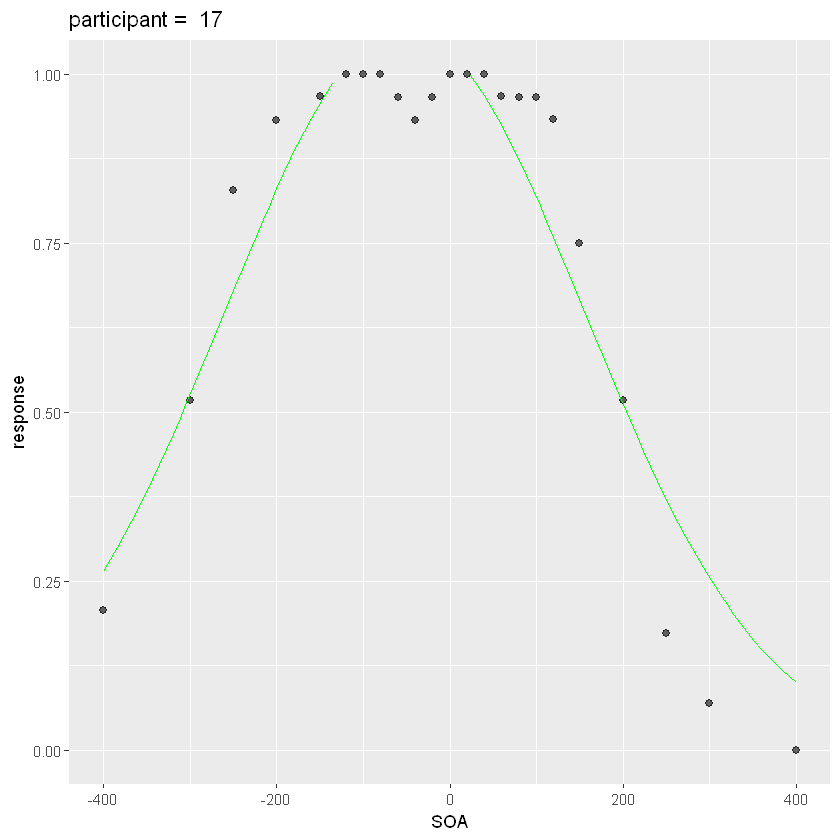

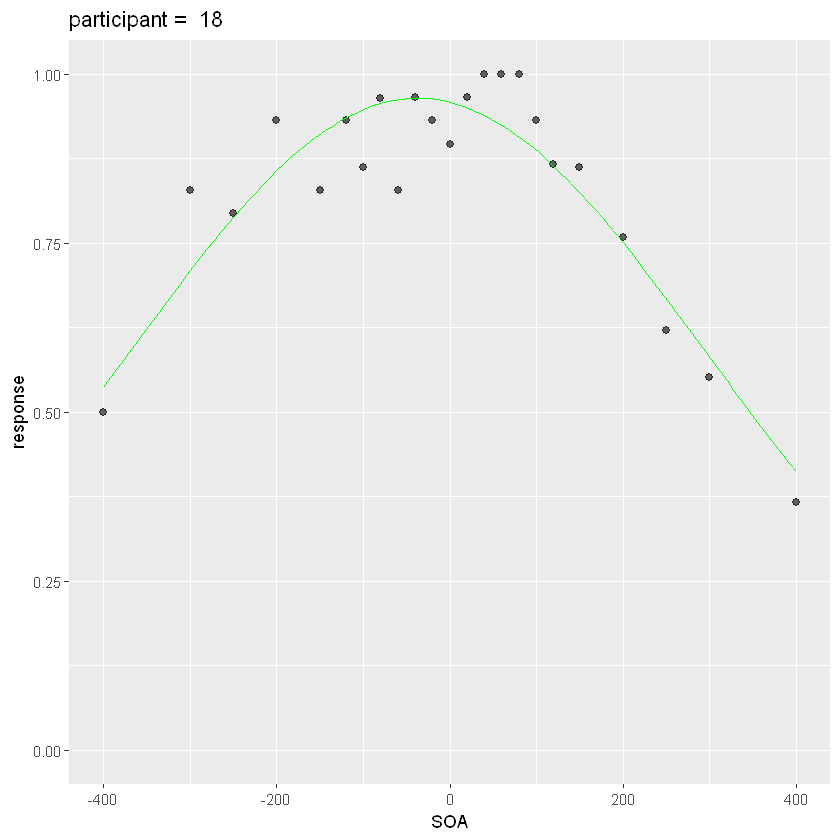

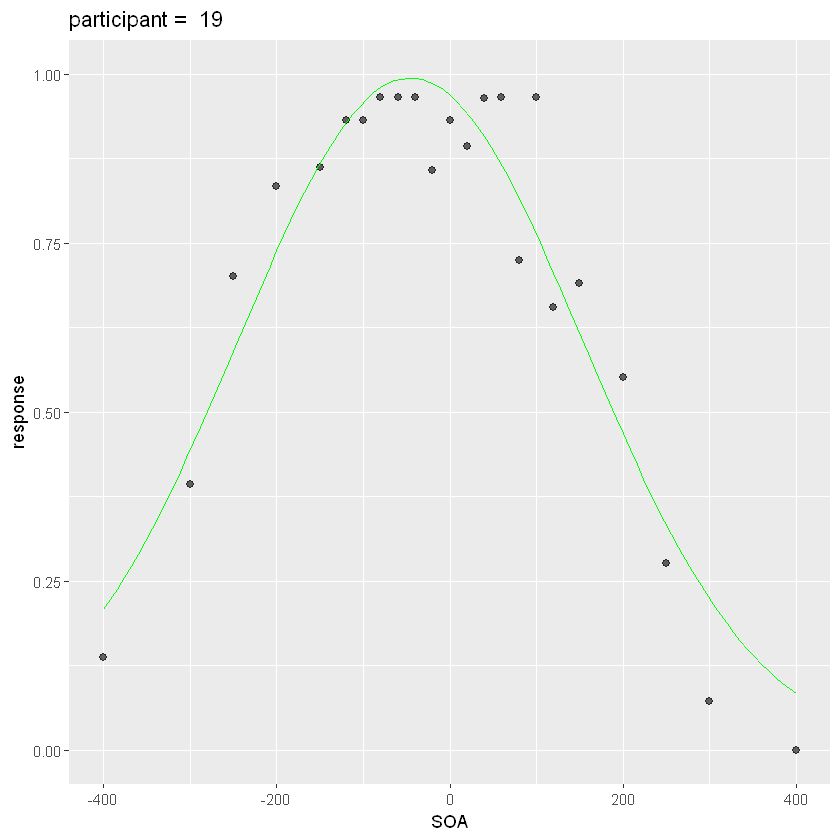

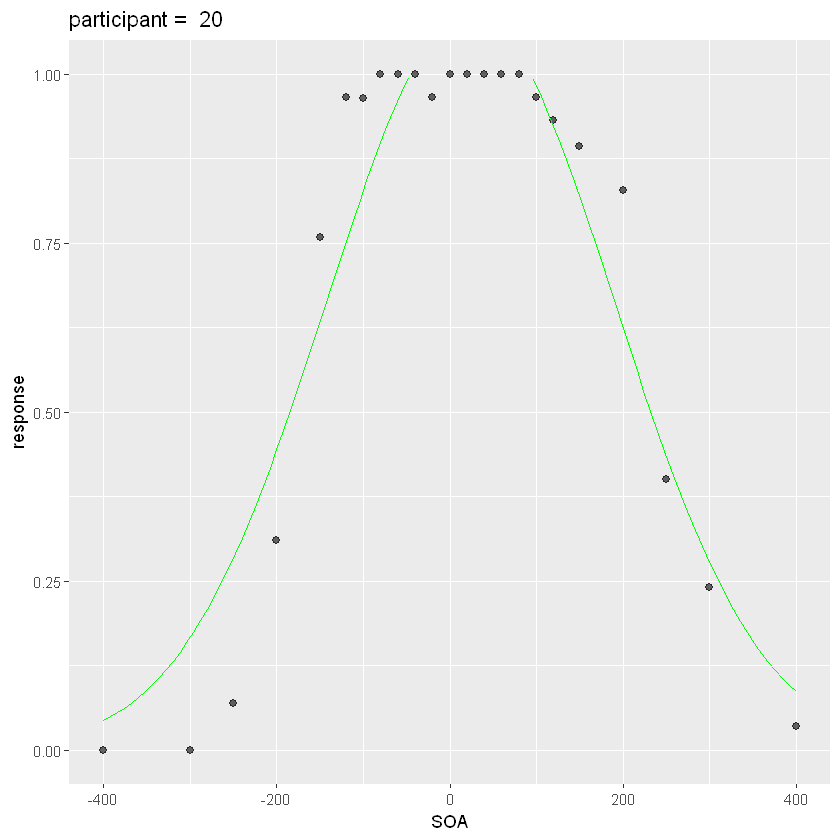

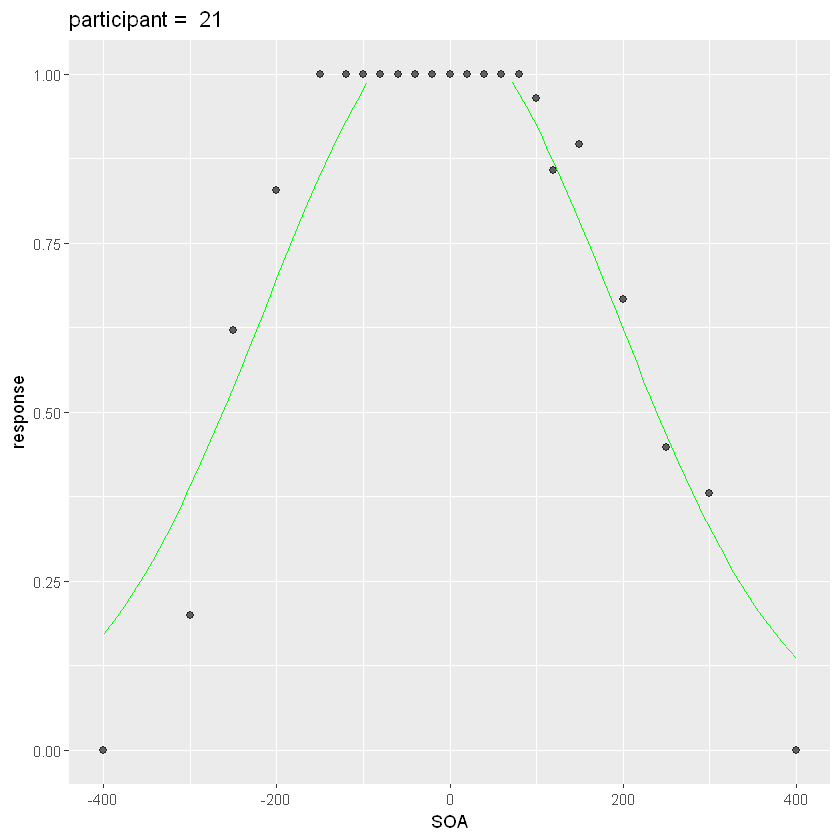

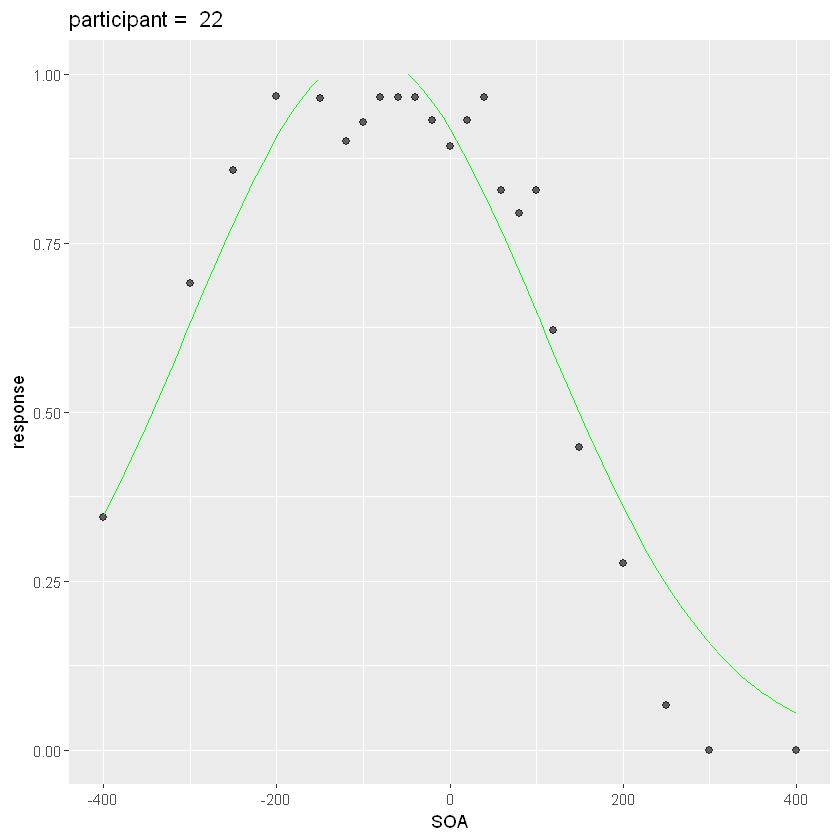

In [46]:
ff <- function(x,amp,pss,sd){
    amp * exp(-(x - pss)^2 / (2 * sd^2))
}
for (par in unique(df$participant)) {
    df_subset <- df %>% filter(participant == par)
    print(ggplot(df_subset, aes(x = SOA, y = response)) +
        geom_point(size = 2, alpha = 0.6) +
        geom_function(fun=ff, args = list(amp = results$amp[results$participant == par],
                                          pss = results$pss[results$participant == par],
                                          sd = results$sd[results$participant == par]), color='green') +
          labs(title = paste('participant = ',par)) + ylim(0,1))
}

In [47]:
###############################################################
# Compute R² for each participant
###############################################################

R2 <- function(observed, predicted){
  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)
  1 - SS_res / SS_tot
}

results$R2 <- NA

for(i in 1:nrow(results)){
  subj <- results$participant[i]
  subdata <- df %>% filter(participant == subj)
  predicted <- results$amp[i] *
    exp(-(subdata$SOA - results$pss[i])^2 /
        (2 * results$sd[i]^2))
  results$R2[i] <- R2(subdata$response, predicted)
}
head(results)

,participant,amp,pss,sd,R2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,1.0686617,-25.568097,174.7035,0.9175397
2,2,0.3182506,-32.745603,303.8340,0.3565134
3,3,0.6775382,-67.691520,144.3776,0.9116079
4,4,0.6808030,-81.155624,204.9848,0.8841341
5,5,1.0058954,-11.596204,191.7681,0.9475129
6,6,0.4924490,7.926039,167.1511,0.8013533


In [48]:
results %>% arrange(R2)

participant,amp,pss,sd,R2
<int>,<dbl>,<dbl>,<dbl>,<dbl>
2,0.3182506,-32.745603,303.8340,0.3565134
16,0.8221961,71.476888,335.9364,0.7048325
6,0.4924490,7.926039,167.1511,0.8013533
18,0.9640922,-37.286065,335.1489,0.8673889
15,0.9418602,-32.046242,204.3086,0.8759831
4,0.6808030,-81.155624,204.9848,0.8841341
11,1.0307491,-2.528493,230.0213,0.9014302
17,1.0682520,-52.425218,208.0434,0.9068553
3,0.6775382,-67.691520,144.3776,0.9116079


In [49]:
###############################################################
# Exclude participants with poor psychometric fits
# Criterion: R² < 0.50
###############################################################
n_current <- nrow(data)
data <- data[!(data$participant %in% c(2,6,16,18)),]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  2660      number of remaining datapoints:  12011"


In [50]:
data <- data %>% arrange(participant, SOA)
data <- data[c(1,5,3,4)]

In [51]:
head(data)

participant,SOA,resp,rt
<int>,<dbl>,<chr>,<dbl>
1,-400,asynchrony,1.437342
1,-400,asynchrony,1.169998
1,-400,asynchrony,1.236840
1,-400,asynchrony,1.186734
1,-400,asynchrony,1.403907
1,-400,asynchrony,1.069756


In [170]:
# generall Data_without considering prior trial:

write.xlsx(data, "files/SJ_general_data.xlsx", rowNames = FALSE)

###############################################################\
###############################################################
# 2 Prior stimulus preprocessing

- Remove outlier participants
- Remove catch trials.
- Remove unimodal trials (auditory-only, visual-only).
- Remove anticipatory responses (RT < 100 ms).
- Remove missed trials.
- Remove RT outliers (> ±2.5 SD within participant × condition).
- Remove the first trial of each mini-block.
- Remove trials following catch trials or zero-SOA trials or unimodal trials.

In [55]:
data <- read_xlsx("files/SJ_data.xlsx")
head(data)

participant,TrialType,resp,rt
<dbl>,<chr>,<chr>,<dbl>
1,auditroy_only,asynchrony,1.220187
1,audiovisual_SOA_40,synchrony,1.069805
1,auditroy_only,asynchrony,1.186716
1,audiovisual_SOA_80,synchrony,1.353749
1,audiovisual_SOA_100,synchrony,1.270390
1,audiovisual_SOA_80,synchrony,1.220155


In [56]:
n_participants = length(unique(data$participant))
n_type = length(unique(data$TrialType))

In [57]:
nrow(data)

[1] 17160

In [58]:
n_type * n_participants * 30

[1] 17160

In [59]:
###############################################################
# Remove participants with poor Gaussian model fit
###############################################################

n_current <- nrow(data)
data <- data[!(data$participant %in% c(2,6,16,18)),]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  3120      number of remaining datapoints:  14040"


In [60]:
n_type * (n_participants-4) * 30

[1] 14040

In [61]:
### Create variables describing the previous trial stimulus

j <- data$TrialType
j <- append(j, NA, after=0)
j <- j[-c(length(j))]
data$pre_stim <- j

head(data)

participant,TrialType,resp,rt,pre_stim
<dbl>,<chr>,<chr>,<dbl>,<chr>
1,auditroy_only,asynchrony,1.220187,NA
1,audiovisual_SOA_40,synchrony,1.069805,auditroy_only
1,auditroy_only,asynchrony,1.186716,audiovisual_SOA_40
1,audiovisual_SOA_80,synchrony,1.353749,auditroy_only
1,audiovisual_SOA_100,synchrony,1.270390,audiovisual_SOA_80
1,audiovisual_SOA_80,synchrony,1.220155,audiovisual_SOA_100


In [62]:
###############################################################
# Determine the first trial of each mini-block.
# In this experiment each mini-block contains 30 trials.
# The first trial is removed because it has no valid previous-trial history.

data$pre_stim[as.numeric(row.names(data)) %% 30==1] <- NA

In [63]:
# Remove trials catch
###############################################################
n_current <- nrow(data)
data <- data[data$TrialType!='catch',]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  540      number of remaining datapoints:  13500"


In [64]:
###############################################################
# Remove unimodal conditions (auditory-only, visual-only)
# as the analysis focuses on audiovisual temporal judgments
###############################################################
n_current <- nrow(data)
data <- data %>%
    filter(!TrialType %in% c("auditroy_only", "visual_only"))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1080      number of remaining datapoints:  12420"


In [65]:
(n_type-3) * (n_participants-4) * 30

[1] 12420

In [66]:
# Remove anticipatory responses (RT < 100 ms)

n_current <- nrow(data)
data <- data[data$rt>=.1,]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  2      number of remaining datapoints:  12418"


In [67]:
# Remove missed trials

n_current <- nrow(data)
data <- data %>% filter(!is.na(resp))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  0      number of remaining datapoints:  12418"


In [68]:
###############################################################
# Remove RT outliers within each participant × condition
# using a ±2 SD criterion
###############################################################

n_current <- nrow(data)
data <- data %>%
  group_by(participant, TrialType) %>%
  filter(
    rt < mean(rt) + 2.5*sd(rt) &
    rt > mean(rt) - 2.5*sd(rt)
  ) %>%
  ungroup()
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  407      number of remaining datapoints:  12011"


In [69]:
# Remove the first trial of each mini-block.

n_current <- nrow(data)
data <- data %>% filter(!is.na(pre_stim))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  389      number of remaining datapoints:  11622"


In [70]:
###############################################################
# Remove trials that follow a zero-SOA or aditory_only or visual_only stimulus
###############################################################

n_current <- nrow(data)
data <- filter(data, pre_stim!= "auditroy_only")
data <- filter(data, pre_stim!= "visual_only")
data <- filter(data, pre_stim!= "audiovisual_SOA_0")
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1339      number of remaining datapoints:  10283"


In [71]:
###############################################################
# Remove trials that follow a catch trial
###############################################################

n_current <- nrow(data)
data <- filter(data, pre_stim!='catch')
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  417      number of remaining datapoints:  9866"


In [72]:
###############################################################
# Categorize the previous stimulus as visual-leading
# or auditory-leading for serial dependence analysis
###############################################################

visual_leading_conditions <- c(
  "visual_only",
  "audiovisual_SOA_400","audiovisual_SOA_300","audiovisual_SOA_250",
  "audiovisual_SOA_200","audiovisual_SOA_150","audiovisual_SOA_120",
  "audiovisual_SOA_100","audiovisual_SOA_80","audiovisual_SOA_60",
  "audiovisual_SOA_40","audiovisual_SOA_20"
)

data <- data %>%
  mutate(
    pre_stim =
      ifelse(pre_stim %in% visual_leading_conditions,
             "visual_leading",
             "auditory_leading")
  )

head(data)

participant,TrialType,resp,rt,pre_stim
<dbl>,<chr>,<chr>,<dbl>,<chr>
1,audiovisual_SOA_100,synchrony,1.270390,visual_leading
1,audiovisual_SOA_80,synchrony,1.220155,visual_leading
1,audiovisual_NSOA_60,synchrony,1.169990,auditory_leading
1,audiovisual_NSOA_300,asynchrony,1.453991,auditory_leading
1,audiovisual_SOA_40,synchrony,1.353891,auditory_leading
1,audiovisual_SOA_120,asynchrony,1.771563,visual_leading


In [73]:
###############################################################
# Map TrialType to signed SOA values
###############################################################

TT <- c(
'audiovisual_NSOA_100','audiovisual_NSOA_120','audiovisual_NSOA_150','audiovisual_NSOA_20',
'audiovisual_NSOA_200','audiovisual_NSOA_250','audiovisual_NSOA_300','audiovisual_NSOA_40',
'audiovisual_NSOA_400','audiovisual_NSOA_60','audiovisual_NSOA_80',
'audiovisual_SOA_0',
'audiovisual_SOA_100','audiovisual_SOA_120','audiovisual_SOA_150','audiovisual_SOA_20',
'audiovisual_SOA_200','audiovisual_SOA_250','audiovisual_SOA_300','audiovisual_SOA_40',
'audiovisual_SOA_400','audiovisual_SOA_60','audiovisual_SOA_80'
)

SOA_vals <- c(
-100,-120,-150,-20,-200,-250,-300,-40,-400,-60,-80,
0,
100,120,150,20,200,250,300,40,400,60,80
)

soa_map <- data.frame(TrialType = TT, SOA = SOA_vals)

data <- data %>%
  filter(TrialType %in% TT) %>%
  left_join(soa_map, by = "TrialType")
data <- data %>% arrange(participant, pre_stim, SOA)
data <- data[c(1,5,6,3,4)]
head(data)

participant,pre_stim,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,auditory_leading,-400,asynchrony,1.4373420
1,auditory_leading,-400,asynchrony,1.1699982
1,auditory_leading,-400,asynchrony,1.2704500
1,auditory_leading,-400,asynchrony,1.0868608
1,auditory_leading,-400,asynchrony,0.9859973
1,auditory_leading,-400,asynchrony,0.9527494


In [194]:
write.xlsx(data, "files/SJ_prior_stimulus_data.xlsx", rowNames = FALSE)

In [126]:
###############################################################
# Load SJ serial dependence dataset (prepared previously)
###############################################################

df <- read_xlsx("files2/SJ_prior_stimulus_data.xlsx")
head(df)
###############################################################



participant,pre_stim,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,auditory_leading,-400,asynchrony,1.4373420
1,auditory_leading,-400,asynchrony,1.1699982
1,auditory_leading,-400,asynchrony,1.2704500
1,auditory_leading,-400,asynchrony,1.0868608
1,auditory_leading,-400,asynchrony,0.9859973
1,auditory_leading,-400,asynchrony,0.9527494


In [127]:
###############################################################
# Prepare behavioral variables
###############################################################

data <- df %>%
  mutate(
    resp = ifelse(resp == "synchrony", 1, 0)
  )
head(data)

participant,pre_stim,SOA,resp,rt
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,auditory_leading,-400,0,1.4373420
1,auditory_leading,-400,0,1.1699982
1,auditory_leading,-400,0,1.2704500
1,auditory_leading,-400,0,1.0868608
1,auditory_leading,-400,0,0.9859973
1,auditory_leading,-400,0,0.9527494


In [128]:
###############################################################
# Fit Gaussian function to synchorony responses
#
# Model:
# p(SOA) = amp * exp(-(SOA - pss)^2 / (2 * sd^2))
#
# Parameters:
# amp = amplitude
# pss = point of subjective simultaneity
# sd  = temporal binding window width
###############################################################

Gauss <- function(data){

  loss_function <- function(params){

    amp <- params[1]
    pss <- params[2]
    sd  <- params[3]

    predicted <- amp * exp(-(data$SOA - pss)^2 / (2 * sd^2))

    sum((predicted - data$resp)^2)

  }

  DEoptim(
    loss_function,
    lower = c(0, -400, 1),
    upper = c(2, 400, 500)
  )

}

results <- data.frame()

for(subj in unique(data$participant)){
  subdata1 <- data %>% filter(participant == subj)
  for(ps in unique(data$pre_stim)){
  subdata2 <- subdata1 %>% filter(pre_stim == ps)    
  fit <- Gauss(subdata2)$optim$bestmem

  results <- rbind(
    results,
    data.frame(
      participant = subj,
      pre_stim = ps,
      amp = fit[1],
      pss = fit[2],
      sd  = fit[3]
    )
  )
}}

rownames(results) <- NULL

Iteration: 1 bestvalit: 45.863332 bestmemit:    0.739747  -65.173776  398.656709
Iteration: 2 bestvalit: 39.828901 bestmemit:    0.839323   50.021106  285.077817
Iteration: 3 bestvalit: 38.614497 bestmemit:    1.109400   29.679293  228.187835
Iteration: 4 bestvalit: 29.481207 bestmemit:    1.153536  -65.081638  182.537513
Iteration: 5 bestvalit: 29.408310 bestmemit:    0.886789  -29.817529  200.274341
Iteration: 6 bestvalit: 27.216745 bestmemit:    1.015749  -29.817529  200.274341
Iteration: 7 bestvalit: 27.216745 bestmemit:    1.015749  -29.817529  200.274341
Iteration: 8 bestvalit: 27.216745 bestmemit:    1.015749  -29.817529  200.274341
Iteration: 9 bestvalit: 27.216745 bestmemit:    1.015749  -29.817529  200.274341
Iteration: 10 bestvalit: 26.110084 bestmemit:    1.015749  -29.817529  167.218674
Iteration: 11 bestvalit: 26.085072 bestmemit:    1.015749  -33.634757  167.218674
Iteration: 12 bestvalit: 26.085072 bestmemit:    1.015749  -33.634757  167.218674
Iteration: 13 bestvalit: 

In [21]:
head(results)

,participant,pre_stim,amp,pss,sd
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,1,auditory_leading,1.0690489,-30.60426,168.9199
2,1,visual_leading,1.0785335,-19.29710,178.1637
3,3,auditory_leading,0.6513385,-68.84329,156.0357
4,3,visual_leading,0.7122981,-68.02148,147.2678
5,4,auditory_leading,0.7108518,-72.35237,207.1948
6,4,visual_leading,0.6711697,-85.21178,186.4913


In [22]:
# CHeck if the considered bounds for parameters are adequate
print(paste(min(results$amp), '    ', max(results$amp)))
print(paste(min(results$pss), '    ', max(results$pss)))
print(paste(min(results$sd), '    ', max(results$sd)))

[1] "0.483396565270894      1.11275855340878"
[1] "-120.693565630973      126.079889750496"
[1] "122.091619645861      389.307442885644"


In [23]:
sort(results$amp)

[1] 0.4833966 0.5059989 0.6513385 0.6711697 0.7108518 0.7122981 0.7613659
 [8] 0.8105812 0.8665195 0.8884853 0.8927439 0.9188703 0.9239651 0.9541126
[15] 0.9766575 0.9834255 0.9845952 0.9992838 1.0008605 1.0037276 1.0040003
[22] 1.0055028 1.0142360 1.0234245 1.0245803 1.0256393 1.0282885 1.0290332
[29] 1.0572071 1.0625815 1.0637656 1.0687792 1.0690489 1.0700768 1.0745023
[36] 1.0785335 1.0800051 1.0814929 1.0826332 1.0903775 1.0914020 1.1127586

In [27]:
results %>% filter(amp< .6)

participant,pre_stim,amp,pss,sd
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
6,auditory_leading,0.5059989,16.098781,157.3042
6,visual_leading,0.4833966,2.252168,182.9120


In [28]:
sort(results$pss)

[1] -120.6935656  -86.7311448  -85.2117839  -72.3523732  -69.5786452
 [6]  -69.5176558  -68.8432870  -68.6769970  -68.0214752  -67.1191146
[11]  -66.5087584  -61.9669031  -59.5754086  -44.5446218  -42.6337839
[16]  -41.7907731  -38.0618195  -35.9291066  -34.6751964  -33.3545924
[21]  -31.3778556  -30.6042599  -29.0710650  -26.5153246  -21.8027636
[26]  -20.7680323  -19.2970989  -18.1616379  -13.4150316  -12.4388014
[31]  -11.3937919   -1.1326817    0.7560377    2.2352861    2.2521683
[36]    5.9871539   10.7007469   16.0987810   25.4295829   27.3765703
[41]   70.2354226  126.0798898

In [29]:
results %>% filter(pss< -100)

participant,pre_stim,amp,pss,sd
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
22,auditory_leading,1.057207,-120.6936,231.9501


In [30]:
results %>% filter(pss> 50)

participant,pre_stim,amp,pss,sd
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
7,auditory_leading,0.8105812,70.23542,333.2821
7,visual_leading,0.8665195,126.07989,389.3074


In [31]:
sort(results$sd)

[1] 122.0916 142.2203 147.2678 149.4422 156.0357 157.3042 160.1564 160.5627
 [9] 161.8895 168.5318 168.9199 171.0507 173.9957 174.3805 176.6150 178.1637
[17] 179.0051 179.3597 182.9120 183.9897 186.4913 187.0687 188.3166 193.5135
[25] 196.9169 198.7045 201.7272 202.1241 207.1948 209.3151 209.5562 210.6242
[33] 213.1009 225.3897 231.9501 238.7808 250.2249 271.3210 315.7979 333.2821
[41] 369.4946 389.3074

In [32]:
results %>% filter(sd> 300)

participant,pre_stim,amp,pss,sd
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
7,auditory_leading,0.8105812,70.23542,333.2821
7,visual_leading,0.8665195,126.07989,389.3074
18,auditory_leading,1.0008605,-26.51532,315.7979
18,visual_leading,0.9766575,-20.76803,369.4946


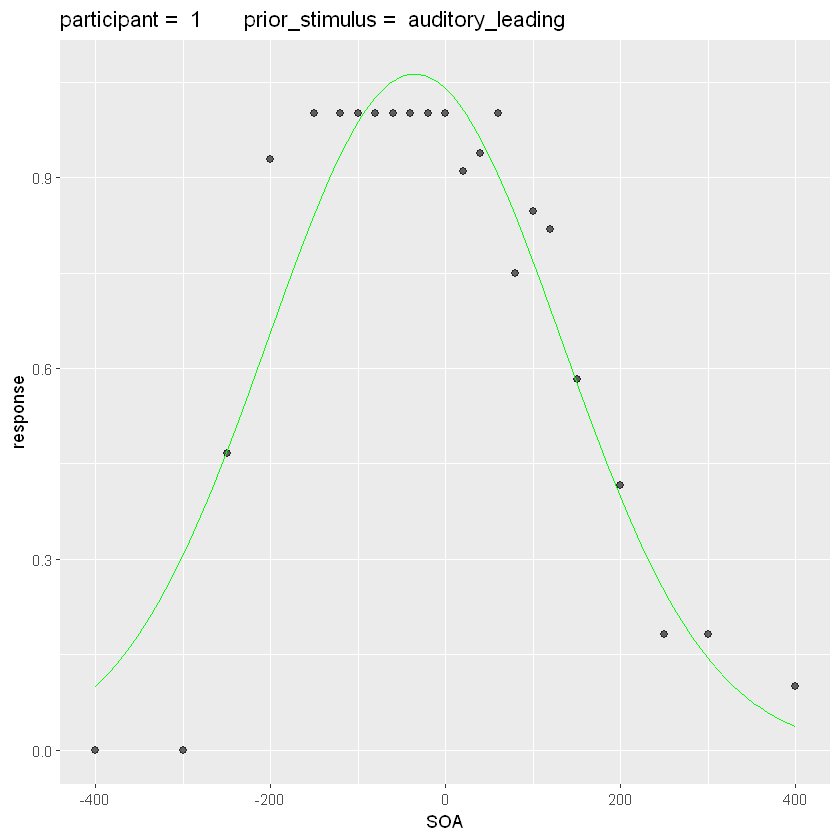

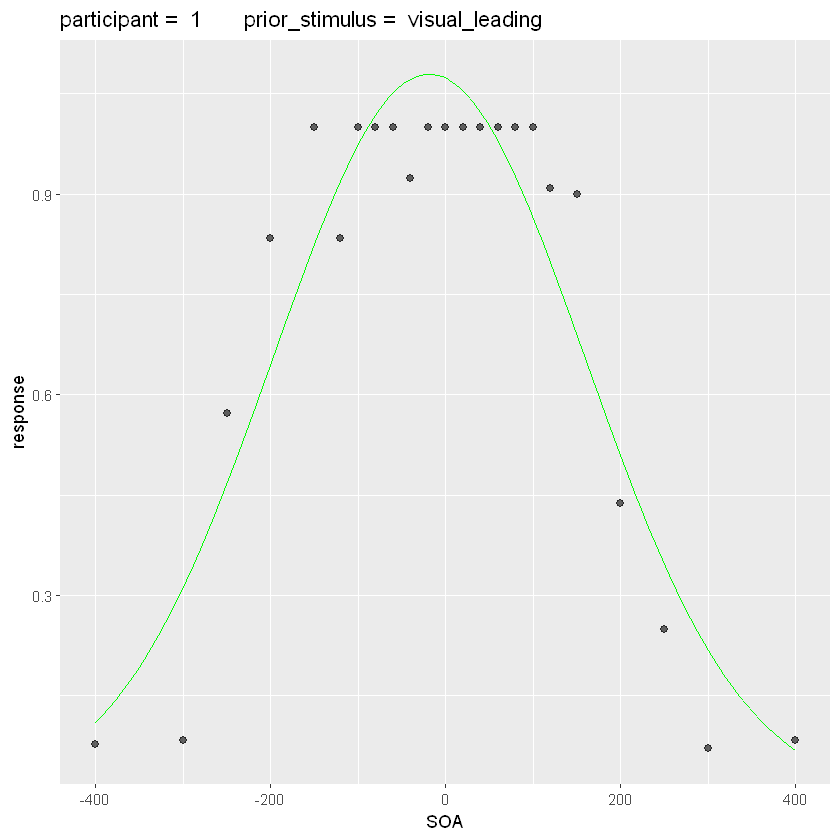

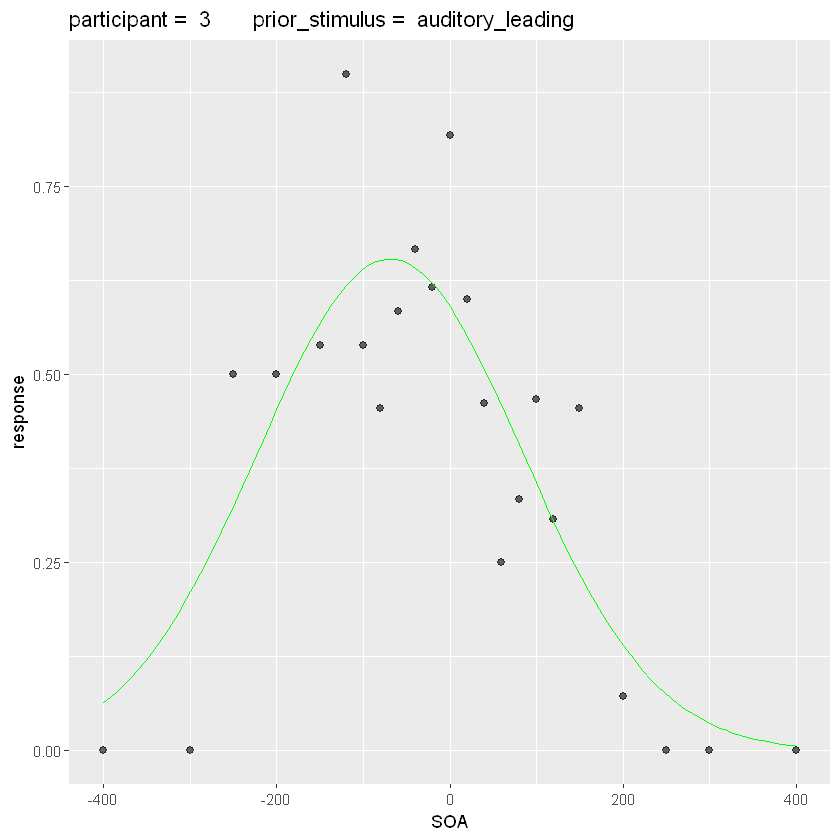

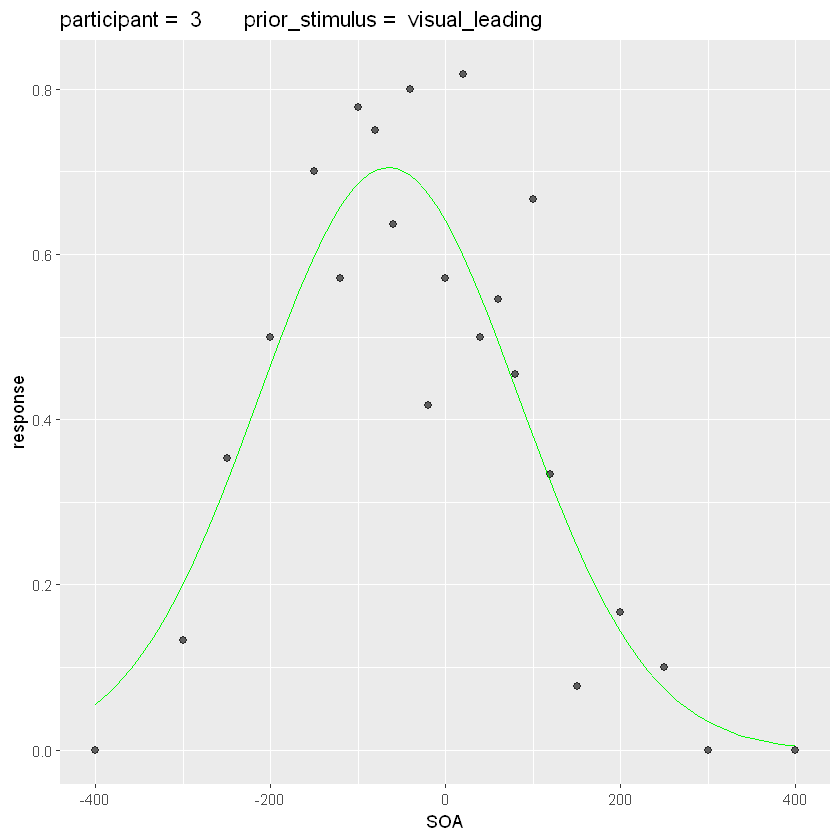

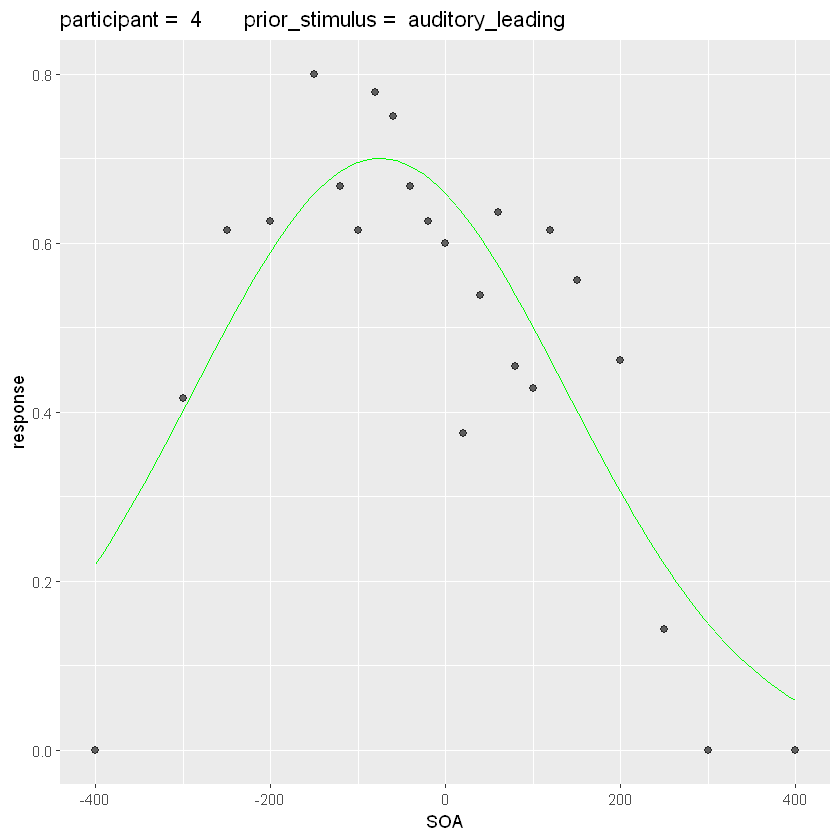

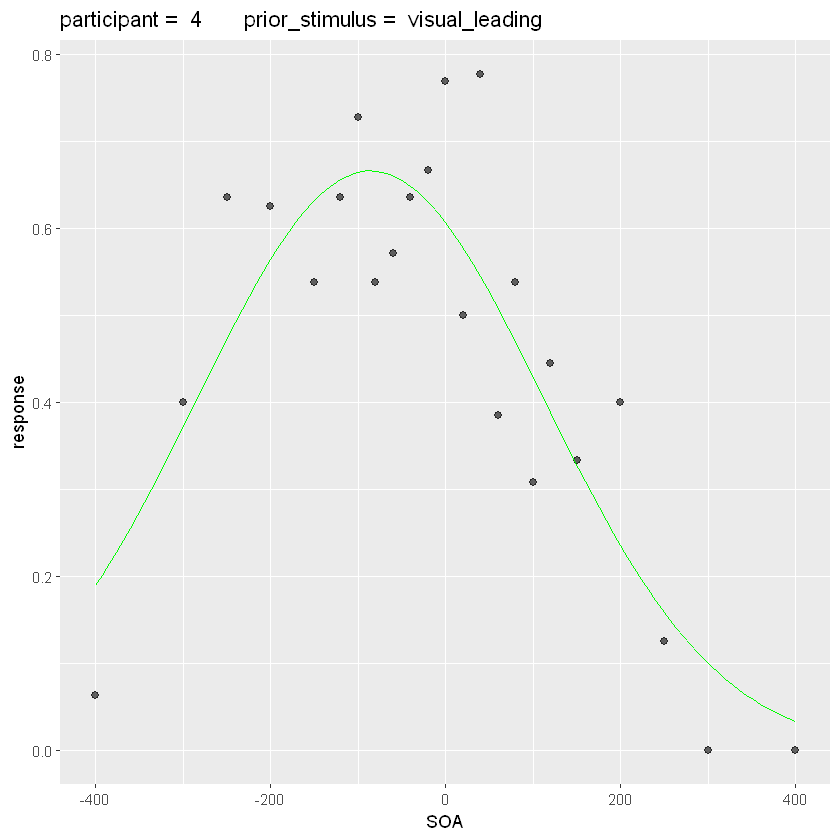

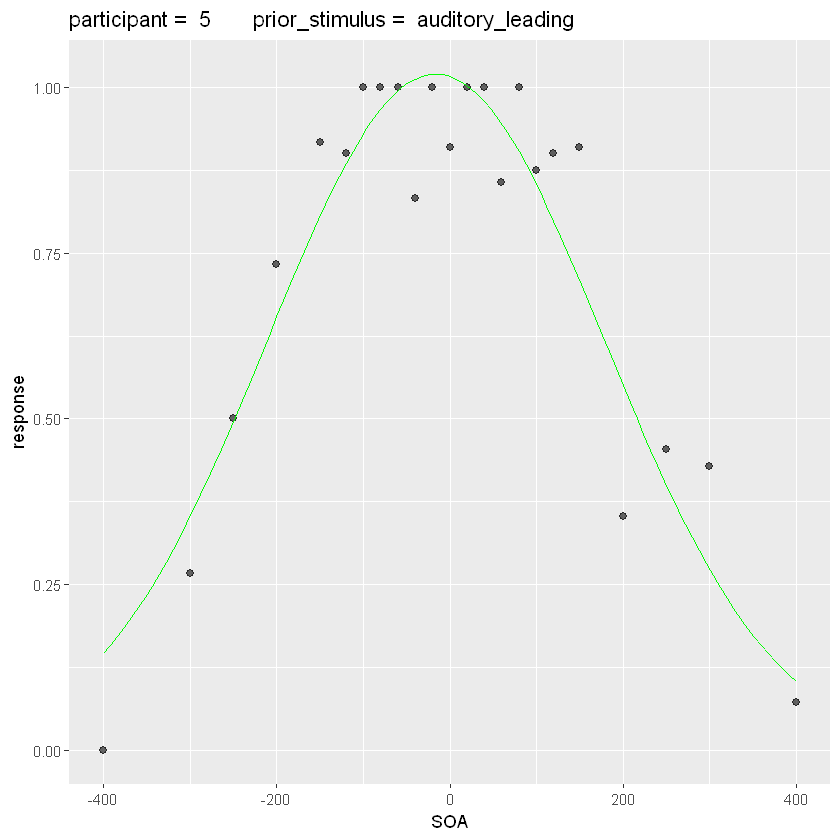

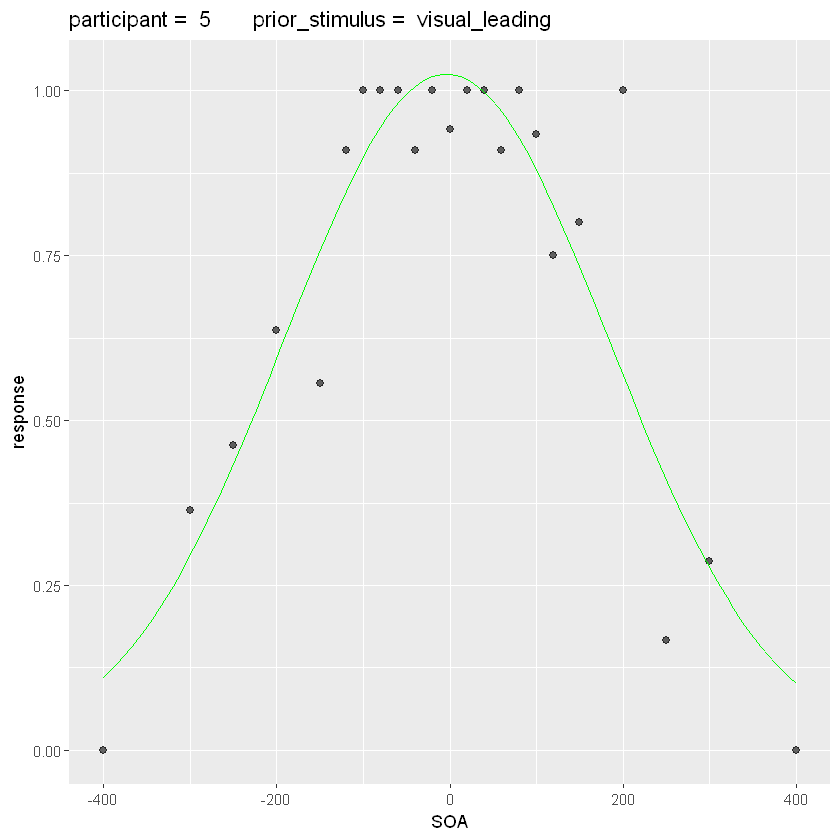

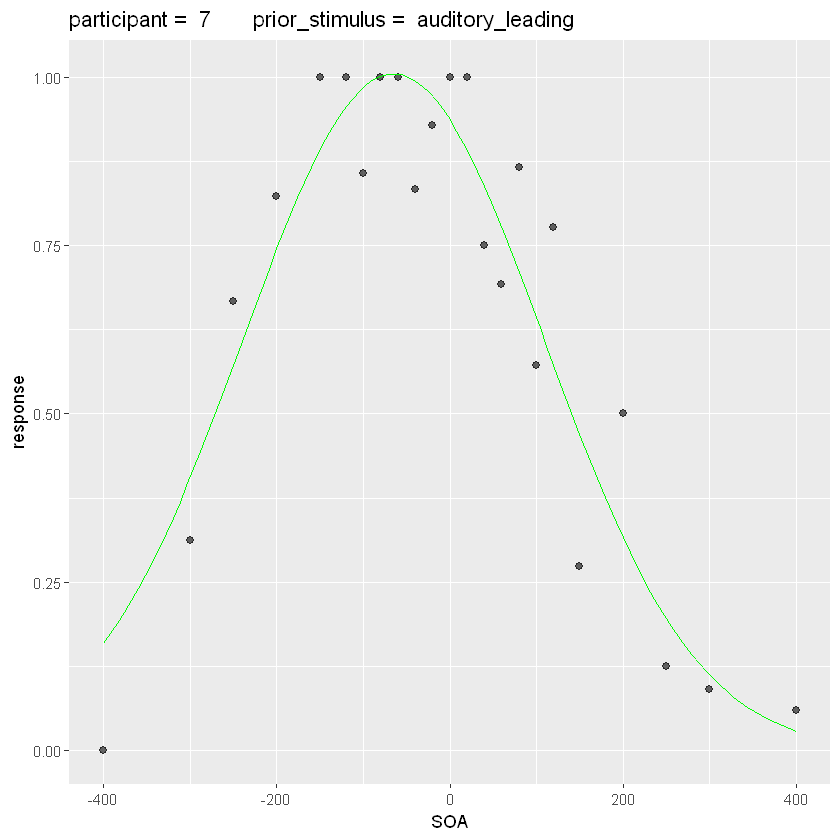

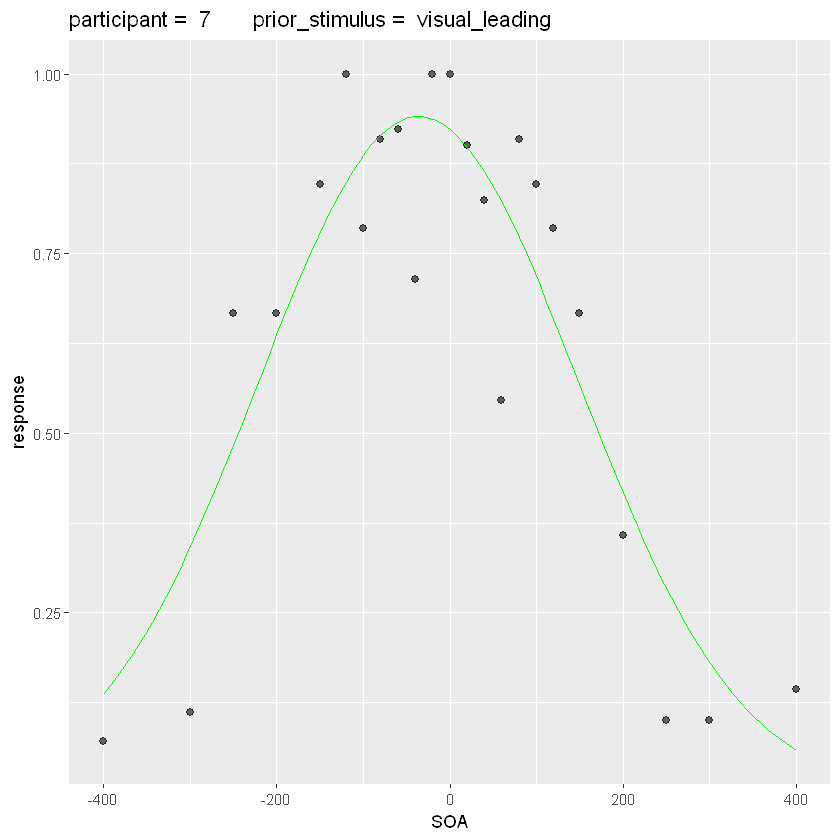

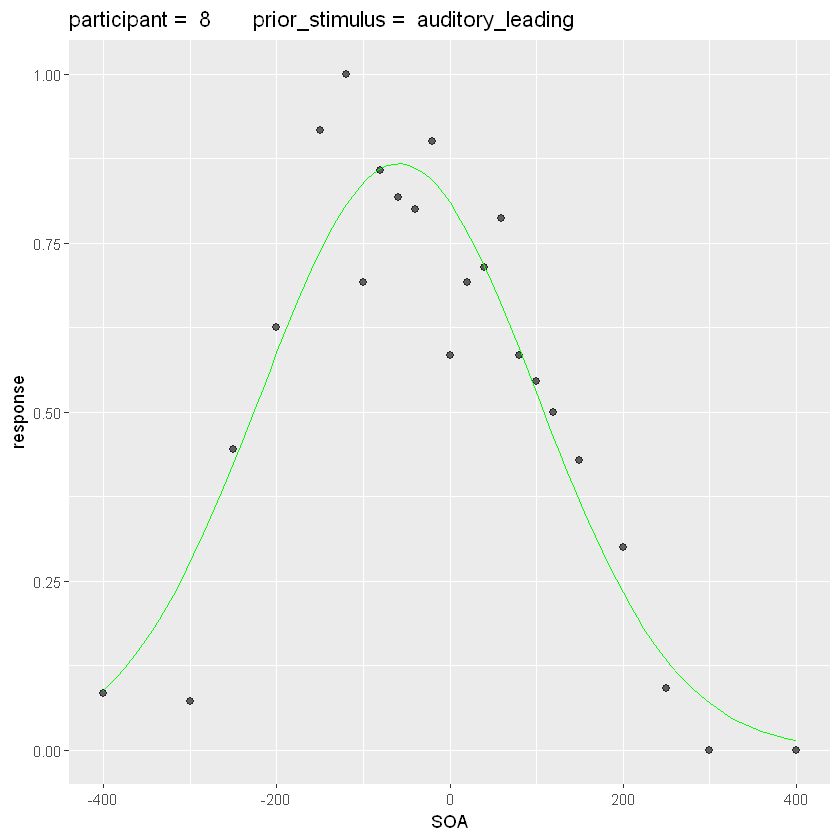

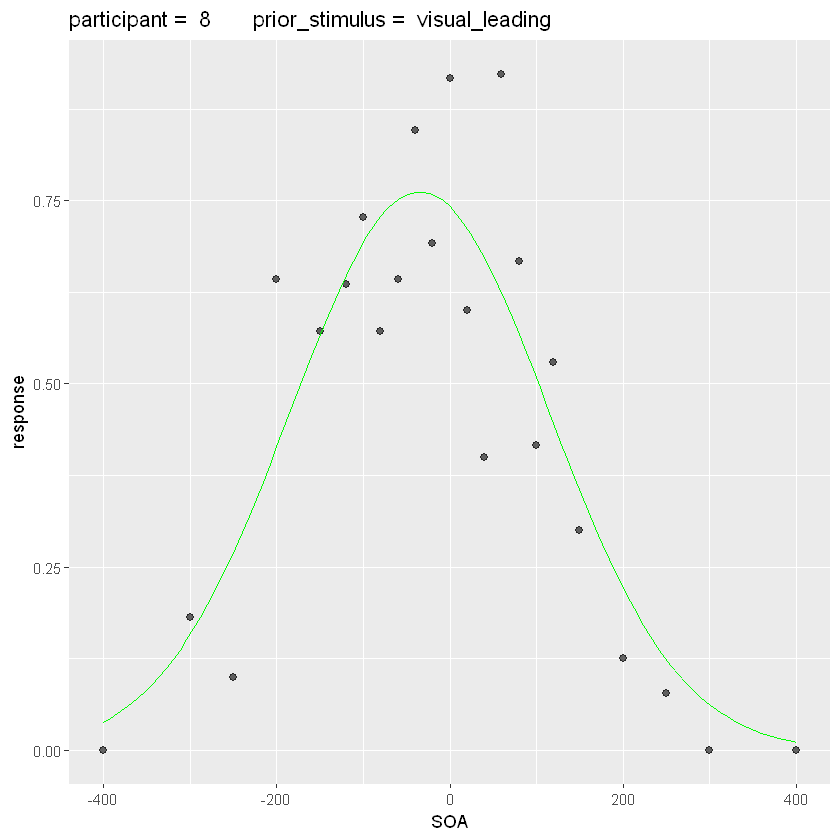

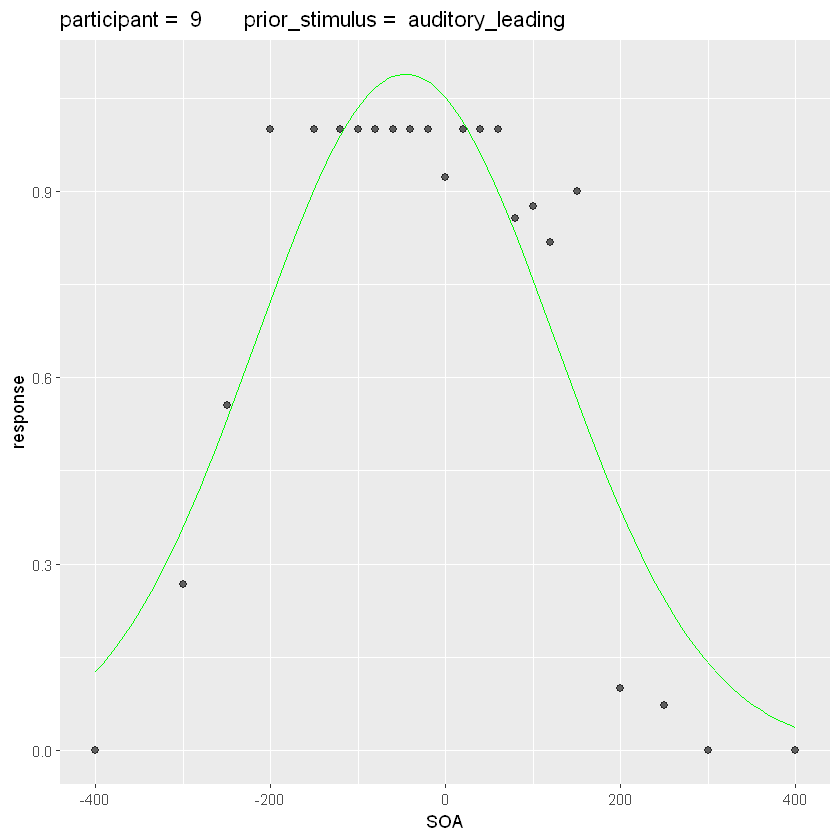

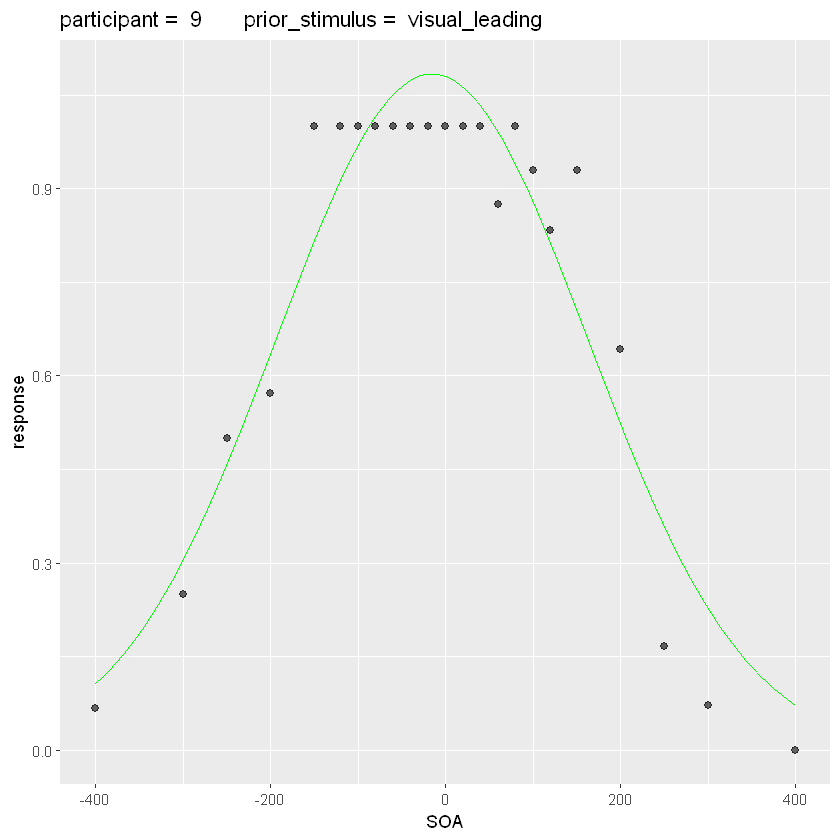

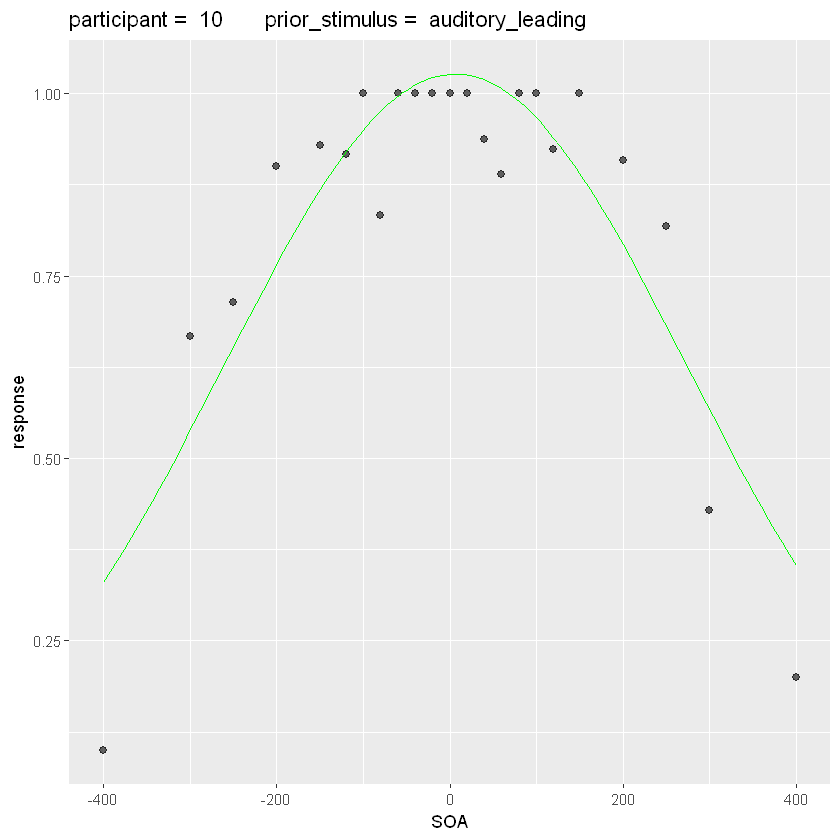

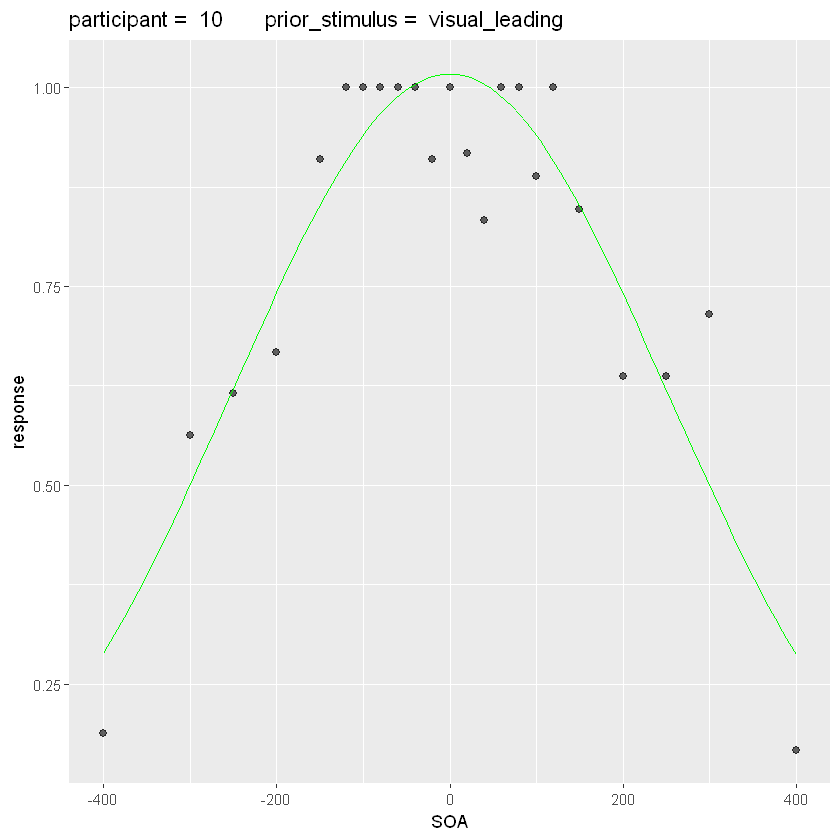

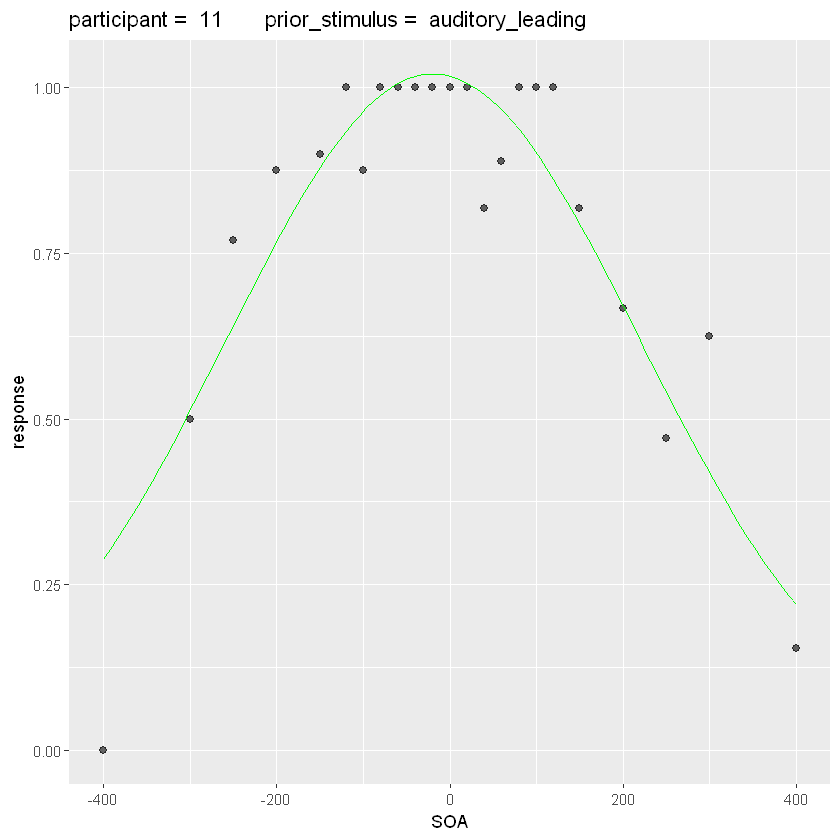

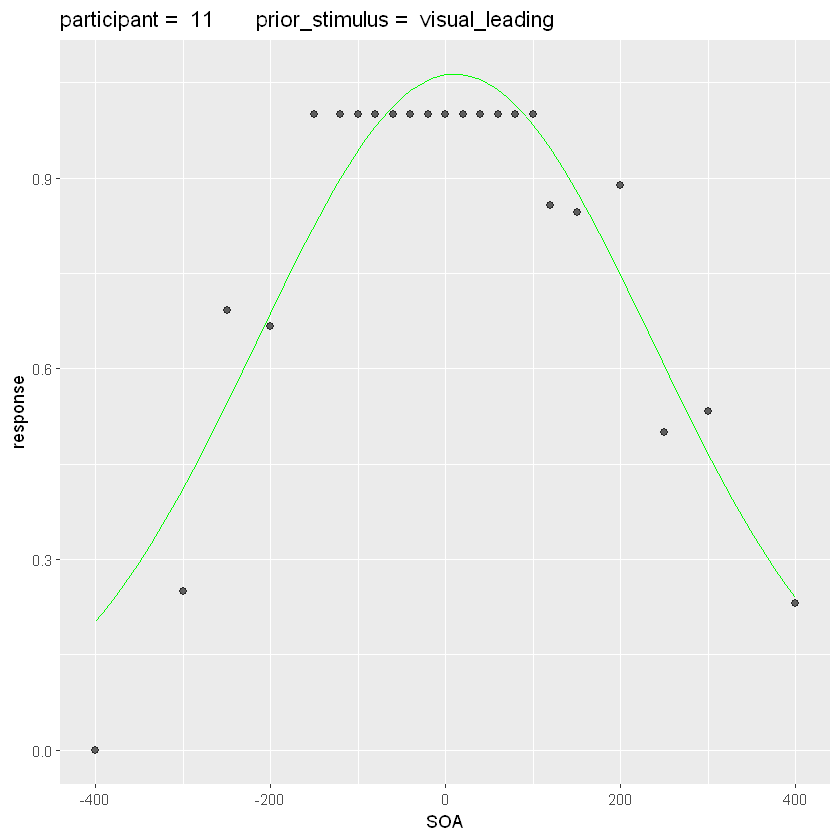

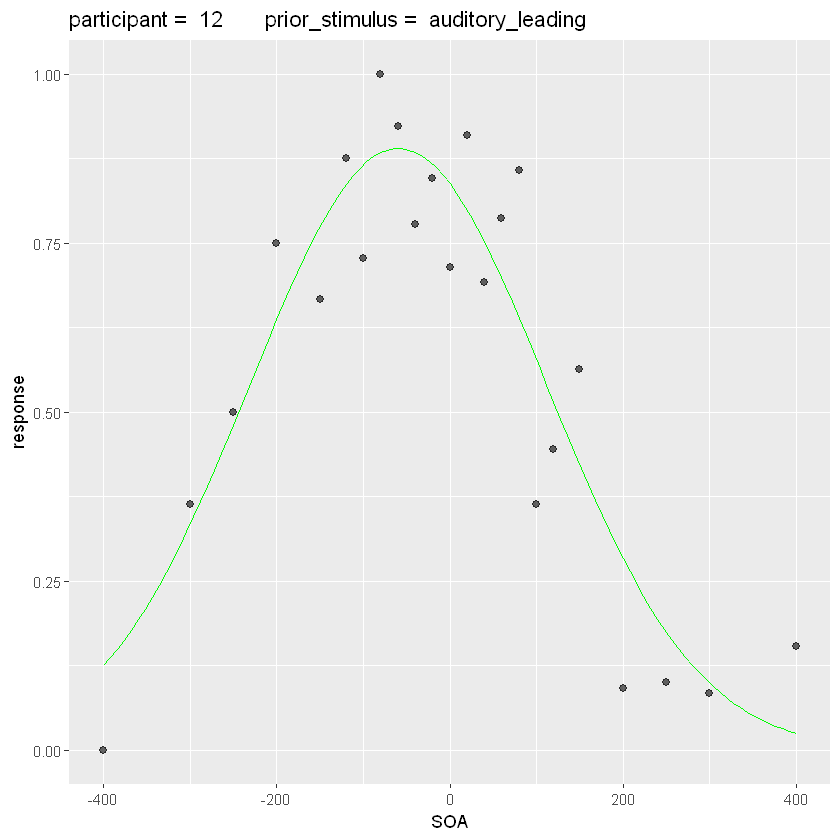

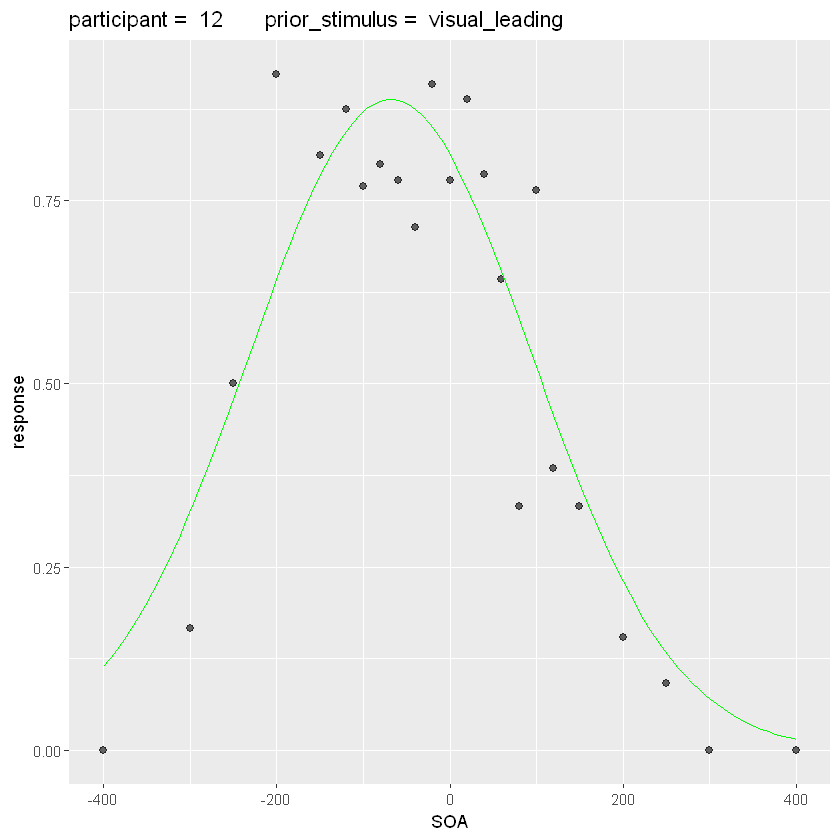

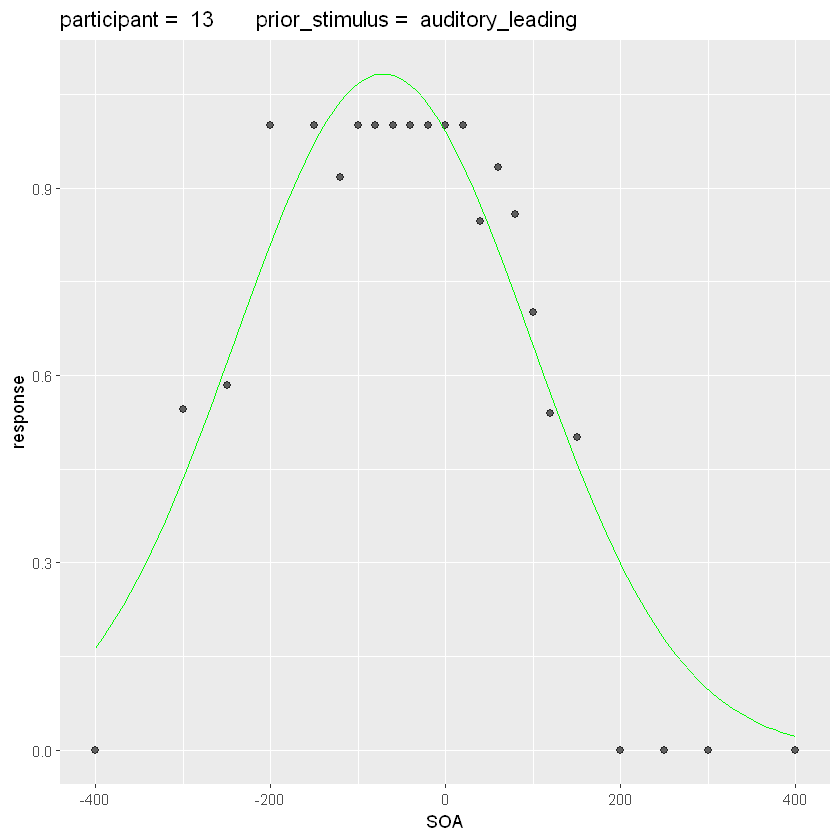

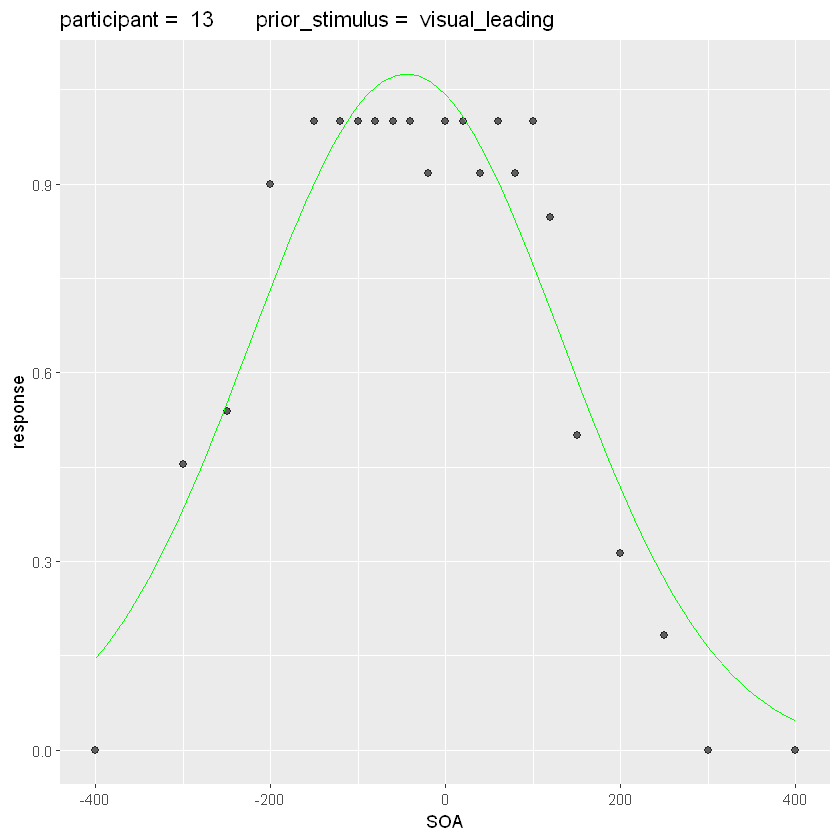

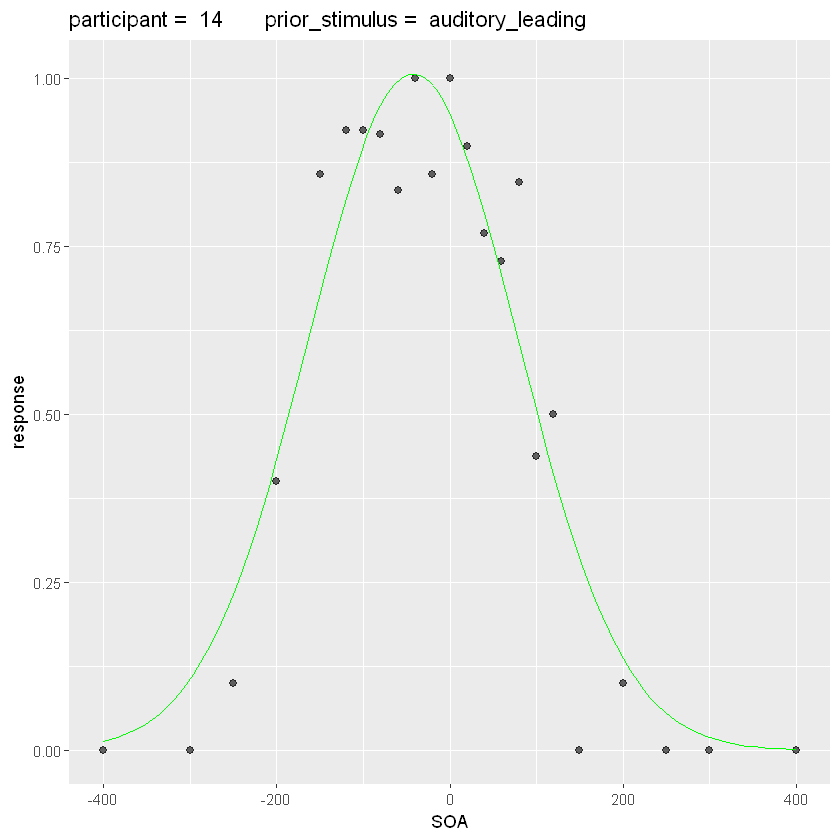

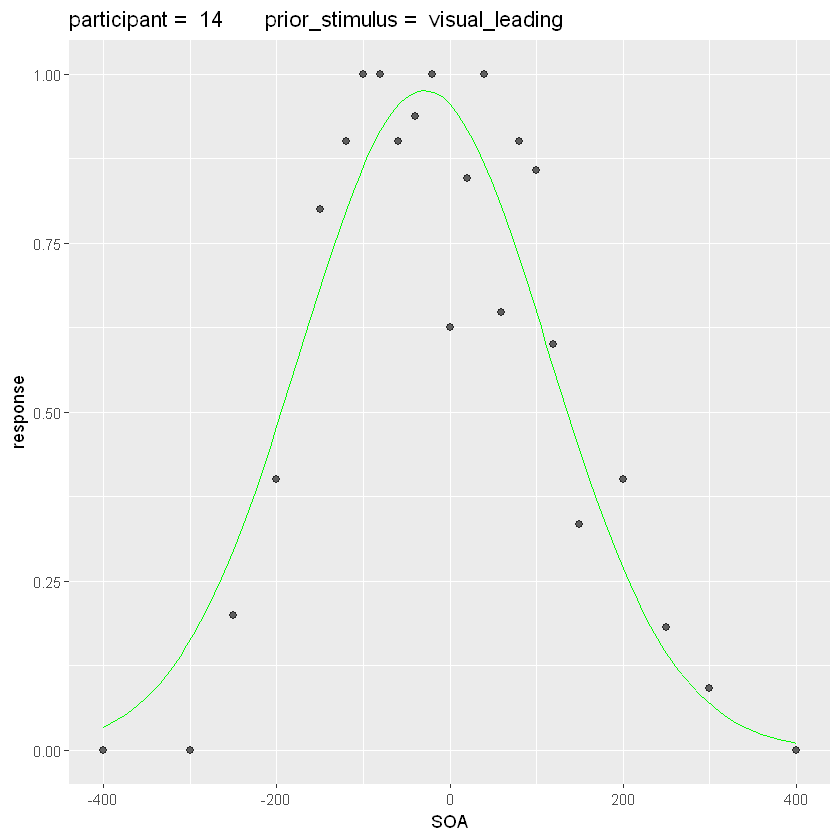

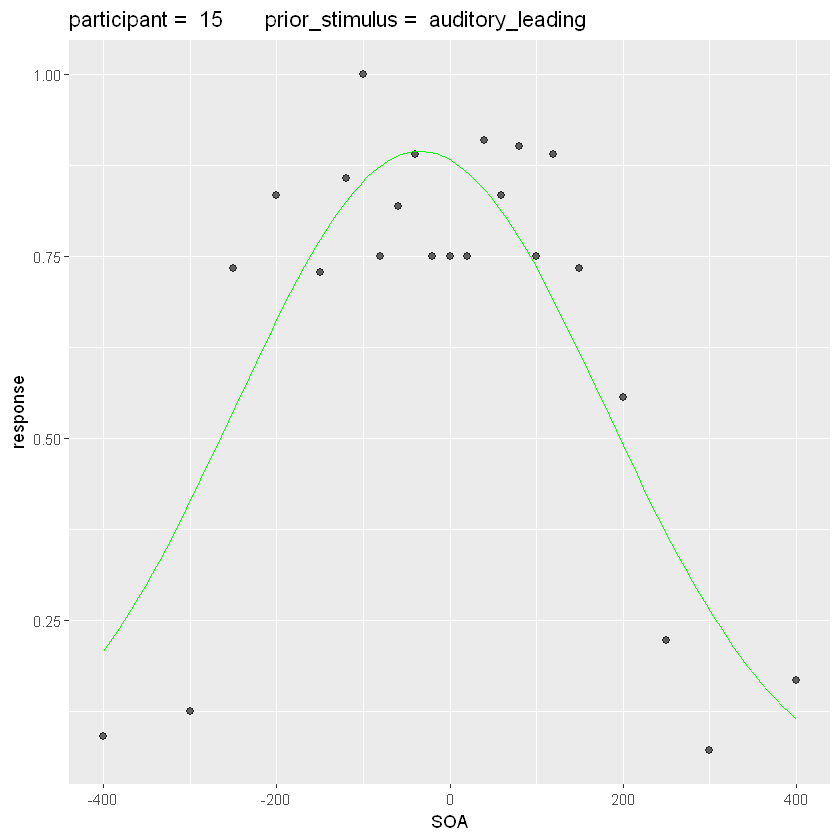

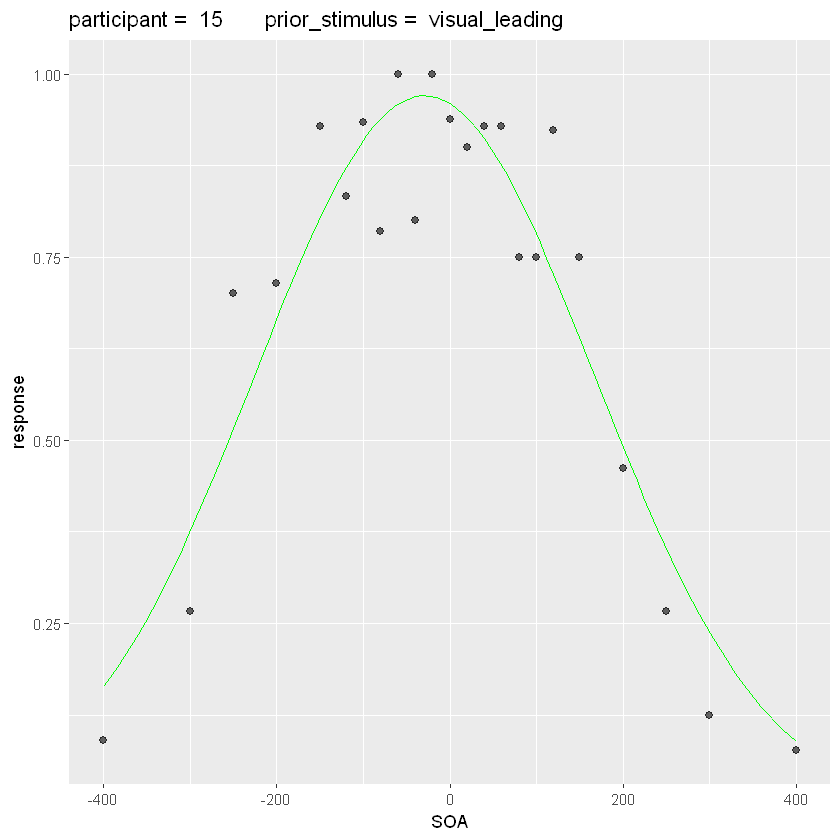

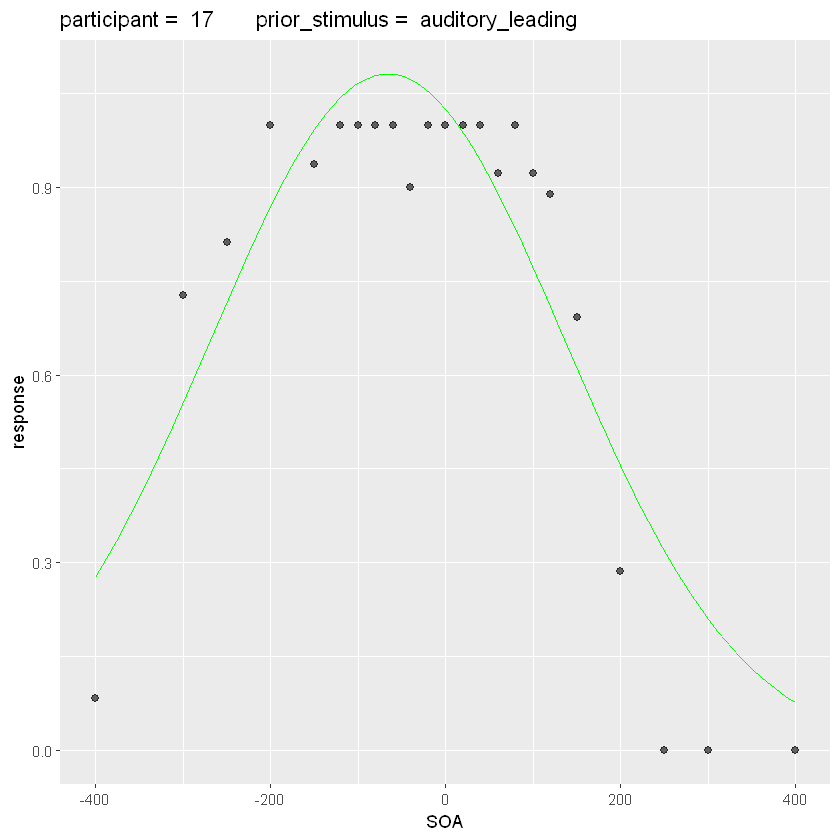

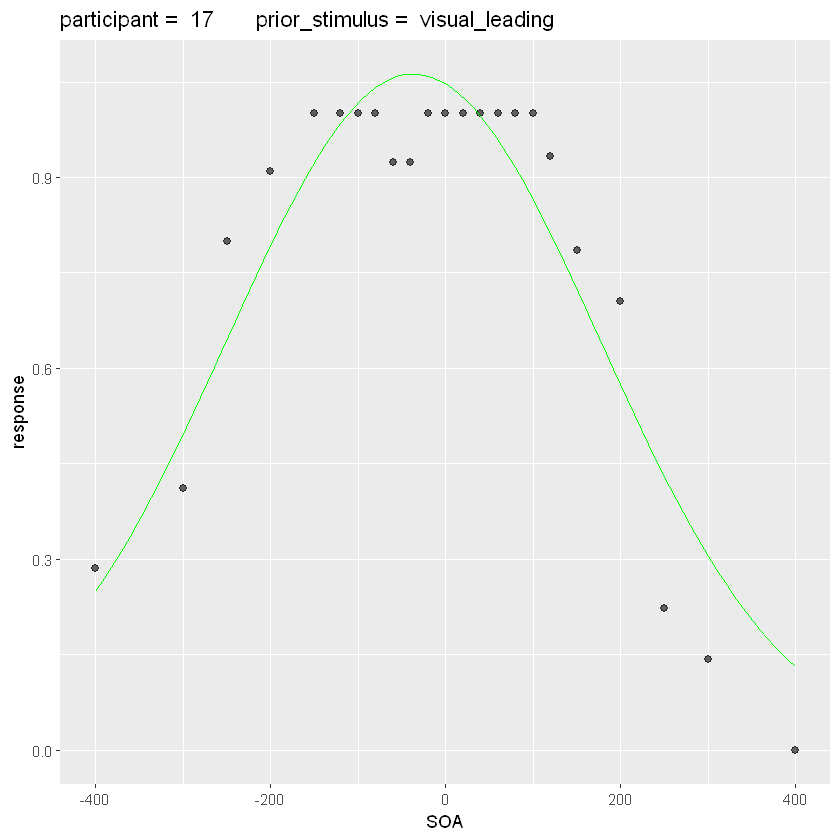

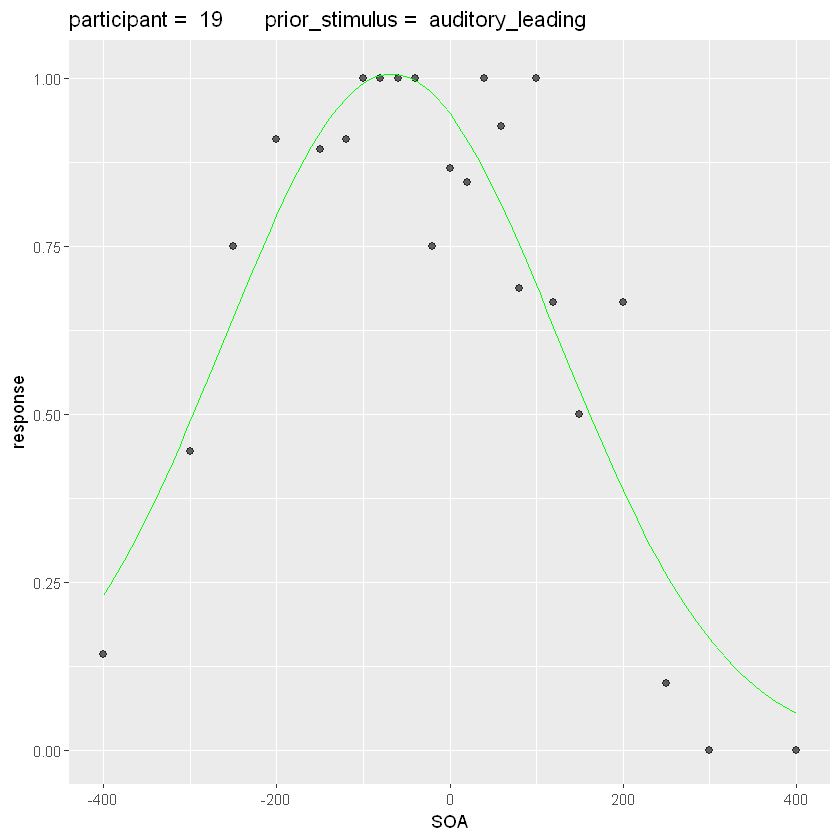

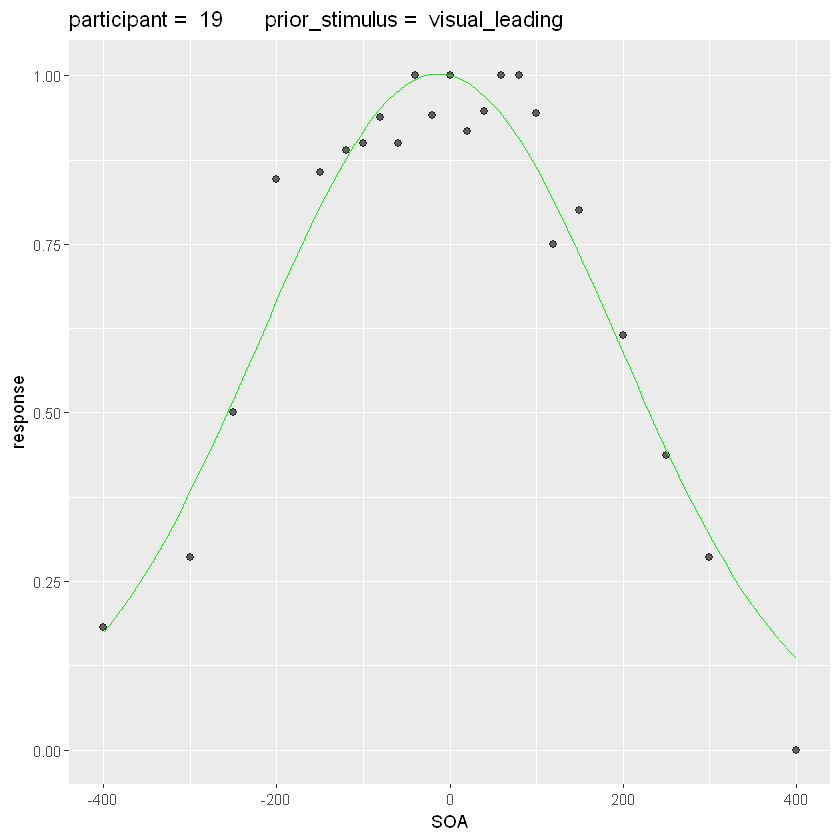

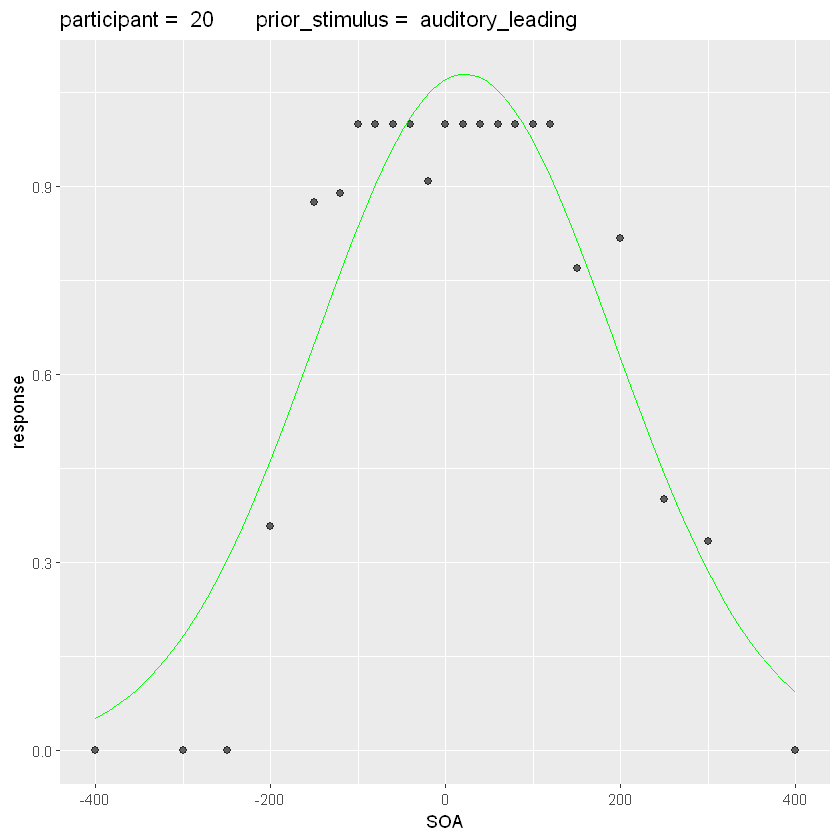

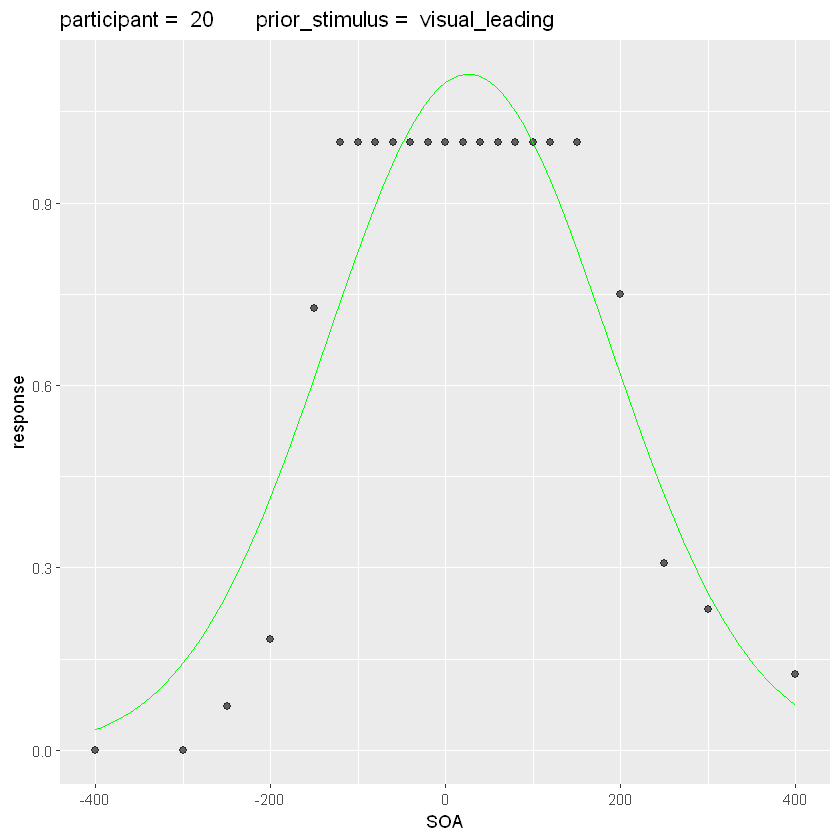

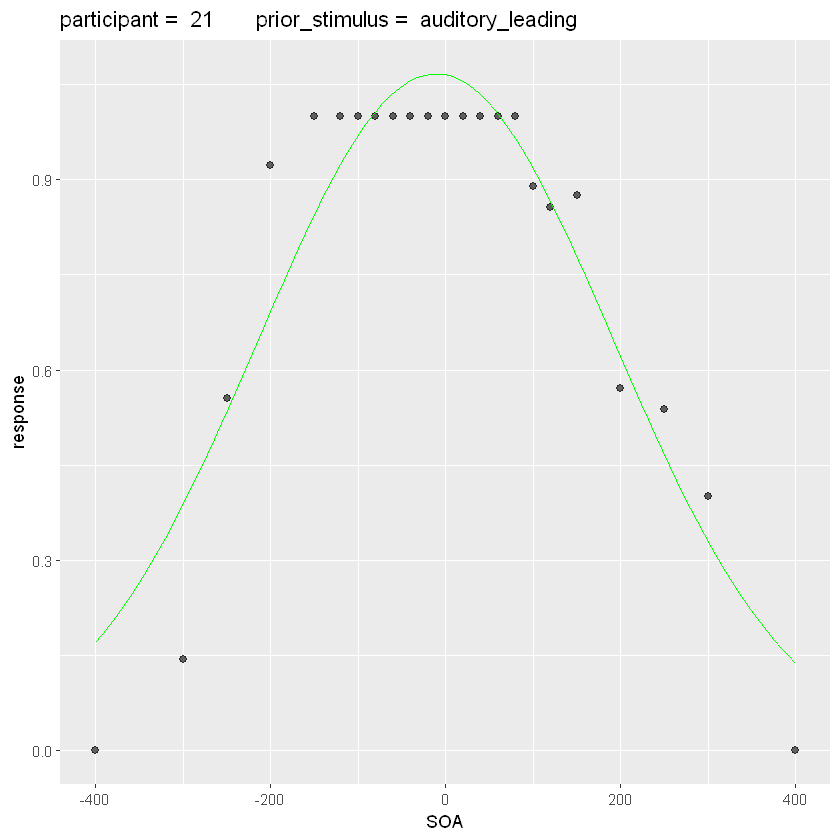

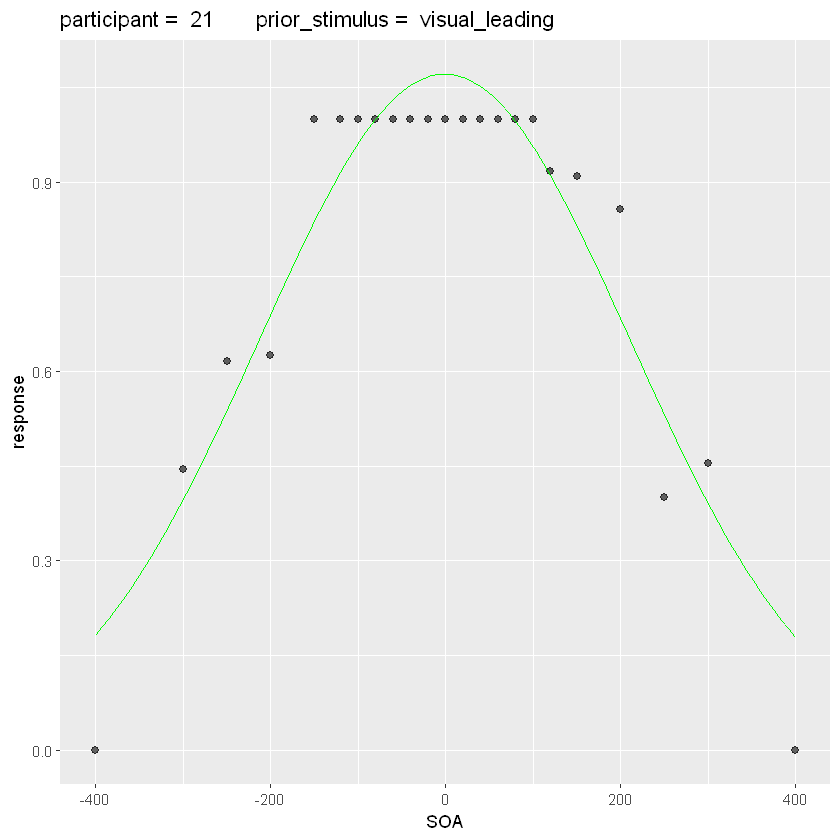

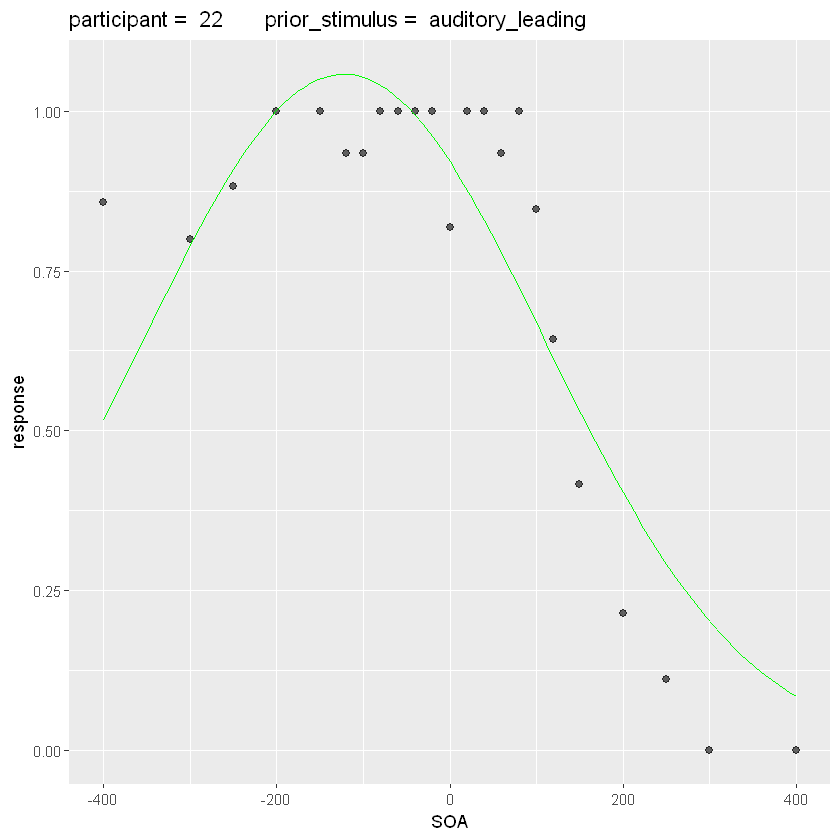

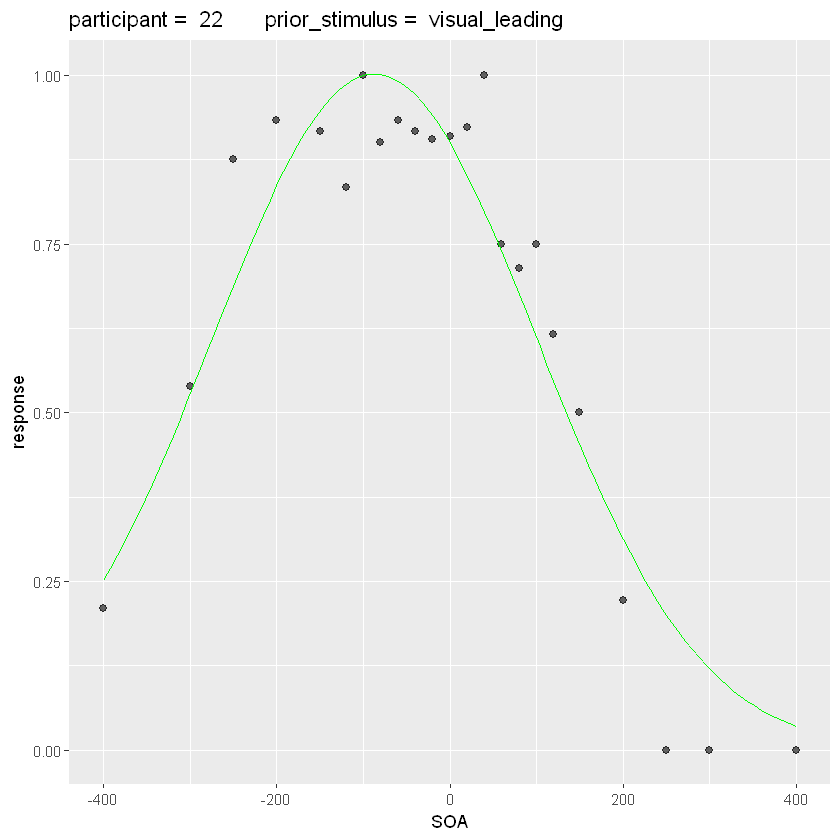

In [129]:
ff <- function(x,amp,pss,sd){
    amp * exp(-(x - pss)^2 / (2 * sd^2))
}

data_mean <- data %>% group_by(participant, pre_stim, SOA) %>%   
    summarise(
                response = mean(resp == 1),
                n_trials = n(),
                .groups = "drop"
              )

for(subj in unique(data$participant)){

    d1 <- data_mean %>% filter(participant == subj)
    # print(subj)
    for(ps in unique(data$pre_stim)){
        d2 <- d1 %>% filter(pre_stim == ps)
        # print(ps)

        amp <- (results %>% filter(participant == subj) %>% filter(pre_stim == ps))$amp
        pss <- (results %>% filter(participant == subj) %>% filter(pre_stim == ps))$pss
        sd <- (results %>% filter(participant == subj) %>% filter(pre_stim == ps))$sd
        print(ggplot(d2, aes(x = SOA, y = response)) +
                geom_point(size = 2, alpha = 0.6) +
                geom_function(fun=ff, args = list(amp = amp, pss = pss, sd = sd), color='green') +
                labs(title = paste('participant = ',subj,'      prior_stimulus = ',ps)))
            
}}

In [9]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){

  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)

  return(1 - SS_res / SS_tot)

}

results$R2 <- NA

for(i in 1:nrow(results)){

    id <- results$participant[i]
    ps <- results$pre_stim[i]

  subdata <- data_mean %>% filter(participant == id) %>% filter(pre_stim == ps)

  pred <- ff(subdata$SOA, results$amp[i], results$pss[i], results$sd[i])

  results$R2[i] <- R2(subdata$response, pred)

}

head(results)

,participant,pre_stim,amp,pss,sd,R2
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,auditory_leading,1.0690489,-30.60426,168.9199,0.9147492
2,1,visual_leading,1.0785335,-19.29710,178.1637,0.8895358
3,3,auditory_leading,0.6513385,-68.84329,156.0357,0.7460158
4,3,visual_leading,0.7122981,-68.02147,147.2678,0.8128971
5,4,auditory_leading,0.7108518,-72.35237,207.1948,0.7297632
6,4,visual_leading,0.6711697,-85.21178,186.4913,0.8313777


In [34]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){

  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)

  return(1 - SS_res / SS_tot)

}

results$R2 <- NA

for(i in 1:nrow(results)){

    id <- results$participant[i]
    ps <- results$pre_stim[i]

  subdata <- data %>% filter(participant == id) %>% filter(pre_stim == ps)

  pred <- ff(subdata$SOA, results$amp[i], results$pss[i], results$sd[i])

  results$R2[i] <- R2(subdata$resp, pred)

}

head(results)

,participant,pre_stim,amp,pss,sd,R2
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,auditory_leading,1.0690489,-30.60426,168.9199,0.5853885
2,1,visual_leading,1.0785335,-19.29710,178.1637,0.6268460
3,3,auditory_leading,0.6513385,-68.84329,156.0357,0.2069951
4,3,visual_leading,0.7122981,-68.02148,147.2678,0.2507434
5,4,auditory_leading,0.7108518,-72.35237,207.1948,0.1961525
6,4,visual_leading,0.6711697,-85.21178,186.4913,0.1813676


In [35]:
###############################################################
# Exclude participants with poor psychometric fits
# Criterion: R² < 0.50
###############################################################

results %>% filter(R2<.5)

participant,pre_stim,amp,pss,sd,R2
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
3,auditory_leading,0.6513385,-68.843287,156.0357,0.20699509
3,visual_leading,0.7122981,-68.021475,147.2678,0.25074343
4,auditory_leading,0.7108518,-72.352373,207.1948,0.19615250
4,visual_leading,0.6711697,-85.211784,186.4913,0.18136757
5,auditory_leading,1.0234245,-21.802764,196.9169,0.45181947
5,visual_leading,1.0282885,-1.132682,187.0687,0.49243651
6,auditory_leading,0.5059989,16.098781,157.3042,0.11444718
6,visual_leading,0.4833966,2.252168,182.9120,0.09465596
7,auditory_leading,0.8105812,70.235423,333.2821,0.10104474


In [36]:
sort(results$R2)

[1] 0.09465596 0.10104474 0.10724824 0.11444718 0.16313617 0.18136757
 [7] 0.19615250 0.20699509 0.23867119 0.25074343 0.28586230 0.31016638
[13] 0.32232125 0.36312666 0.36692232 0.37709854 0.39185505 0.39402176
[19] 0.39715483 0.40161239 0.40495888 0.45181947 0.45860147 0.46794313
[25] 0.47470448 0.49243651 0.50651334 0.51660813 0.52509686 0.52529661
[31] 0.54414374 0.56214394 0.58538849 0.59289992 0.60533441 0.62252820
[37] 0.62380996 0.62684604 0.63762456 0.64070996 0.66293395 0.68753426

In [39]:
results %>% filter(R2<.2) %>% arrange(R2)

participant,pre_stim,amp,pss,sd,R2
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
6,visual_leading,0.4833966,2.252168,182.9120,0.09465596
7,auditory_leading,0.8105812,70.235423,333.2821,0.10104474
7,visual_leading,0.8665195,126.079890,389.3074,0.10724824
6,auditory_leading,0.5059989,16.098781,157.3042,0.11444718
18,visual_leading,0.9766575,-20.768032,369.4946,0.16313617
4,visual_leading,0.6711697,-85.211784,186.4913,0.18136757
4,auditory_leading,0.7108518,-72.352373,207.1948,0.19615250


In [36]:
quadratic_results <- data.frame()
for (par in unique(data$participant)) {
    df_subset1 <- data_mean %>% filter(participant == par)
    for(ps in unique(data$pre_stim)){
        df_subset2 <- df_subset1 %>% filter(pre_stim == ps)
        fit <- lm(response ~ SOA + I(SOA^2), data = df_subset2)
        quadratic_results <- rbind(quadratic_results, data.frame(
                participant = par,
                p = summary(fit)$coefficients[3,4]))
        
}}

In [40]:
quadratic_results <- data.frame()
for (par in unique(data$participant)) {
    df_subset1 <- data %>% filter(participant == par)
    for(ps in unique(data$pre_stim)){
        df_subset2 <- df_subset1 %>% filter(pre_stim == ps)
        fit <- lm(resp ~ SOA + I(SOA^2), data = df_subset2)
        quadratic_results <- rbind(quadratic_results, data.frame(
                participant = par,
                p = summary(fit)$coefficients[3,4]))
        
}}

In [41]:
sort(quadratic_results$p)

[1] 4.049386e-56 1.035016e-55 1.446950e-53 1.475405e-53 1.231649e-51
 [6] 3.272639e-50 1.314434e-49 1.790628e-49 2.924868e-48 1.113404e-46
[11] 2.695637e-46 2.168062e-45 9.813685e-42 8.538124e-40 2.118041e-33
[16] 8.756664e-33 2.245950e-32 3.035084e-32 4.165788e-32 4.808811e-32
[21] 1.683910e-31 4.389363e-31 2.915550e-30 6.086052e-28 1.880420e-26
[26] 1.151085e-25 8.757391e-22 1.996949e-21 7.718344e-21 1.565360e-19
[31] 5.319987e-17 7.005156e-17 1.154432e-16 2.279218e-13 1.461577e-11
[36] 1.464371e-11 7.691815e-11 1.968741e-10 6.556972e-07 8.091228e-07
[41] 1.155442e-06 4.753102e-05

In [48]:
quadratic_results[quadratic_results$p> 10^-08,]

,participant,p
,<dbl>,<dbl>
9,6,1.155442e-06
10,6,8.091228e-07
11,7,6.556972e-07
12,7,4.753102e-05


In [130]:
write_xlsx(results, "files2/SJ_prior_stimulus_psychometric_parameters.xlsx")

###############################################################\
###############################################################
# 3 Prior response preprocessing

- Remove outlier participants
- Remove catch trials.
- Remove unimodal trials (auditory-only, visual-only).
- Remove anticipatory responses (RT < 100 ms).
- Remove missed trials.
- Remove RT outliers (> ±2.5 SD within participant × condition).
- Remove the first trial of each mini-block and trials following missed responses.
- Remove trials following catch trials.

In [80]:
data <- read_xlsx("files/SJ_data.xlsx")
head(data)

participant,TrialType,resp,rt
<dbl>,<chr>,<chr>,<dbl>
1,auditroy_only,asynchrony,1.220187
1,audiovisual_SOA_40,synchrony,1.069805
1,auditroy_only,asynchrony,1.186716
1,audiovisual_SOA_80,synchrony,1.353749
1,audiovisual_SOA_100,synchrony,1.270390
1,audiovisual_SOA_80,synchrony,1.220155


In [81]:
n_participants = length(unique(data$participant))
n_type = length(unique(data$TrialType))

In [82]:
nrow(data)

[1] 17160

In [83]:
n_type * n_participants * 30

[1] 17160

In [84]:
###############################################################
# Remove participants with poor sigmoid model fit
###############################################################

n_current <- nrow(data)
data <- data[!(data$participant %in% c(2,6,16,18)),]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  3120      number of remaining datapoints:  14040"


In [85]:
nrow(data)

[1] 14040

In [86]:
n_type * (n_participants-4) * 30

[1] 14040

In [87]:
### Create variables describing the previous trial stimulus and response
j <- data$TrialType
j <- append(j, NA, after=0)
j <- j[-c(length(j))]
data$pre_stim <- j

j <- data$resp
j <- append(j, NA, after=0)
j <- j[-c(length(j))]
data$pre_resp <- j

head(data)

participant,TrialType,resp,rt,pre_stim,pre_resp
<dbl>,<chr>,<chr>,<dbl>,<chr>,<chr>
1,auditroy_only,asynchrony,1.220187,NA,NA
1,audiovisual_SOA_40,synchrony,1.069805,auditroy_only,asynchrony
1,auditroy_only,asynchrony,1.186716,audiovisual_SOA_40,synchrony
1,audiovisual_SOA_80,synchrony,1.353749,auditroy_only,asynchrony
1,audiovisual_SOA_100,synchrony,1.270390,audiovisual_SOA_80,synchrony
1,audiovisual_SOA_80,synchrony,1.220155,audiovisual_SOA_100,synchrony


In [88]:
###############################################################
# Determine the first trial of each mini-block.
# In this experiment each mini-block contains 30 trials.
# The first trial is removed because it has no valid previous-trial history.

data$pre_resp[as.numeric(row.names(data)) %% 30==1] <- NA

In [89]:
nrow(data)

[1] 14040

In [90]:
# Remove trials catch
###############################################################
n_current <- nrow(data)
data <- data[data$TrialType!='catch',]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  540      number of remaining datapoints:  13500"


In [91]:
###############################################################
# Remove unimodal conditions (auditory-only, visual-only)
# as the analysis focuses on audiovisual temporal judgments
###############################################################
n_current <- nrow(data)
data <- data %>%
    filter(!TrialType %in% c("auditroy_only", "visual_only"))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  1080      number of remaining datapoints:  12420"


In [92]:
(n_type-3) * (n_participants-4) * 30

[1] 12420

In [93]:
# Remove anticipatory responses (RT < 100 ms)

n_current <- nrow(data)
data <- data[data$rt>=.1,]
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  2      number of remaining datapoints:  12418"


In [94]:
# Remove missed trials

n_current <- nrow(data)
data <- data %>% filter(!is.na(resp))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  0      number of remaining datapoints:  12418"


In [95]:
###############################################################
# Remove RT outliers within each participant × condition
# using a ±2 SD criterion
###############################################################

n_current <- nrow(data)
data <- data %>%
  group_by(participant, TrialType) %>%
  filter(
    rt < mean(rt) + 2.5*sd(rt) &
    rt > mean(rt) - 2.5*sd(rt)
  ) %>%
  ungroup()
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  407      number of remaining datapoints:  12011"


In [96]:
# Remove the first trial of each mini-block and trials following missed responses.

n_current <- nrow(data)
data <- data %>% filter(!is.na(pre_resp))
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  806      number of remaining datapoints:  11205"


In [97]:
###############################################################
# Remove trials that follow a catch trial
###############################################################

n_current <- nrow(data)
data <- filter(data, pre_stim!='catch')
n_filtered <- n_current - nrow(data)
print(paste('number of deleted datapoints: ', n_filtered, "     number of remaining datapoints: ", nrow(data)))

[1] "number of deleted datapoints:  0      number of remaining datapoints:  11205"


In [98]:
###############################################################
# Map TrialType to signed SOA values
###############################################################

TT <- c(
'audiovisual_NSOA_100','audiovisual_NSOA_120','audiovisual_NSOA_150','audiovisual_NSOA_20',
'audiovisual_NSOA_200','audiovisual_NSOA_250','audiovisual_NSOA_300','audiovisual_NSOA_40',
'audiovisual_NSOA_400','audiovisual_NSOA_60','audiovisual_NSOA_80',
'audiovisual_SOA_0',
'audiovisual_SOA_100','audiovisual_SOA_120','audiovisual_SOA_150','audiovisual_SOA_20',
'audiovisual_SOA_200','audiovisual_SOA_250','audiovisual_SOA_300','audiovisual_SOA_40',
'audiovisual_SOA_400','audiovisual_SOA_60','audiovisual_SOA_80'
)

SOA_vals <- c(
-100,-120,-150,-20,-200,-250,-300,-40,-400,-60,-80,
0,
100,120,150,20,200,250,300,40,400,60,80
)

soa_map <- data.frame(TrialType = TT, SOA = SOA_vals)

data <- data %>%
  filter(TrialType %in% TT) %>%
  left_join(soa_map, by = "TrialType")
data <- data %>% arrange(participant, pre_resp, SOA)
data <- data[c(1,6,7,3,4)]
head(data)

participant,pre_resp,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,asynchrony,-400,asynchrony,1.437342
1,asynchrony,-400,asynchrony,1.169998
1,asynchrony,-400,asynchrony,1.236840
1,asynchrony,-400,asynchrony,1.186734
1,asynchrony,-400,asynchrony,1.403907
1,asynchrony,-400,asynchrony,1.069756


In [218]:
write.xlsx(data, "files/SJ_prior_response_data.xlsx", rowNames = FALSE)

In [131]:
###############################################################
# Load SJ serial dependence dataset (prepared previously)
###############################################################

df <- read_xlsx("files2/SJ_prior_response_data.xlsx")
head(df)
###############################################################



participant,pre_resp,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,asynchrony,-400,asynchrony,1.437342
1,asynchrony,-400,asynchrony,1.169998
1,asynchrony,-400,asynchrony,1.236840
1,asynchrony,-400,asynchrony,1.186734
1,asynchrony,-400,synchrony,2.723996
1,asynchrony,-400,asynchrony,1.403907


In [132]:
###############################################################
# Prepare behavioral variables
###############################################################

data <- df %>%
  mutate(
    resp = ifelse(resp == "synchrony", 1, 0)
  )
head(data)

participant,pre_resp,SOA,resp,rt
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,asynchrony,-400,0,1.437342
1,asynchrony,-400,0,1.169998
1,asynchrony,-400,0,1.236840
1,asynchrony,-400,0,1.186734
1,asynchrony,-400,1,2.723996
1,asynchrony,-400,0,1.403907


In [133]:
###############################################################
# Fit Gaussian function to synchorony responses
#
# Model:
# p(SOA) = amp * exp(-(SOA - pss)^2 / (2 * sd^2))
#
# Parameters:
# amp = amplitude
# pss = point of subjective simultaneity
# sd  = temporal binding window width
###############################################################

Gauss <- function(data){

  loss_function <- function(params){

    amp <- params[1]
    pss <- params[2]
    sd  <- params[3]

    predicted <- amp * exp(-(data$SOA - pss)^2 / (2 * sd^2))

    sum((predicted - data$resp)^2)

  }

  DEoptim(
    loss_function,
    lower = c(0, -400, 1),
    upper = c(2, 400, 500)
  )

}

results <- data.frame()

for(subj in unique(data$participant)){
  subdata1 <- data %>% filter(participant == subj)
  for(pr in unique(data$pre_resp)){
  subdata2 <- subdata1 %>% filter(pre_resp == pr)    
  fit <- Gauss(subdata2)$optim$bestmem

  results <- rbind(
    results,
    data.frame(
      participant = subj,
      pre_resp = pr,
      amp = fit[1],
      pss = fit[2],
      sd  = fit[3]
    )
  )
}}

rownames(results) <- NULL

Iteration: 1 bestvalit: 29.302936 bestmemit:    0.831451   48.950653  205.296395
Iteration: 2 bestvalit: 29.302936 bestmemit:    0.831451   48.950653  205.296395
Iteration: 3 bestvalit: 25.762904 bestmemit:    0.929043  -37.352787  139.389218
Iteration: 4 bestvalit: 25.762904 bestmemit:    0.929043  -37.352787  139.389218
Iteration: 5 bestvalit: 24.060593 bestmemit:    1.089878  -12.462344  122.793282
Iteration: 6 bestvalit: 21.073915 bestmemit:    1.089878  -12.462344  160.743345
Iteration: 7 bestvalit: 21.073915 bestmemit:    1.089878  -12.462344  160.743345
Iteration: 8 bestvalit: 21.073915 bestmemit:    1.089878  -12.462344  160.743345
Iteration: 9 bestvalit: 21.073915 bestmemit:    1.089878  -12.462344  160.743345
Iteration: 10 bestvalit: 21.010174 bestmemit:    1.023540   -8.194053  162.465917
Iteration: 11 bestvalit: 21.010174 bestmemit:    1.023540   -8.194053  162.465917
Iteration: 12 bestvalit: 21.010174 bestmemit:    1.023540   -8.194053  162.465917
Iteration: 13 bestvalit: 

In [58]:
head(results)

,participant,pre_resp,amp,pss,sd
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,1,asynchrony,1.0553454,-15.28888,159.5136
2,1,synchrony,1.0747713,-25.58561,181.3664
3,3,asynchrony,0.6802101,-70.90235,156.3591
4,3,synchrony,0.7044108,-66.91638,133.5371
5,4,asynchrony,0.5508617,-108.94569,209.3420
6,4,synchrony,0.8299979,-63.59123,192.8187


In [59]:
# CHeck if the considered bounds for parameters are adequate
print(paste(min(results$amp), '    ', max(results$amp)))
print(paste(min(results$pss), '    ', max(results$pss)))
print(paste(min(results$sd), '    ', max(results$sd)))

[1] "0.451311811711781      1.11677836348375"
[1] "-108.94569235539      71.3316224285879"
[1] "124.913195056876      385.295279177668"


In [60]:
sort(results$amp)

[1] 0.4513118 0.5508617 0.5886924 0.6802101 0.7044108 0.7330108 0.7618324
 [8] 0.8299979 0.8668637 0.8857965 0.8879814 0.8993617 0.9114487 0.9369599
[15] 0.9427890 0.9501450 0.9627628 0.9633281 0.9791593 0.9798649 0.9830394
[22] 0.9944856 1.0028863 1.0066145 1.0298082 1.0311969 1.0354297 1.0541675
[29] 1.0553454 1.0596522 1.0684888 1.0685639 1.0743175 1.0747713 1.0761651
[36] 1.0787105 1.0827573 1.0847258 1.0875397 1.0967738 1.1035739 1.1167784

In [62]:
results %>% filter(amp< .7)

participant,pre_resp,amp,pss,sd
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
3,asynchrony,0.6802101,-70.9023452,156.3591
4,asynchrony,0.5508617,-108.9456924,209.3420
6,asynchrony,0.4513118,15.2106189,147.3116
6,synchrony,0.5886924,-0.4529653,188.5889


In [63]:
sort(results$pss)

[1] -108.9456924 -100.5106695  -93.7990805  -72.8055851  -70.9023452
 [6]  -67.0188744  -66.9163785  -63.5912256  -61.8327818  -60.7593894
[11]  -56.7466131  -54.5297959  -53.9528772  -52.2478681  -51.7233976
[16]  -48.4653980  -48.0333198  -47.1386751  -40.3326673  -39.2242098
[21]  -36.5568496  -26.2615961  -25.5856092  -25.4137674  -25.3955766
[26]  -24.7991202  -15.3711755  -15.2888767  -13.4549077  -11.9013695
[31]   -8.7653569   -8.4570296   -6.5114637   -4.7866936   -3.8418277
[36]   -0.4529653    0.2819744   15.0815556   15.2106189   23.1977920
[41]   59.5883329   71.3316224

In [67]:
results %>% filter(pss< -80)

participant,pre_resp,amp,pss,sd
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
4,asynchrony,0.5508617,-108.94569,209.3420
22,asynchrony,0.9114487,-93.79908,177.8940
22,synchrony,1.0875397,-100.51067,216.5717


In [65]:
results %>% filter(pss> 50)

participant,pre_resp,amp,pss,sd
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
7,asynchrony,0.7618324,59.58833,269.7584
7,synchrony,0.8668637,71.33162,385.2953


In [68]:
sort(results$sd)

[1] 124.9132 125.7186 133.5371 143.5212 147.3116 156.3591 159.5136 161.6474
 [9] 163.1980 163.7537 166.5777 167.3778 167.4770 170.9181 174.2294 177.8940
[17] 179.5624 181.2545 181.3664 183.7891 184.6816 186.3430 187.3772 188.5889
[25] 192.8187 197.6512 198.5386 203.7838 205.8914 209.3420 209.5509 210.1979
[33] 210.9507 214.4976 216.5717 221.1899 234.0283 264.2962 269.7584 320.2709
[41] 339.6943 385.2953

In [69]:
results %>% filter(sd> 300)

participant,pre_resp,amp,pss,sd
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
7,synchrony,0.8668637,71.331622,385.2953
18,asynchrony,0.8857965,-4.786694,320.2709
18,synchrony,1.0028863,-39.224210,339.6943


In [71]:
head(d2)

participant,pre_resp,SOA,response,n_trials
<dbl>,<chr>,<dbl>,<dbl>,<int>


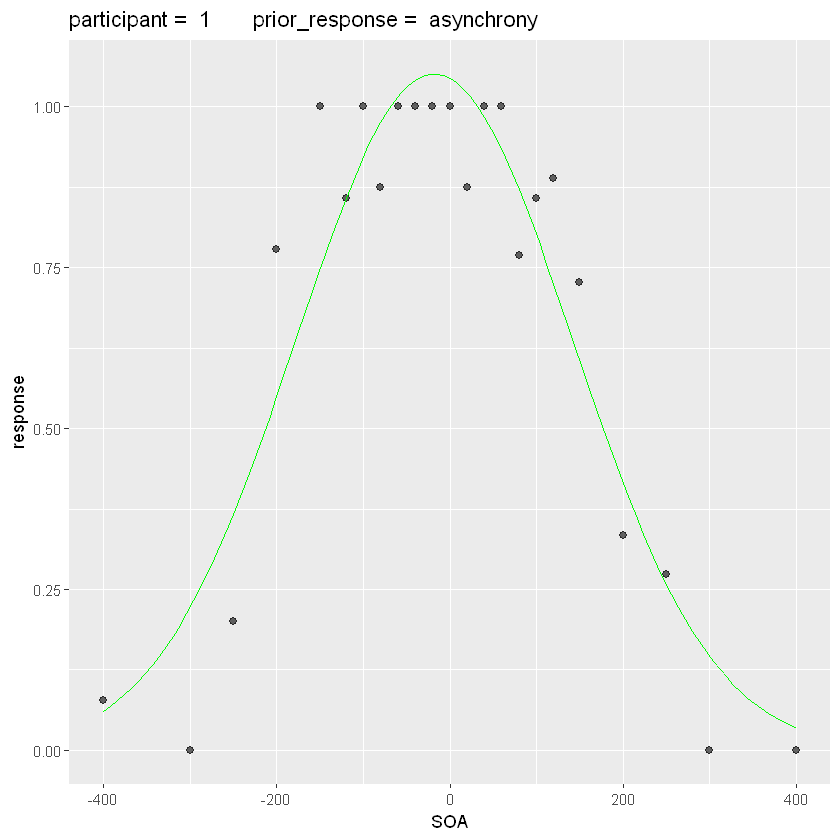

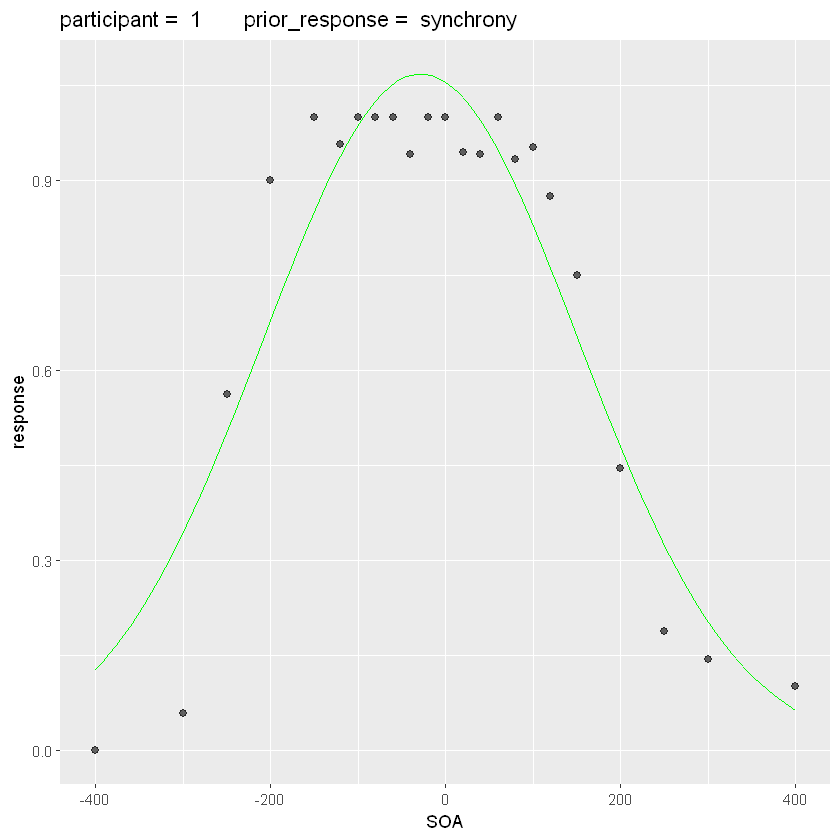

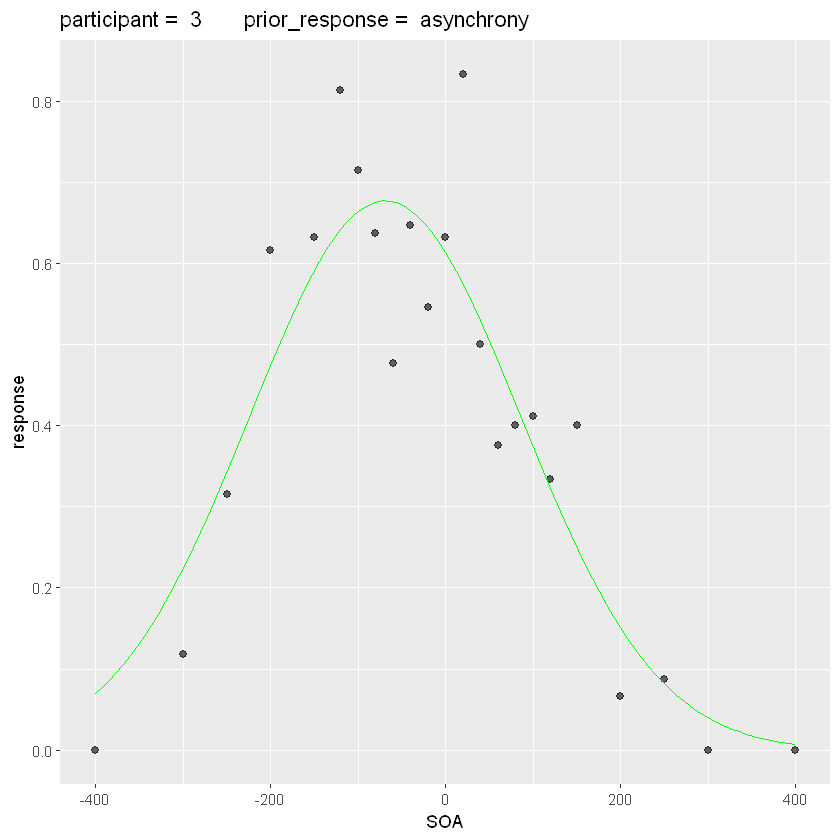

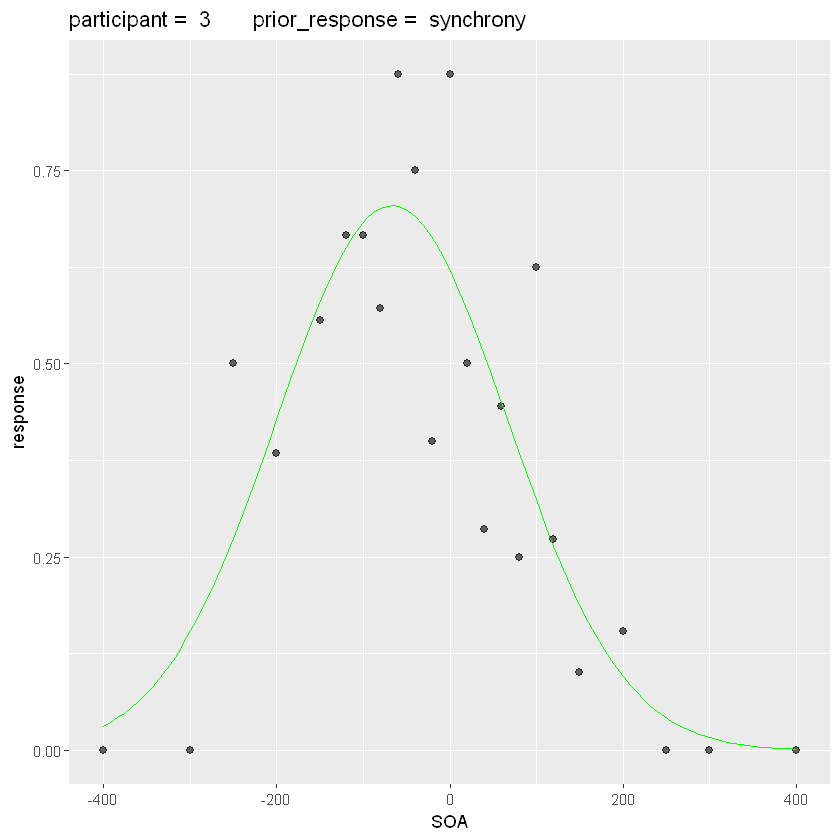

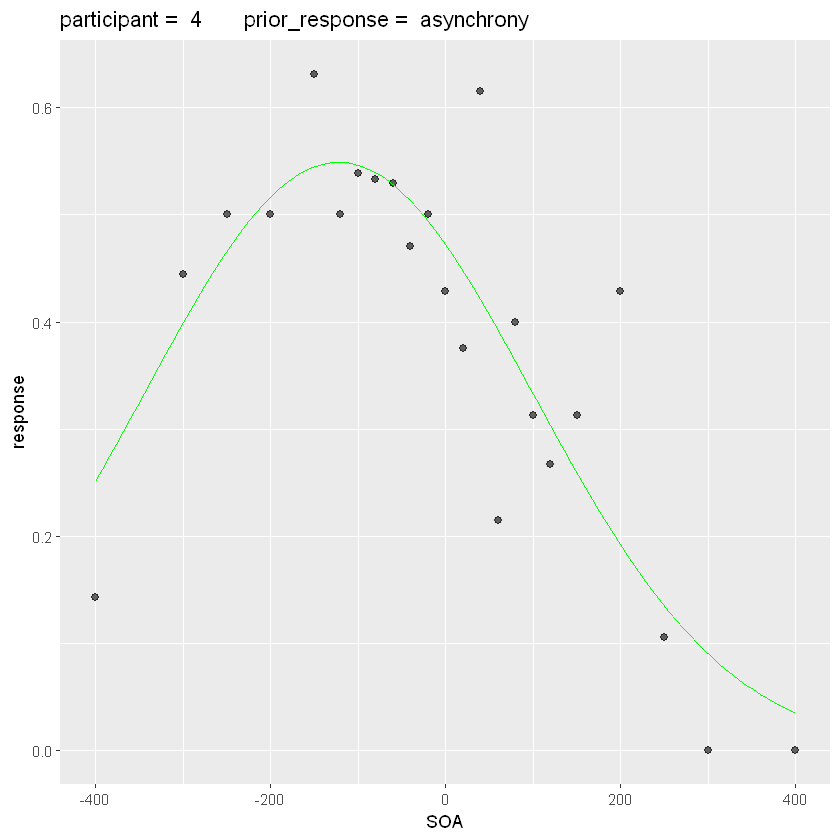

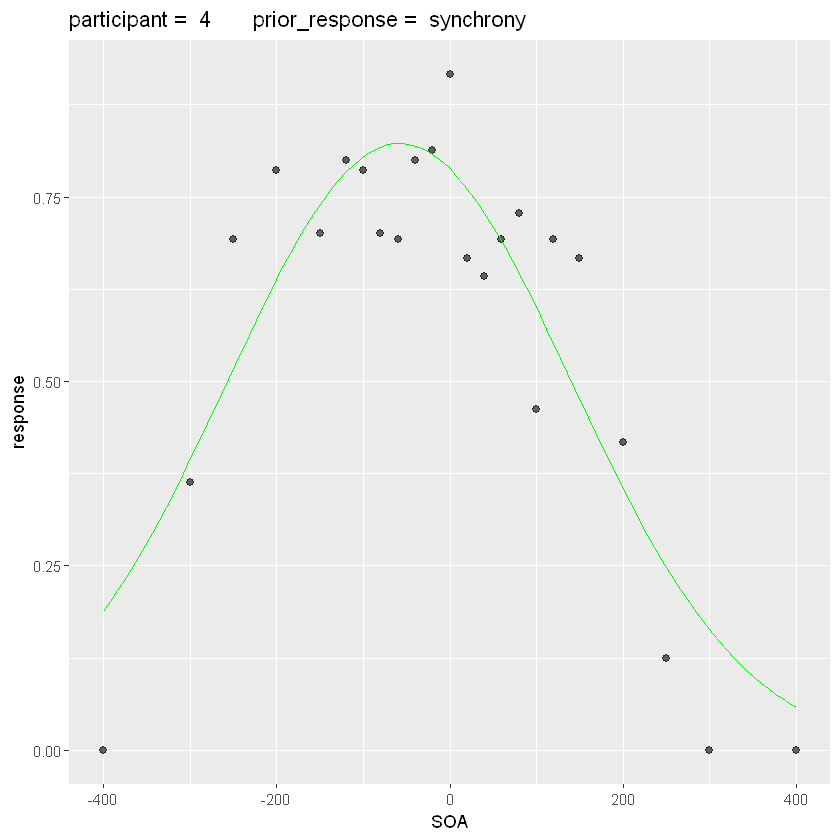

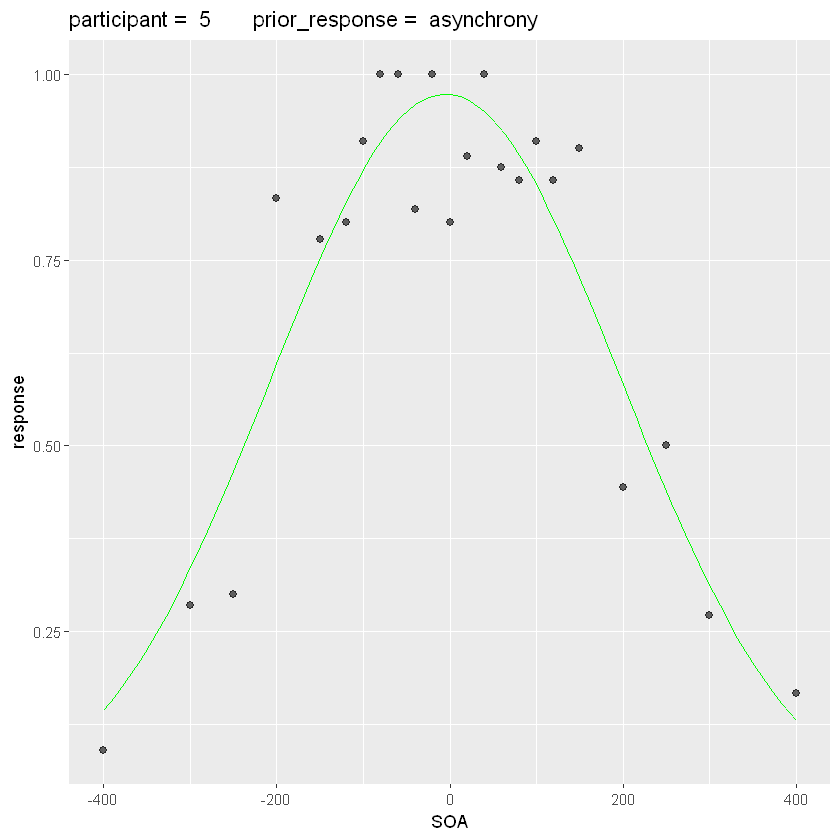

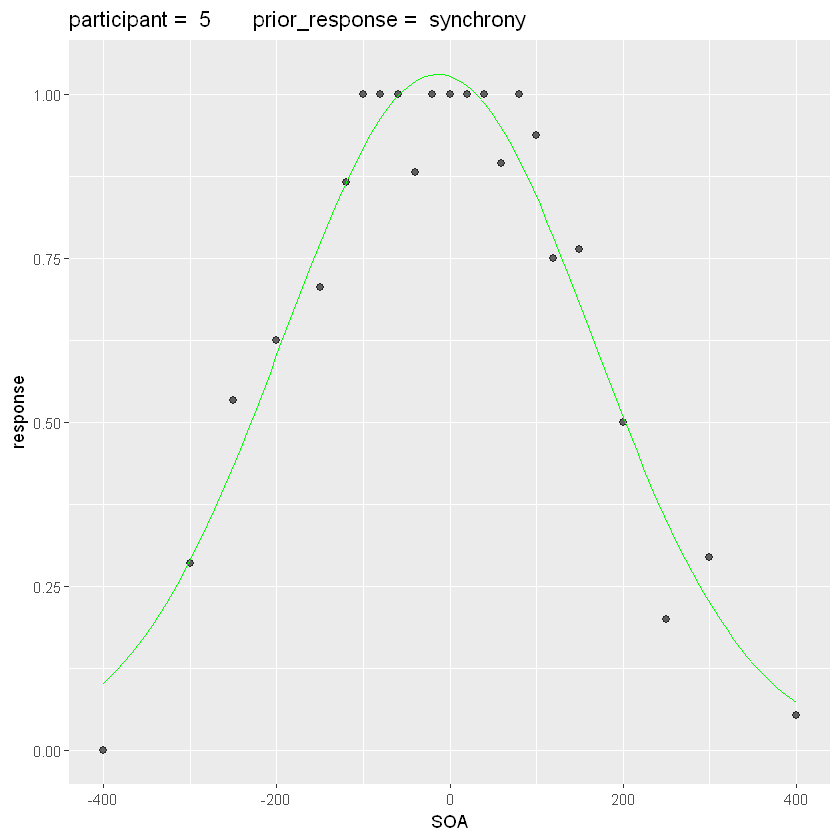

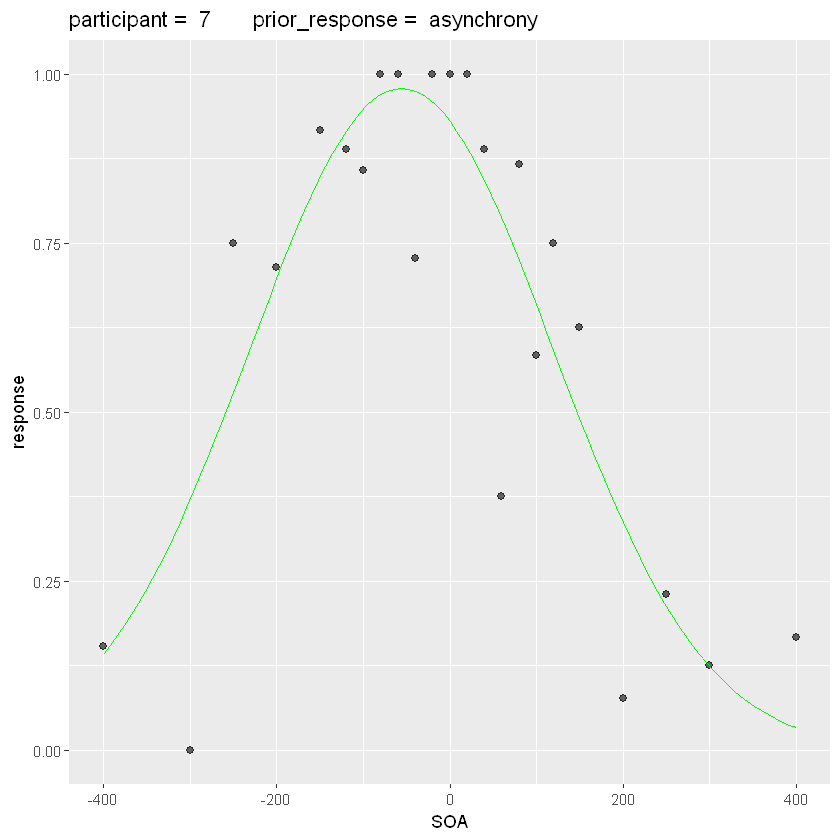

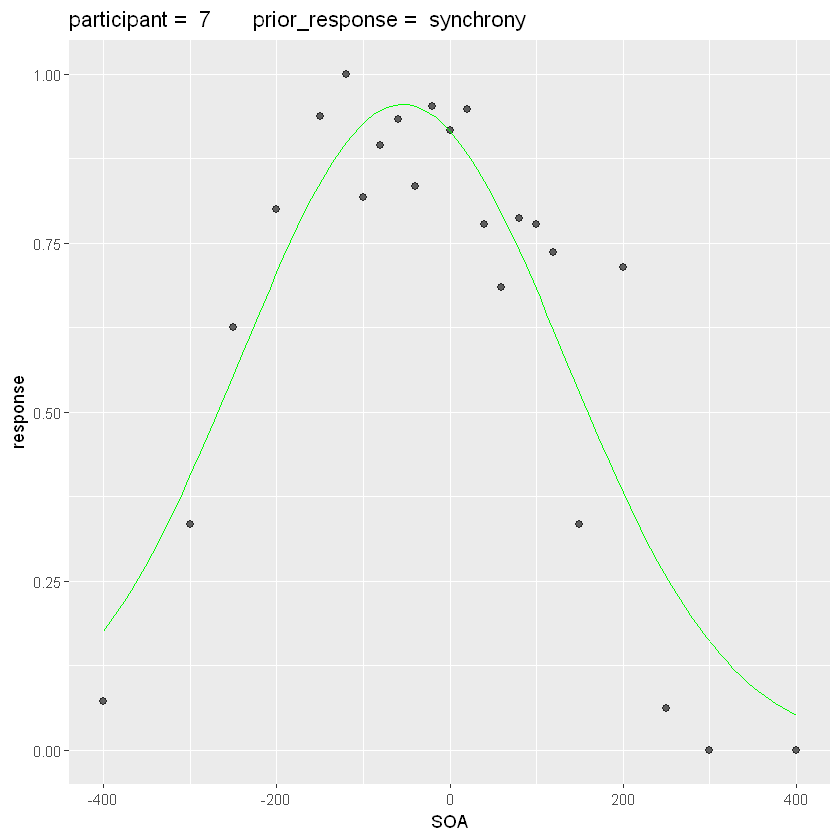

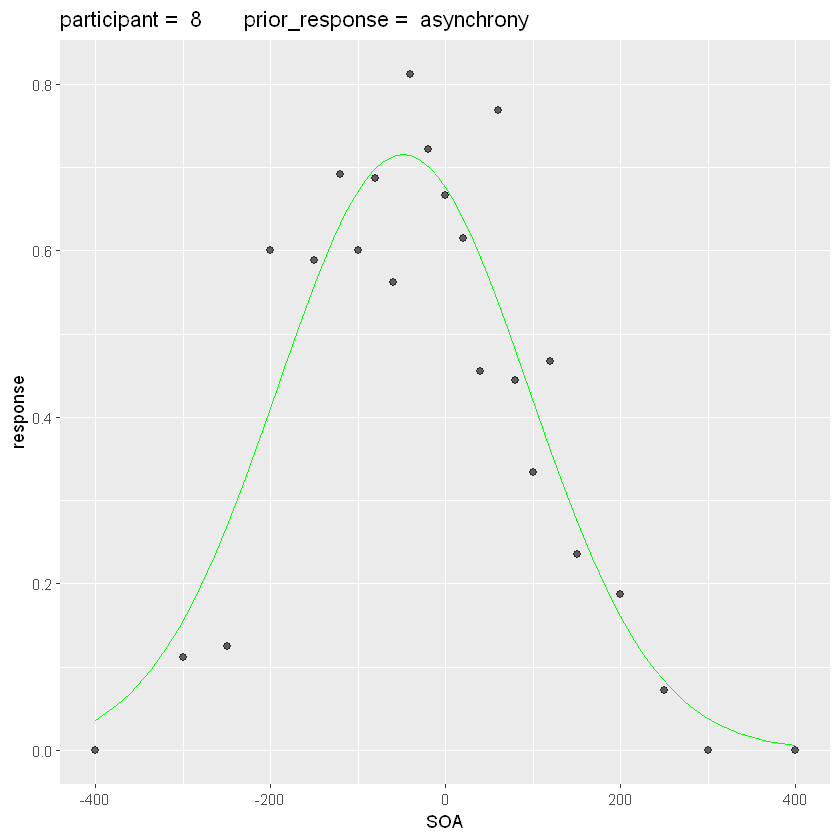

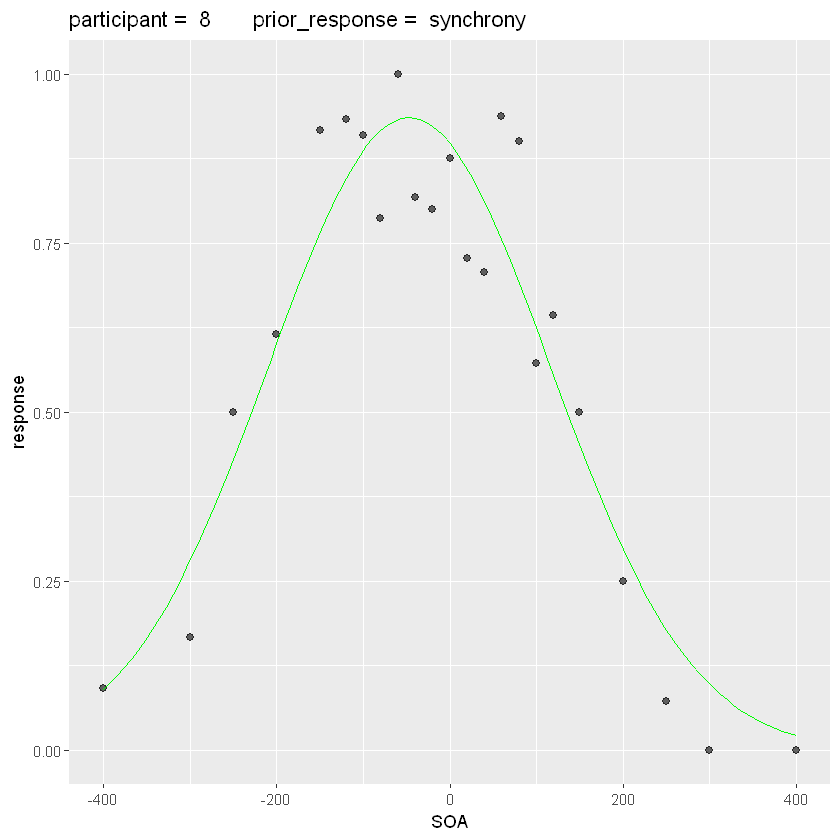

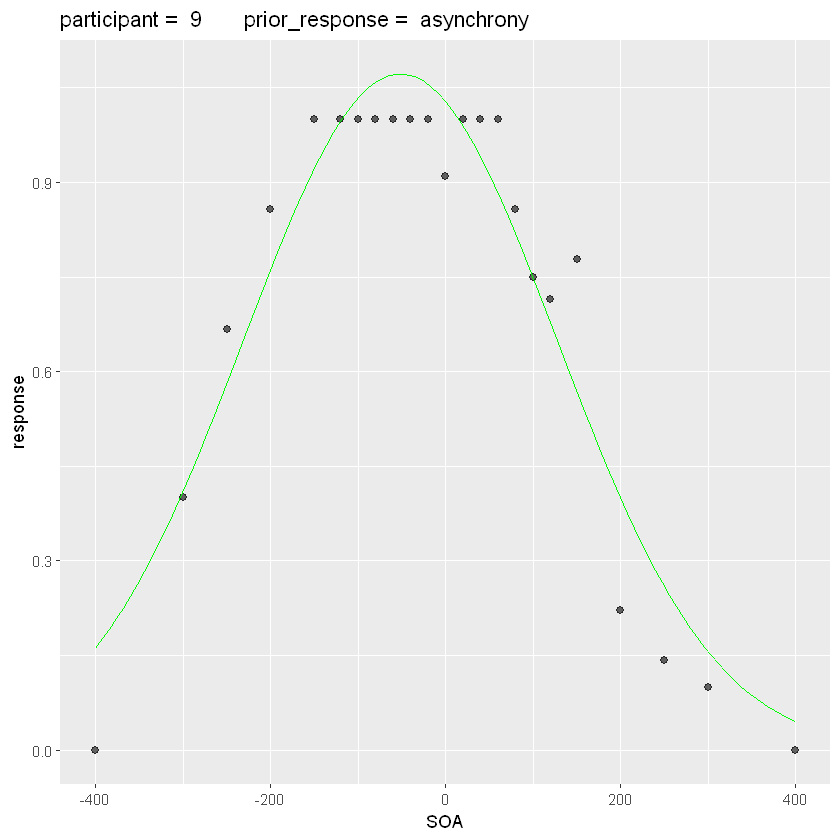

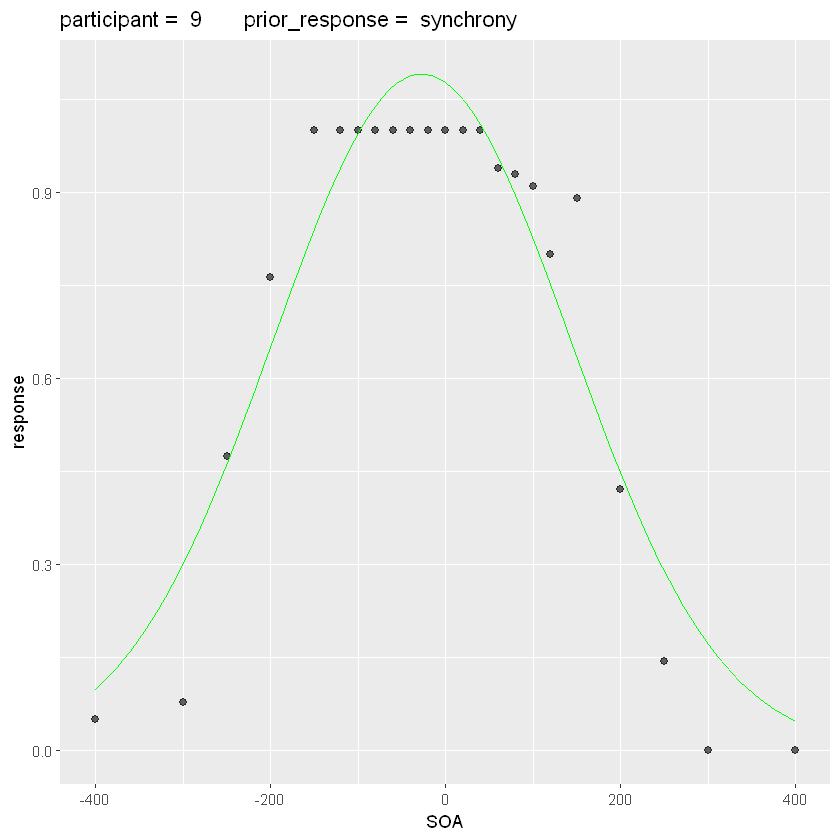

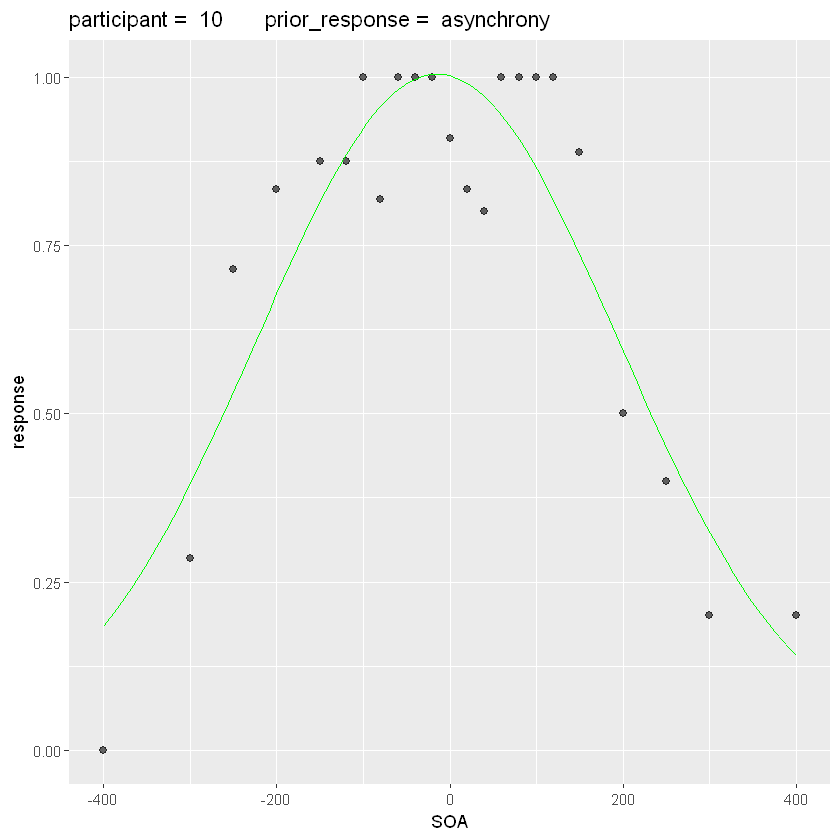

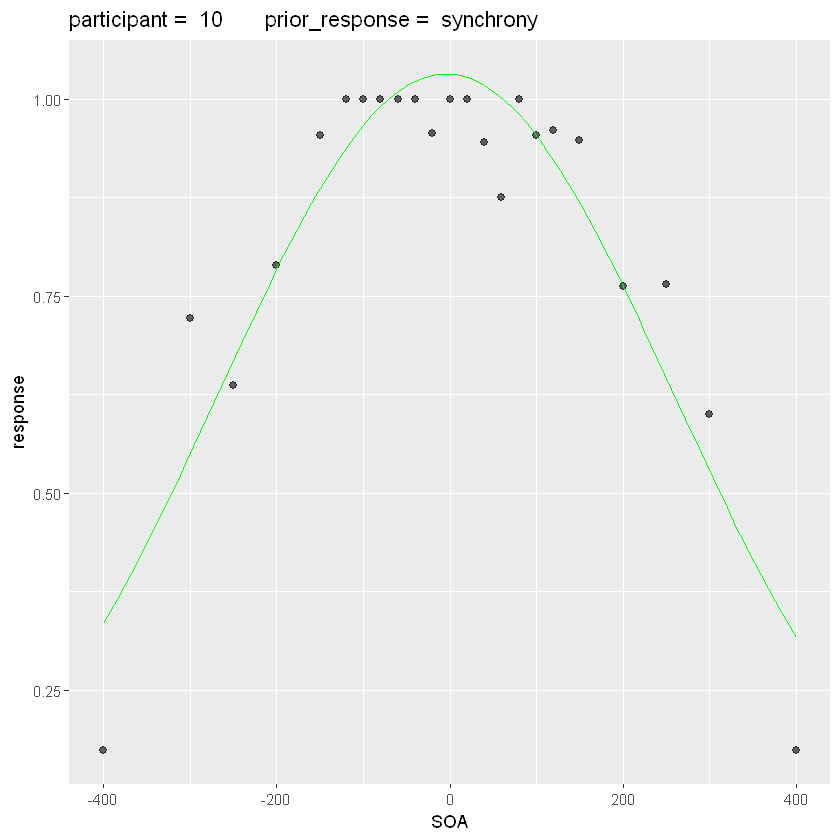

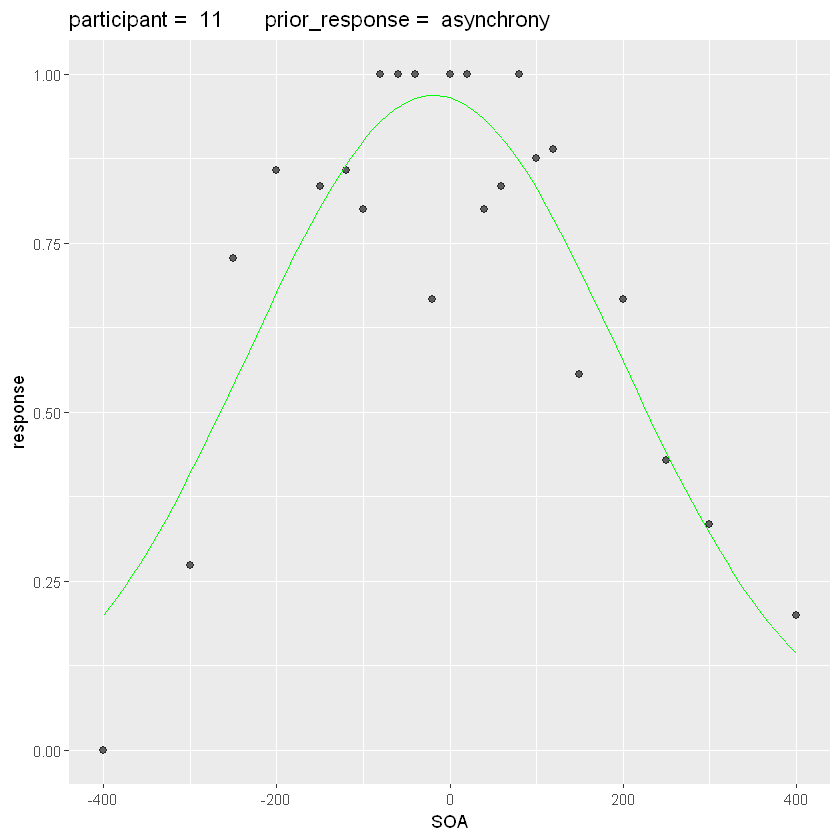

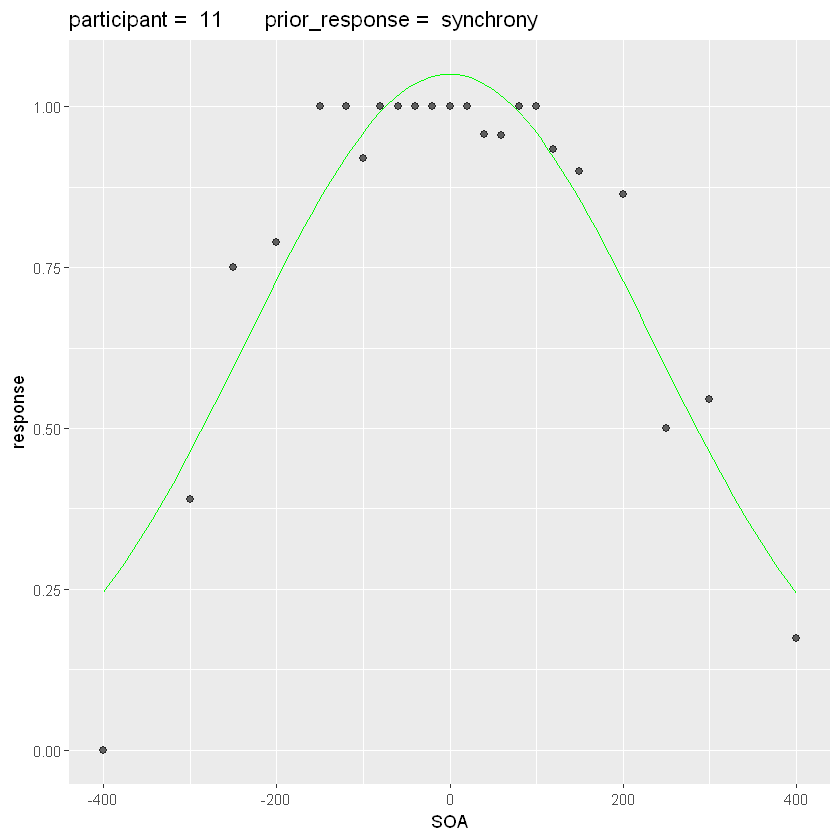

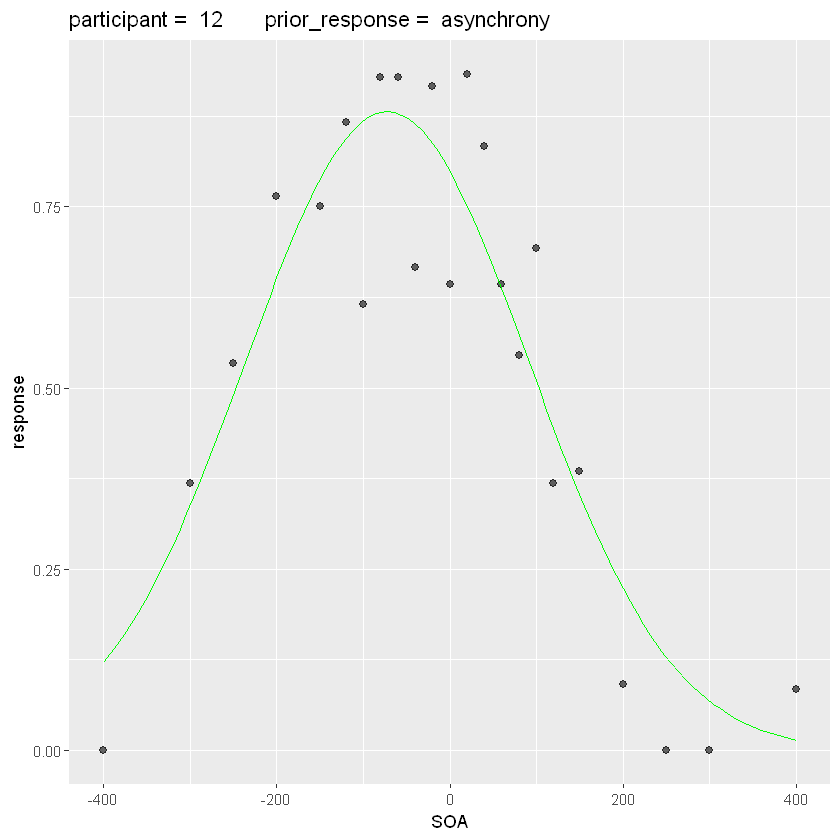

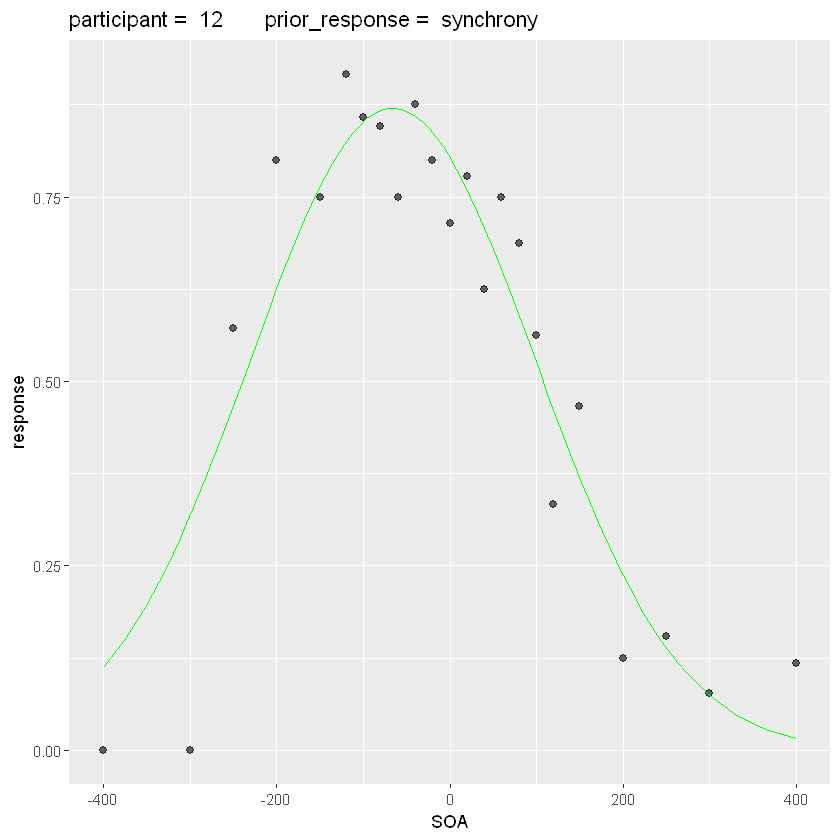

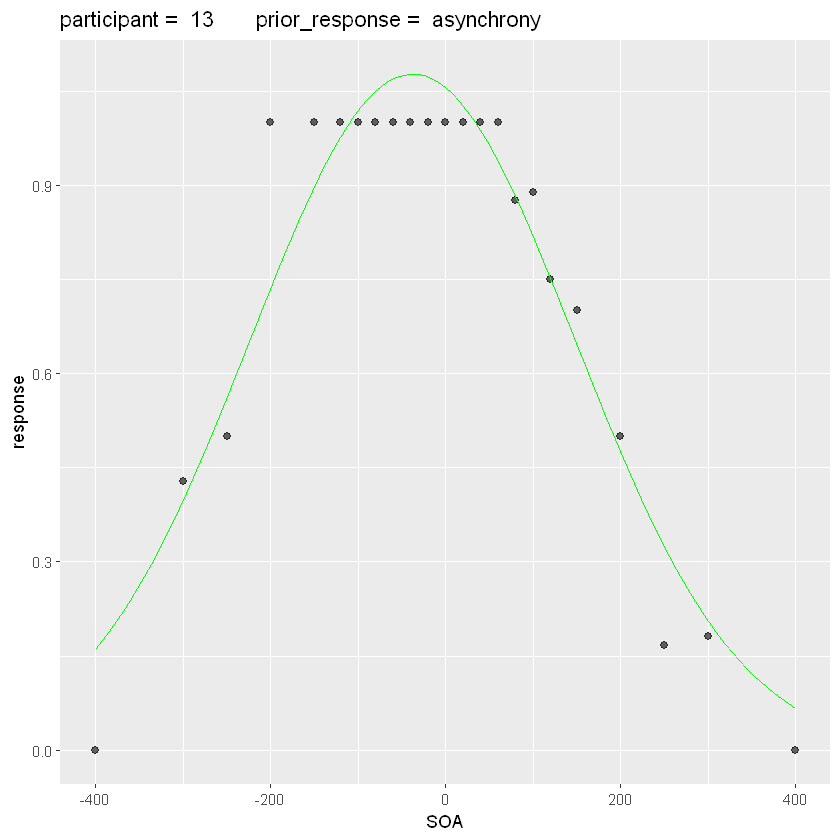

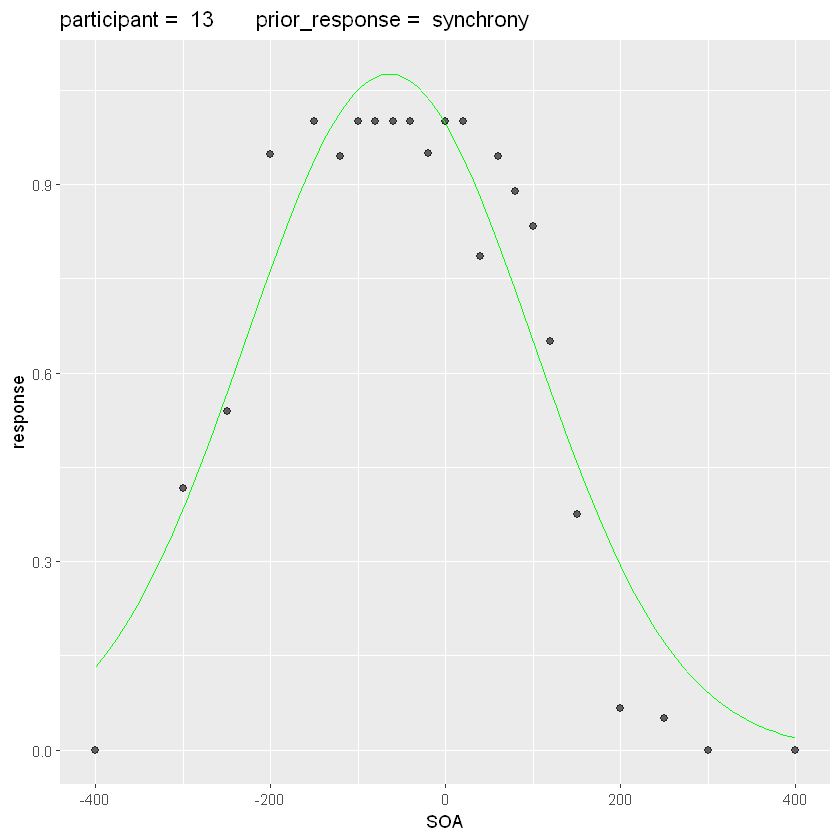

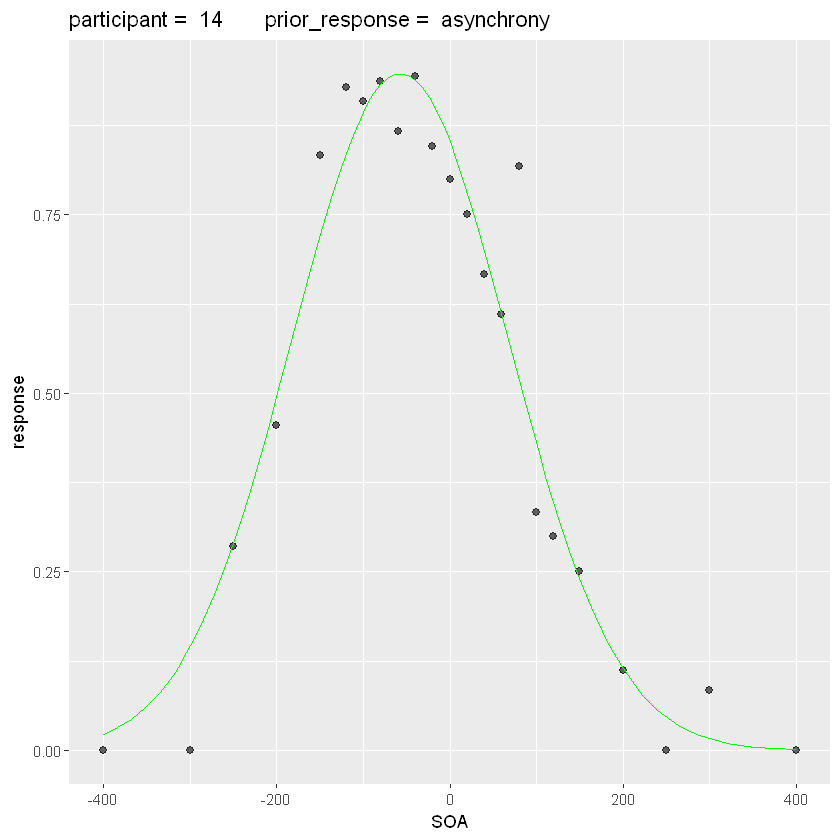

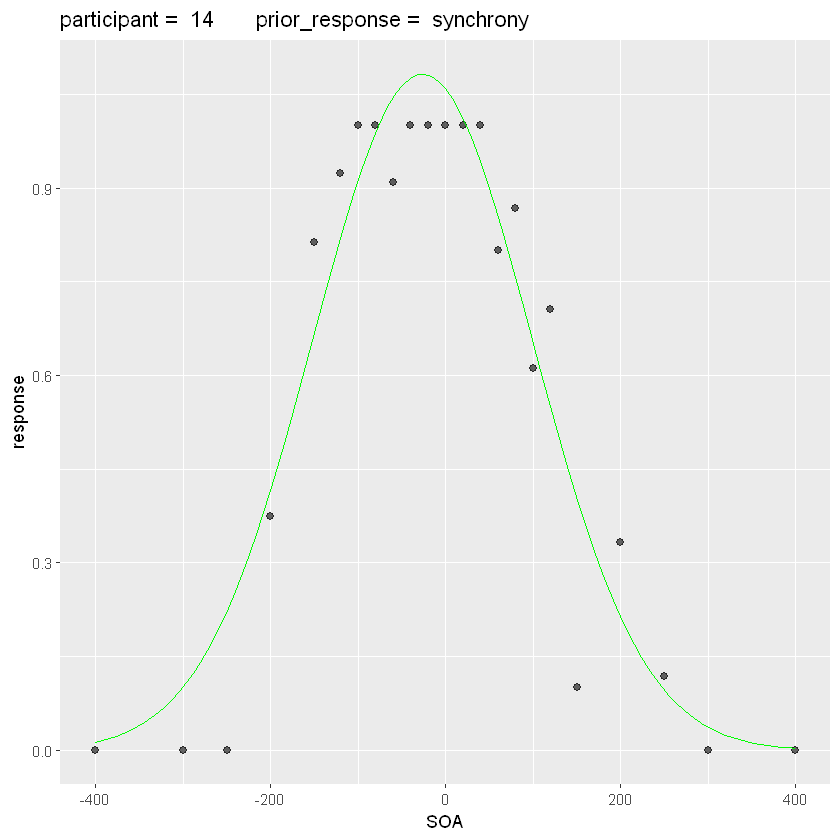

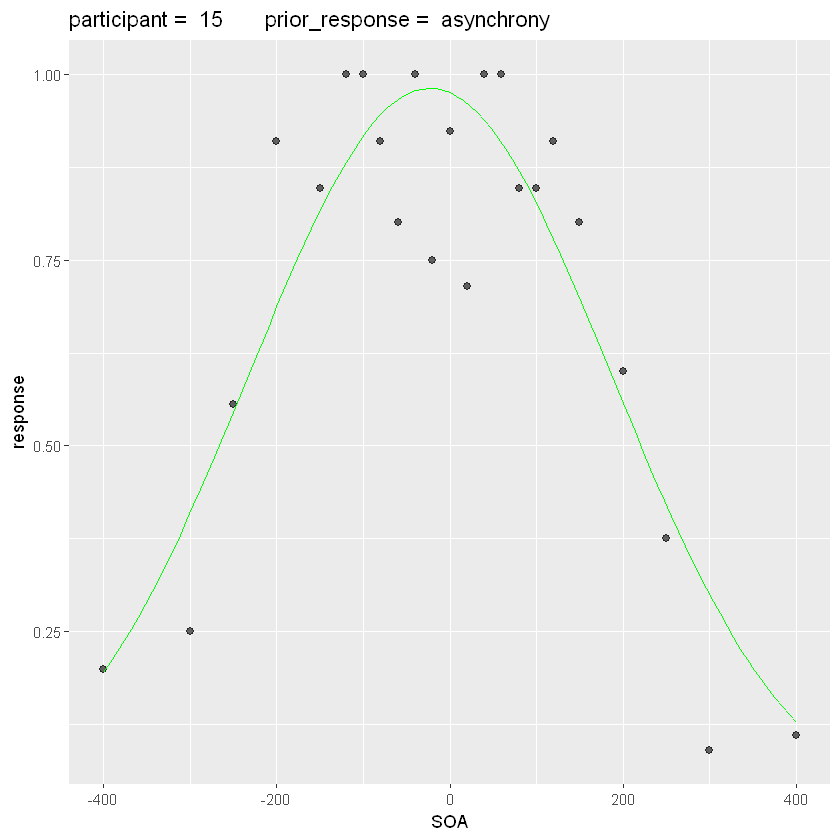

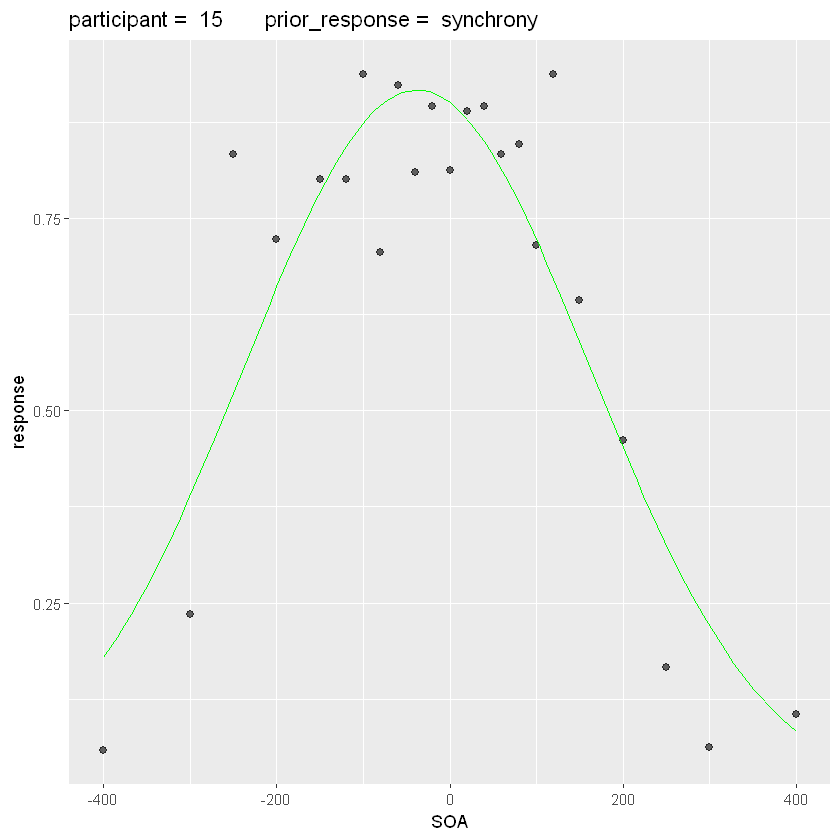

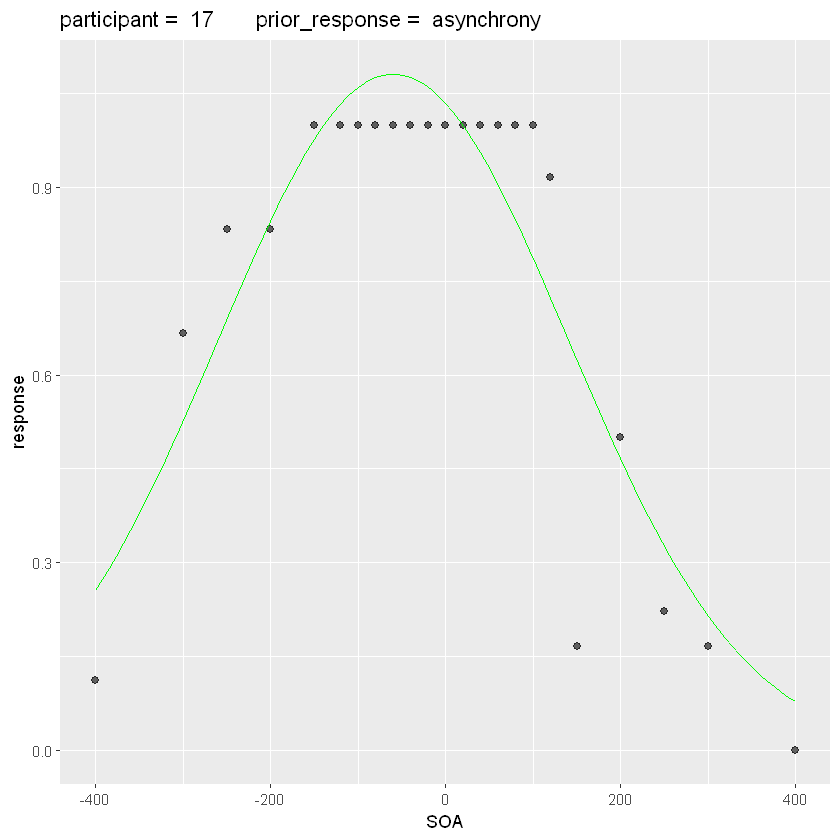

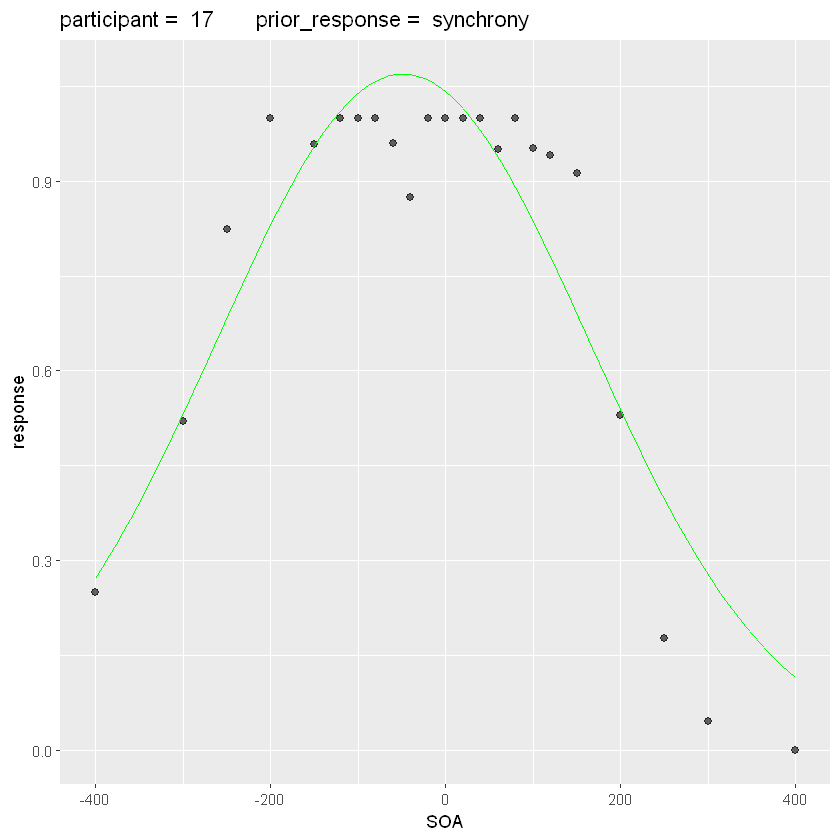

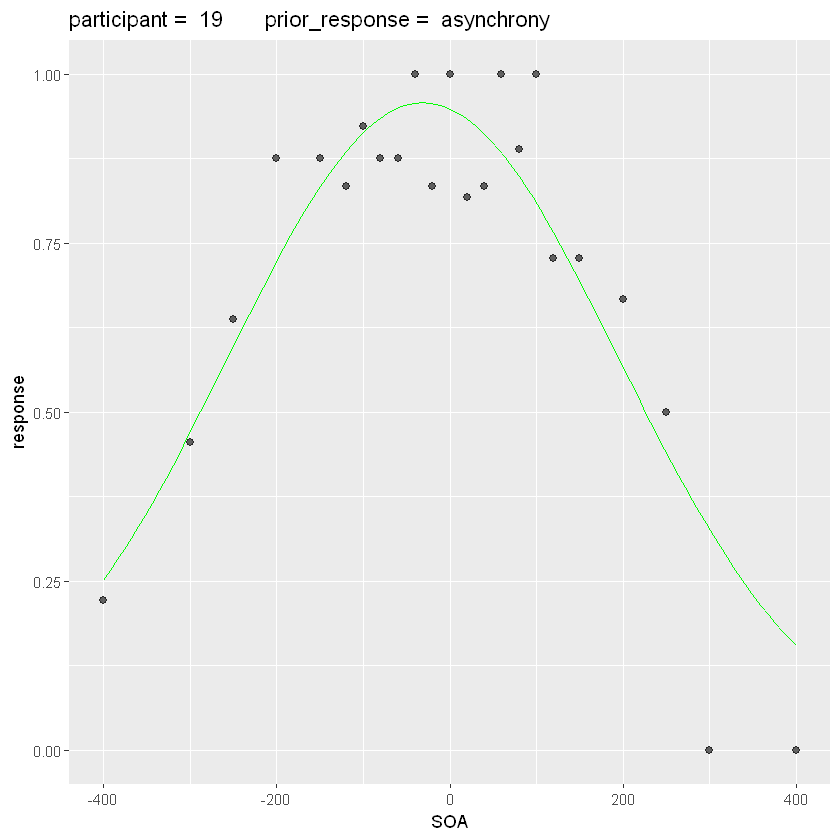

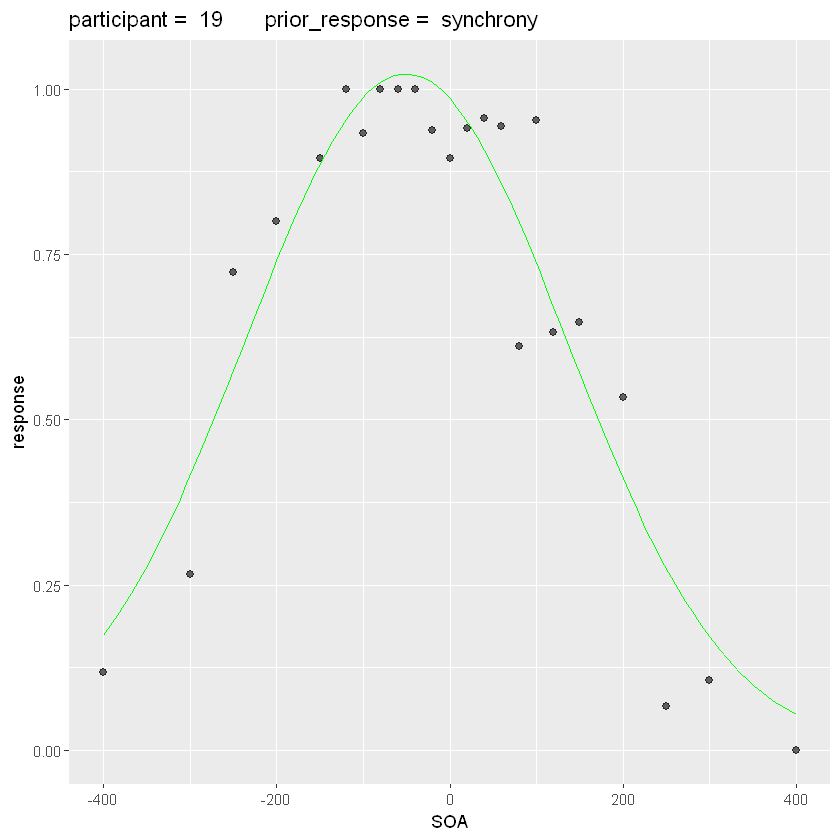

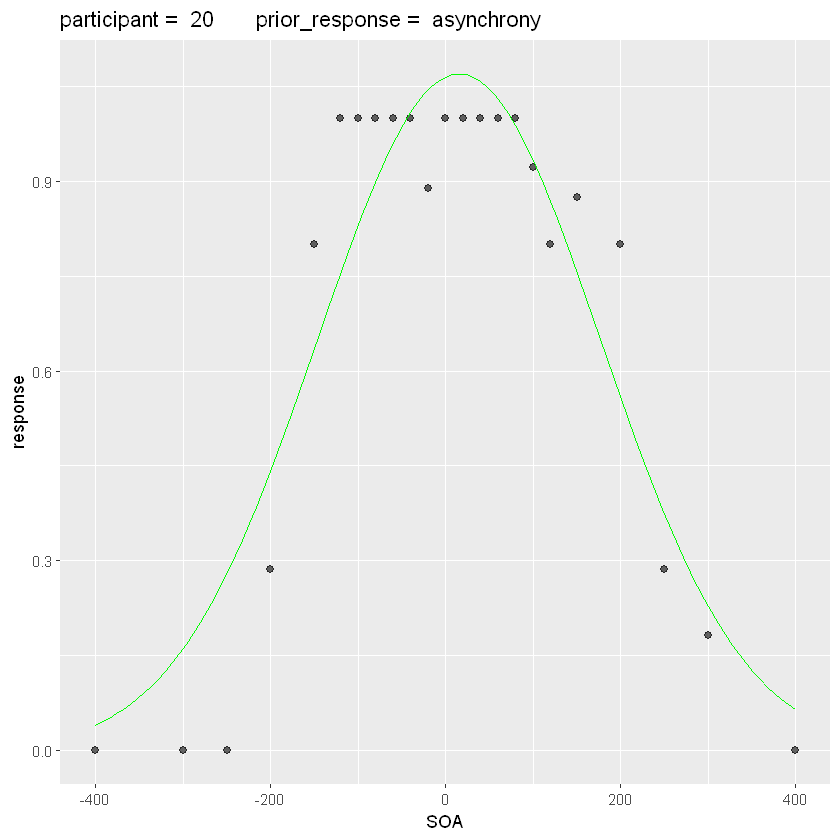

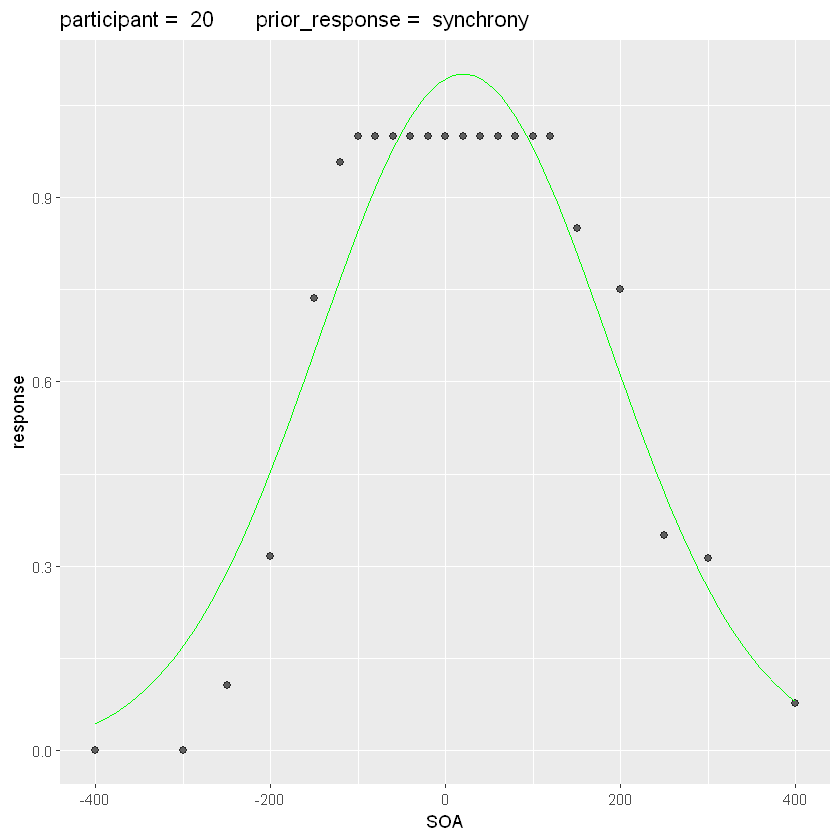

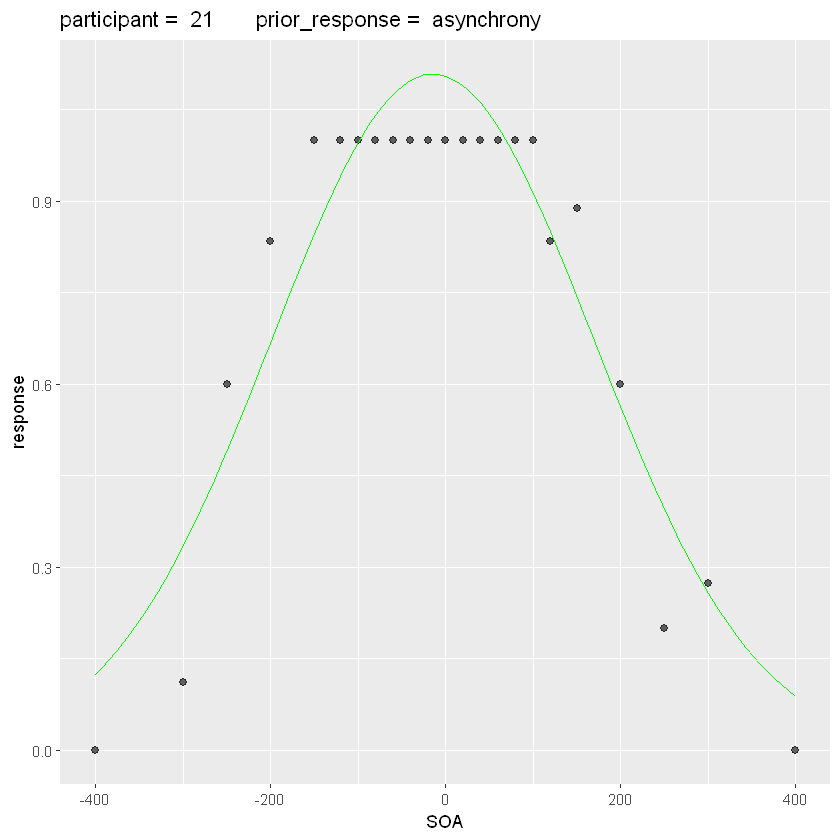

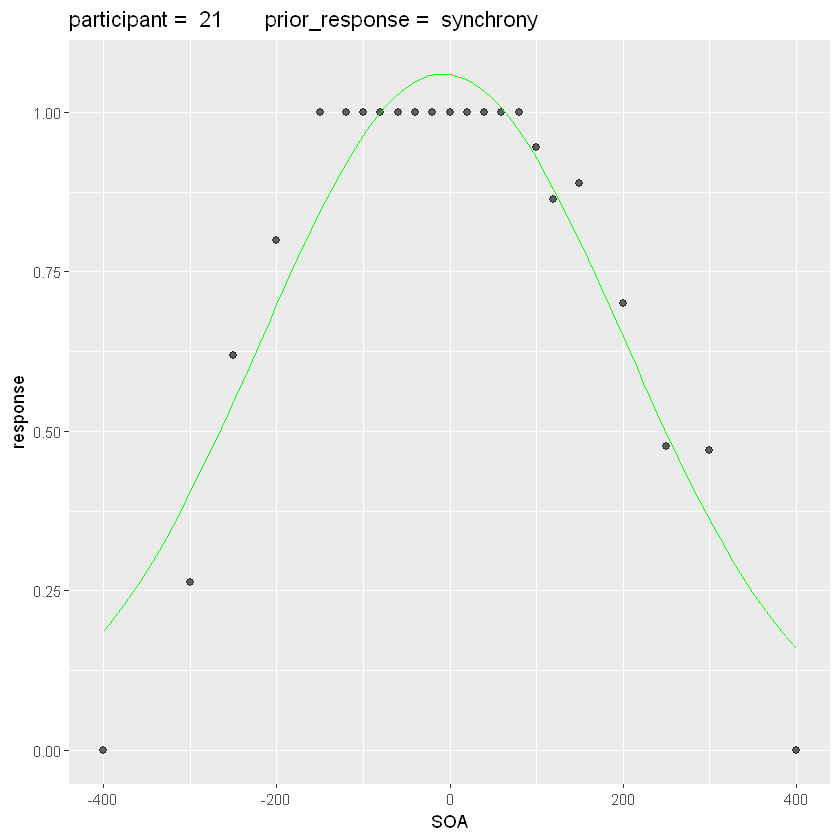

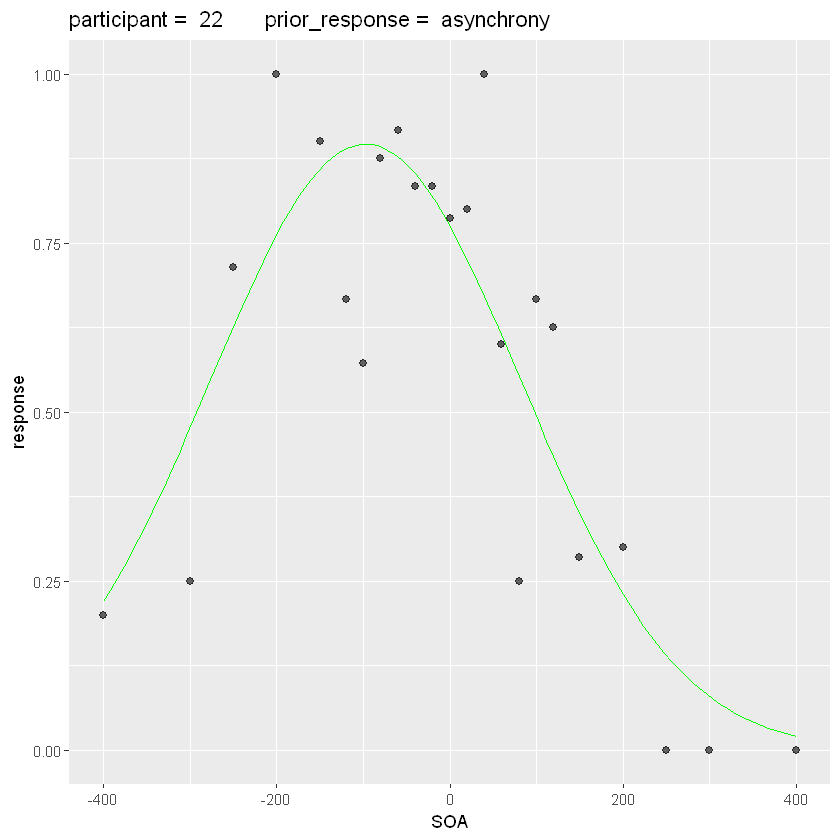

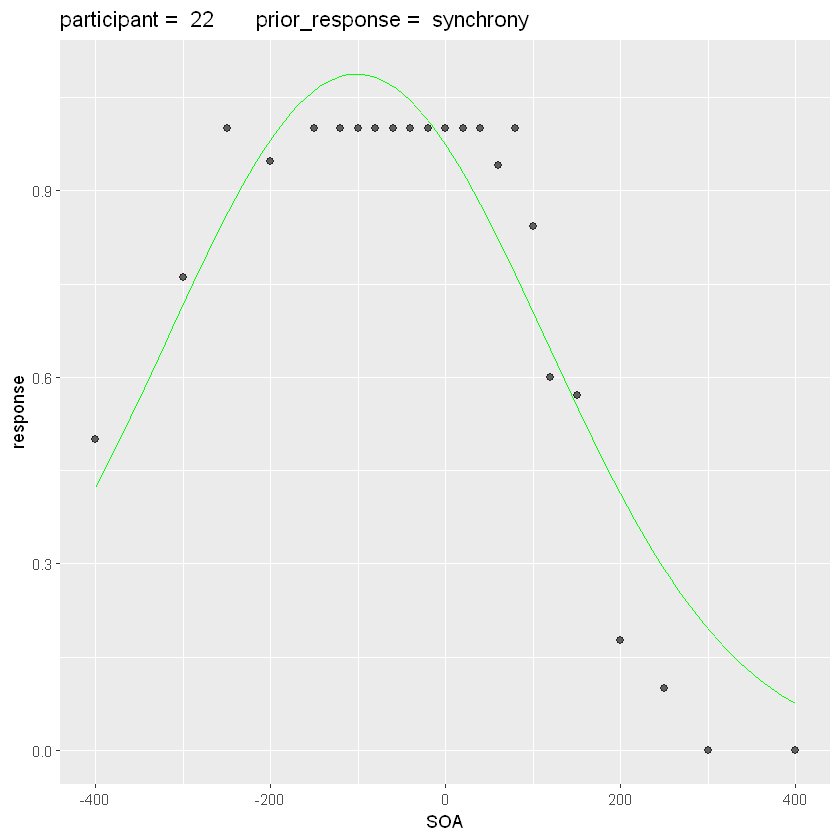

In [134]:
ff <- function(x,amp,pss,sd){
    amp * exp(-(x - pss)^2 / (2 * sd^2))
}

data_mean <- data %>% group_by(participant, pre_resp, SOA) %>%   
    summarise(
                response = mean(resp == 1),
                n_trials = n(),
                .groups = "drop"
              )

for(subj in unique(data$participant)){

    d1 <- data_mean %>% filter(participant == subj)
    # print(subj)
    for(pr in unique(data$pre_resp)){
        d2 <- d1 %>% filter(pre_resp == pr)
        # print(ps)

        amp <- (results %>% filter(participant == subj) %>% filter(pre_resp == pr))$amp
        pss <- (results %>% filter(participant == subj) %>% filter(pre_resp == pr))$pss
        sd <- (results %>% filter(participant == subj) %>% filter(pre_resp == pr))$sd
        print(ggplot(d2, aes(x = SOA, y = response)) +
                geom_point(size = 2, alpha = 0.6) +
                geom_function(fun=ff, args = list(amp = amp, pss = pss, sd = sd), color='green') +
                labs(title = paste('participant = ',subj,'      prior_response = ',pr)))
            
}}

In [73]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){

  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)

  return(1 - SS_res / SS_tot)

}

results$R2 <- NA

for(i in 1:nrow(results)){

    id <- results$participant[i]
    pr <- results$pre_resp[i]

  subdata <- data_mean %>% filter(participant == id) %>% filter(pre_resp == pr)

  pred <- ff(subdata$SOA, results$amp[i], results$pss[i], results$sd[i])

  results$R2[i] <- R2(subdata$response, pred)

}

head(results)

,participant,pre_resp,amp,pss,sd,R2
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,asynchrony,1.0553454,-15.28888,159.5136,0.9073527
2,1,synchrony,1.0747713,-25.58561,181.3664,0.9039516
3,3,asynchrony,0.6802101,-70.90235,156.3591,0.8456594
4,3,synchrony,0.7044108,-66.91638,133.5371,0.7610064
5,4,asynchrony,0.5508617,-108.94569,209.3420,0.7727101
6,4,synchrony,0.8299979,-63.59123,192.8187,0.8355972


In [75]:
sort(results$R2)

[1] 0.5204219 0.5810579 0.5929330 0.6135641 0.7610064 0.7727101 0.7732043
 [8] 0.7819332 0.7887456 0.8115382 0.8182339 0.8199487 0.8221591 0.8355972
[15] 0.8392372 0.8432240 0.8456594 0.8544509 0.8611031 0.8639797 0.8668350
[22] 0.8690569 0.8732926 0.8743290 0.8925936 0.8939045 0.9024488 0.9039516
[29] 0.9042920 0.9045864 0.9073527 0.9098932 0.9115751 0.9144073 0.9248777
[36] 0.9248860 0.9268777 0.9336562 0.9376557 0.9414819 0.9442511 0.9463509

In [76]:
results %>% filter(R2<.7) %>% arrange(R2)

participant,pre_resp,amp,pss,sd,R2
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
7,asynchrony,0.7618324,59.5883329,269.7584,0.5204219
6,synchrony,0.5886924,-0.4529653,188.5889,0.5810579
18,asynchrony,0.8857965,-4.7866936,320.2709,0.5929330
7,synchrony,0.8668637,71.3316224,385.2953,0.6135641


In [74]:
###############################################################
# Exclude participants with poor psychometric fits
# Criterion: R² < 0.50
###############################################################

results %>% filter(R2<.5)

participant,pre_resp,amp,pss,sd,R2
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>


In [77]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){

  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)

  return(1 - SS_res / SS_tot)

}

results$R2 <- NA

for(i in 1:nrow(results)){

    id <- results$participant[i]
    pr <- results$pre_resp[i]

  subdata <- data %>% filter(participant == id) %>% filter(pre_resp == pr)

  pred <- ff(subdata$SOA, results$amp[i], results$pss[i], results$sd[i])

  results$R2[i] <- R2(subdata$resp, pred)

}

head(results)

,participant,pre_resp,amp,pss,sd,R2
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,asynchrony,1.0553454,-15.28888,159.5136,0.5984794
2,1,synchrony,1.0747713,-25.58561,181.3664,0.6110673
3,3,asynchrony,0.6802101,-70.90235,156.3591,0.2189692
4,3,synchrony,0.7044108,-66.91638,133.5371,0.2730107
5,4,asynchrony,0.5508617,-108.94569,209.3420,0.1167899
6,4,synchrony,0.8299979,-63.59123,192.8187,0.2825823


In [78]:
sort(results$R2)

[1] 0.08489716 0.10566956 0.11678994 0.12291691 0.12418099 0.13870532
 [7] 0.21624331 0.21896918 0.27301070 0.27515970 0.28258233 0.31884943
[13] 0.33866346 0.35740817 0.36293911 0.36587408 0.36809910 0.37965421
[19] 0.38701249 0.39792468 0.40027014 0.40391083 0.41936867 0.42317267
[25] 0.47609617 0.48716881 0.49450417 0.49849810 0.54618727 0.55844727
[31] 0.57079670 0.57590365 0.59342481 0.59847943 0.59926500 0.61106732
[37] 0.64521623 0.65128831 0.65196754 0.65278262 0.65739942 0.65825213

In [79]:
results %>% filter(R2<.2) %>% arrange(R2)

participant,pre_resp,amp,pss,sd,R2
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
7,synchrony,0.8668637,71.3316224,385.2953,0.08489716
6,asynchrony,0.4513118,15.2106189,147.3116,0.10566956
4,asynchrony,0.5508617,-108.9456924,209.3420,0.11678994
6,synchrony,0.5886924,-0.4529653,188.5889,0.12291691
18,asynchrony,0.8857965,-4.7866936,320.2709,0.12418099
7,asynchrony,0.7618324,59.5883329,269.7584,0.13870532


In [80]:
quadratic_results <- data.frame()
for (par in unique(data$participant)) {
    df_subset1 <- data_mean %>% filter(participant == par)
    for(pr in unique(data$pre_resp)){
        df_subset2 <- df_subset1 %>% filter(pre_resp == pr)
        fit <- lm(response ~ SOA + I(SOA^2), data = df_subset2)
        quadratic_results <- rbind(quadratic_results, data.frame(
                participant = par,
                p = summary(fit)$coefficients[3,4]))
        
}}

In [81]:
sort(quadratic_results$p)

[1] 1.250752e-15 1.345249e-14 2.209138e-14 8.278773e-13 2.248697e-11
 [6] 4.103327e-11 5.657754e-11 1.223435e-10 3.383869e-10 9.708463e-10
[11] 1.074847e-09 1.454980e-09 2.090999e-09 2.955712e-09 4.968240e-09
[16] 6.903419e-09 8.500402e-09 1.250218e-08 1.851316e-08 2.450717e-08
[21] 3.106317e-08 3.884262e-08 4.278013e-08 5.484135e-08 8.409480e-08
[26] 9.789244e-08 1.162099e-07 1.774152e-06 2.204229e-06 4.510373e-06
[31] 4.785912e-06 4.847556e-06 7.277272e-06 1.080465e-05 1.603731e-05
[36] 1.681648e-05 1.974344e-05 2.217283e-05 2.220751e-05 3.723601e-05
[41] 1.395726e-04 1.945667e-04

In [82]:
quadratic_results[quadratic_results$p> 10^-04,]

,participant,p
,<dbl>,<dbl>
4,3,0.0001395726
11,7,0.0001945667


In [83]:
quadratic_results <- data.frame()
for (par in unique(data$participant)) {
    df_subset1 <- data %>% filter(participant == par)
    for(pr in unique(data$pre_resp)){
        df_subset2 <- df_subset1 %>% filter(pre_resp == pr)
        fit <- lm(resp ~ SOA + I(SOA^2), data = df_subset2)
        quadratic_results <- rbind(quadratic_results, data.frame(
                participant = par,
                p = summary(fit)$coefficients[3,4]))
        
}}

In [84]:
sort(quadratic_results$p)

[1] 1.893819e-81 1.186507e-80 1.929270e-74 7.728949e-74 5.553009e-73
 [6] 3.929381e-69 1.037044e-59 1.345395e-56 7.378185e-52 1.114942e-51
[11] 1.330249e-47 1.420035e-46 4.806979e-43 5.436055e-41 3.312786e-38
[16] 1.704050e-37 4.677397e-37 1.400728e-35 1.202670e-33 3.375291e-29
[21] 6.476310e-28 6.363587e-27 3.170024e-25 5.920237e-24 2.846728e-22
[26] 4.389136e-22 6.304902e-22 1.678435e-19 3.840622e-19 7.070076e-19
[31] 1.281067e-18 5.252455e-18 7.723166e-18 1.505871e-17 2.550403e-16
[36] 1.760587e-09 2.511106e-09 2.220117e-08 1.137150e-06 1.331727e-06
[41] 2.045758e-06 5.025466e-05

In [85]:
quadratic_results[quadratic_results$p> 10^-08,]

,participant,p
,<dbl>,<dbl>
5,4,1.137150e-06
10,6,2.045758e-06
11,7,1.331727e-06
12,7,2.220117e-08
33,18,5.025466e-05


In [135]:
write_xlsx(results, "files2/SJ_prior_response_psychometric_parameters.xlsx")